# Final Project: OHIE Medicaid Policy Simulation
---

**Project Name:** Allocating Scarce Medicaid Coverage: A Counterfactual Comparison of Lottery, Need-Based, and Learned Targeting in the Oregon Health Insurance Experiment

**Author:** Chayce Reed

**Date:** 10/18/26

<br>

### Purpose
---

This notebook asks how a fixed number of Medicaid offers should be allocated, using the Oregon Health Insurance Experiment (OHIE) Public Use Data. It covers data selection, cleaning, and exploration, followed by supervised machine learning classification, causal inference, heterogeneity analysis, and a policy simulation.

The classification section trains and compares three classifiers (logistic regression, random forest, XGBoost) for predicting medical debt at 12 months, using household-grouped cross-validation, hyperparameter tuning, and out-of-fold evaluation. The causal section estimates the effect of a lottery offer (ITT, via weighted OLS, g-computation, and AIPW) and of Medicaid enrollment among compliers (LATE, via 2SLS) on four financial strain outcomes. The heterogeneity section fits a cross-fitted causal forest and tests whether the effect varies across subgroups, using a calibration test and prespecified subgroups. The policy simulation holds the number of offers fixed at the lottery's budget adn comapres five allocation rules (lottery, need-based, risk-based, benefit-based, universal) on how much medical debt each would avert, with doubly robust evaluation, a household bootstrap, and a sweep across budget levels.

<br>

### Data Source
---

**Data Source:** Oregon Health Insurance Experiment (OHIE) Public Use Dataset

**Data Access:** https://www.nber.org/research/data/oregon-health-insurance-experiment-data (Free registration, if prompted)

**Data Description:** "In 2008, a group of uninsured low-income adults in Oregon was selected by lottery to be given the chance to apply for Medicaid. This lottery provides a unique opportunity to gauge the effects of expanding access to public health insurance on the health care use, financial strain, and health of low-income adults using a randomized controlled design. The Oregon Health Insurance Experiment followed and compared those selected in the lottery (treatments) with those not selected (controls)."

**Data Files:** The dataset includes six separate datasets from the OHIE that have been made pubiicly available. For this project, the following datasets will be used: Descriptive Variables (oregonhie_descriptive_vars.dta), State Program Variables (oregonhie_stateprograms_vars.dta), and Tweleve Month Mail Survey (oregonhie_survey12m_vars.dta).

**Data Selection:** The OHIE dataset was selected for this project because it provides a unique opportunity to analyze the effects of Medicaid coverage on low-income adults in Oregon. The experiment's randomized "lottery" design allows for the comparison between those who were selected for Medicaid coverage and those who were not, making it a useful dataset for studying the impact of health insurance on various outcomes. This dataset also lines up directly with my research interests and goals. I am applying to PhD programs to study causal inference for health services, policy, and equity research, across two key areas: how health policy and health care delivery systems shape access for marginalized populations, and how automated decision-making produces and entrenches disparities in health care. This dataset and project fits squarely into the former, and will allow me to investigate how coverage decisions affect low-income, uninsured populations and how those decisions could be made more equitably. The data includes characteristics recorded before the lottery, which makes it possible to estimate the causal effect of a coverage offer, test whether the effect differs across subgroups, and simulate whether an alternative allocation rule (e.g., need-based, learned-targeting) would have prevented more medical debt than the lottery. This combination of causal inference, policy simulation, and equity analysis is the kind of work I am hoping to develop my future PhD research agenda around, which makes it a very exciting dataset and project to work on.

**Binary Classification:** Yes. The target whether the respondent owes money for medical expenses at 12 months (binary: 1 = yes, 0 = no).

**Observation Count:** 23,741 respondents to the 12-month survey, out of 74,922 total people on the original lottery list.

**Predictor Variable Count:** 15 predictor variables measured before the lottery, including: age, sex, english-language preference, self-signup, phone number provided, PO box addressed used, metro-area zip, signup week, first-day signup, last-day signup, prior SNAP participant, prior TANF participant, household SNAP dollars, household TANF dollars, and any-state program indicator.

**Acknowledgements:** The project uses the public-use data from the Oregon Health Insurance Experiment, made available by the National Bureau of Economic Research (NBER). Finkelstein, Amy. Oregon Health Insurance Experiment Public Use Data, 2013. Available at https://www.nber.org/research/data/oregon-health-insurance-experiment-data.

<br>

### Data Quality Assessment
---

**Preprocessing Steps:**

- Merged the three datasets (descriptive, state program, and 12-month survey) into a single dataset for analysis.
- Restricted dataset to the 23,741 respondents who completed the 12-month survey.
- Renamed variables to shorter, more interpretable names and built a label dictionary mapping each to its readable description for tables and plots.
- Converted object-type columns to the appropriate numeric or categorical type, and cast binary outcomes as nullable integers to preserve missingness.
- Derived age from birth year and the 2008 survey year, grouped age into bands for the subgroup analysis, and created indicators for female, English-language preference, and any prior SNAP / TANF participation.
- Ran automated data quality checks (missingness, expected data types, validity rules on value ranges, unique person ID) that print pass/fail result for each, so any problem is visible in the output before modeling.
- Dropped any_program_pre from the predictor set, since it is nearly identical to snap_pre (Spearman correlation 0.999) and would add no additional information.
- One-hot encoded household size and survey wave, and standardized continuous predictors inside the logistic regression pipeline.
- Applied survey weights to descriptive statistics and causal estimates, and clustered standard errors by household.

**Challenges with the Dataset & How They Were Handled:**

- Offers vs coverage: Winning the lottery gave people the chance to apply for Medicaid coverage, but doesnt guarentee they were enrolled. This means that the treatment group (selected in the lottery) may include people who were not actually covered by Medicaid. To address this challenge, the primary analysis estimates intention-to-treat effect of an offer, and a secondary 2SLS analysis uses the lottery as an instrument to estimate the effect of enrollment among compliers.
- Survey non-response: Only 23,741 of the 74,922 people on the original lottery list completed the 12-month survey. Respondents may differ systematically from non-respondents, so the survey weights provided with the data were applied to all estimates to keep them representative of the full lottery list.
- Unequal selection probability: Households with more members had more lottery draws, and the survey fielded in waves tied to seven drawings, so the offer rate varied from 0.35 to 0.92 across household-size by wave cells. All causal models condition on household size by wave fixed effects, and within-cell offer rate serves as the known propensity score for AIPW.
- Household clustering: Selection was at the household level and household members share outcomes, so cross-validation folds were grouped by household to prevent leakage and all standard errors were clustered by household.

<br>

### Project Stages
---

**Data Preparation:**

- Load the three OHIE State files (descriptive, state programs, 12-month survey), merge on person ID, and restrict to 12-month survey respondents.
- Rename variables, derive age, age group, and prior SNAP/TANF indicators.
- Check for missingness, implausible values, and duplicate IDs, and verify the lottery selection is balanced across design strata.

**Outcomes:**

- The primary outcome is medical_debt, defined as "Currently owe money for medical expenses" at the 12 month follow-up survey.
- Three secondary outcomes capture related financial strain: cost_borrow_12m, cost_refused_12m, and cost_any_oop_12m, which represent "Borrowed money/skipped bills to pay health care bills in last 6 months?", "Have you been refused care because you owed money for a past treatment?", "Any out of pocket costs for medical care in the past 6 months", respectively. All four outcomes are binary (binary: 1 = yes, 0 = no).
- Unweighted rates in the full sample are approximately 55% of all respondents reported having medical debt, 34% reported borrowing money or skipping bills to pay health care bills, 7% reported being refused care due to medical debt, and 52% reported out of pocket costs for medical care in the last 6 months. Survey-weighted rates in the control arm are 60%, 37%, 8%, and 56%, respectively.

**Prediction:**

- Binary classification: predict whether a low-income, uninsured adult will owe money for medical expenses 12 months after applying for Medicaid, and which variables are the most predictive of that outcome.
- Inputs are characteristics recorded at signup (e.g., age, sex, language preference, prior state program participation, etc), plus whether the person was selected in the lottery.
- Logistic regression, random forest, and XGBoost are tuned by household-grouped cross-validation.
- Compared on out-of-fold performance on the following criteria:
  - AUC: how well each model discriminates between those who owe money for medical expenses and those who do not.
  - Brier Score: how well each model predicts the probability of owing money for medical expenses.
  - Calibration curves: how closely predicted probabilities match observed outcome rates.
  - Sensitivity: the share of respondents with medical debt the model flags (the priority metric since missing someone with debt is the costlier error)
- Variable importance is assessed by standardized coefficients, perumation importance, and SHAP.
- The classifier's out-of-fold predictions will then be feed into the risk-based allocation rule in the policy simulation stage.

**Causal Inference:**

- Estimate the effect of a Medicaid offer (intention-to-treat) on each outcome by weighted OLS with fixed effects.
  - Replication check: the ITT is compared against the published OHIE estimates before any downstream analysis builds on it.
- Estimate the effect of enrollment among compliers (LATE) by 2SLS with the lottery as the instrument.
- Replicate the ITT with g-computation and AIPW to confirm the result agrees across estimators.
- All models use survey weights and household-clustered standard errors.

**Heterogeneity:**

- Fit a cross-fitted causal forest to estimate individual treatment effects.
- Test whether the predicted heterogeneity is real using a calibration test and sorted-group effects against the AIPW scores.
- Estimate prespecified subgroup effects by age gorup, sex, language preference, and prior SNAP/TANF participation.

**Policy Simulation:**

- Fix the budget at the lottery's offer count, so every rule hands out the same number of offers (with the exception of universal coverage), and compare five allocation rules:
  - Lottery: random allocation, reproducing the original OHIE design.
  - Need-based: offers ranked by prior SNAP / TANF dollars
  - Risk-based: offers ranked by predicted probability of medical debt without coverage, from the XGBoost classifier.
  - Benefit-based: offers ranked by the causal forest's predicted individual treatment effect.
  - Universal: no budget, everyone offered coverage
- Evaluate each with the doubly robust scores and cross-check with g-computation.
- Bootstrap by household for uncertainty in each rule's gain over the lottery
- Budget sweep from 10% to 100%.

**Summary:**
- Report main results, limitations, and conclusions.

<br>

### Notebook Structure
---

- **1. Setup**
  - 1.1. Package Version Check & Installation
  - 1.2. Package Importing & Seed Setting
  - 1.3. File Path Creation & Locating Data
  - 1.4. Visualization Palette & Theme
- **2. Data Loading & Merging**
  - 2.1. Data Loading
  - 2.2. Data Subsetting & Merging
  - 2.3. Variable Renaming & Labeling
  - 2.4. Derived Variables
  - 2.5. Data Subsetting & Variable Grouping
- **3. Data Structure & Loading**
  - 3.1. Data Structure, Type, & View
- **4. Data Checks & Cleaning**
  - 4.1. Data Checks Functions
  - 4.2. Data Checks
  - 4.3. Data Cleaning
- **5. Data Exploration & Visualization**
  - 5.1. Summary & Visualization Functions
  - 5.2. Descriptive Statistics
  - 5.3. Treatment Group Comparisons
  - 5.4. Distribution Visualizations
  - 5.5. Outcomes by Treatment Groups
  - 5.6. Subgroup Analysis
  - 5.7. Predictor Correlation Matrix & Heatmap
- **6. Supervised Machine Learning Classification**
  - 6.1. Design Matrix & Cross-Validation Folds
  - 6.2. Logistic Regression
  - 6.3. Random Forest
  - 6.4. XGBoost
  - 6.5. Out-of-Fold Predictions
  - 6.6. Threshold Selection
  - 6.7. Performance Metrics & Overfit Check
  - 6.8. ROC & Calibration Curves
  - 6.9. Confusion Matrices
  - 6.10. Variable Importance
- **7. Causal Inference**
  - 7.1. Propensity Scores
  - 7.2. Covariate Balance Check
  - 7.3. Intention-to-Treat (ITT): OLS
  - 7.4. Local Average Treatment Effect (LATE): 2SLS
  - 7.5. G-Computation
  - 7.6. AIPW
  - 7.7. Summary of Causal Estimates
- **8. Heterogeneity & Subgroup Analysis**
  - 8.1. Causal Forest
  - 8.2. CATE Distribution
  - 8.3. Calibration Test & GATES
  - 8.4. Subgroups Analysis: Age Group, Sex, Language, Prior SNAP/TANF
  - 8.5. Forest Feature Importance
- **9. Policy Simulation**
  - 9.1. Determine Fixed Budget
  - 9.2. Allocation Rules: Lottery, Need-Based, Risk-Based, Universal
  - 9.3. Doubly Robust Evaluation of Each Rule using AIPW
  - 9.4. G-Computation Cross-Check
  - 9.5. Household Bootstrap for Uncertainty Estimation
  - 9.6. Budget Sweep & Summary
  - 9.7. Subgroup Analysis of Allocation Rules
- **10. Summary & Limitations**
  - 10.1. Results
  - 10.2. Assumptions
  - 10.2. Limitations
  - 10.3. Conclusions

<br>

### How To Run
---

1. Open the notebook in Google Colab.
2. Download the OHIE public-use data from NBER: https://www.nber.org/research/data/oregon-health-insurance-experiment-data. Registration is free. The file is `oregon_puf.zip`.
3. Run the notebook using `Run all`. The setup step will automatically install required packages. When the data location step runs, a "Choose Files" button appears below the cell; click it and select `oregon_puf.zip`. Alternatively, drag the zip into the Files panel (folder icon, left sidebar) before running, and the notebook will find automatically. The notebook will unzip the zip file and locate the appropriate `.dta` files automatically.

<br>

Note: When running this notebook in Google Colab, the random forest and XGBoost hyperparameter tuning may take several minutes to complete. It takes approximately 15 minutes for the notebook to run end-to-end.

<br>

## 1. Setup

---

Specifies the package versions the notebook was built with, installs the ones Colab doesn't have preinstalled, sets the random seed, locates the data and output folders, and defines the color palette and plot theme used by every figure.

---

This section contains:
- 1.1. Package Version Check & Installation
- 1.2. Package Importing & Seed Setting
- 1.3. File Path Creation & Locating Data
- 1.4. Visualization Palette & Theme


#### 1.1. Package Version Check & Installation

In [387]:
# Load internal python libraries needed for package version checks and installations
import importlib.metadata as md
import platform
import subprocess
import sys

# Python version this notebook was built and tested with
# Unable to change the python runtime version in google colab,
# An idea for the final project is to provide a dockerfile, so that an the full/exact environemnt can be rebuilt and rerun outside of Colab
PYTHON_VERSION = "3.13.16"
# Packages not preinstalled on the Colab environment, which can specify and install specific versions for on the Colab environment
PACKAGE_VERSION = {
    "pyreadstat": "1.3.6",
    "linearmodels": "7.0",
    "xgboost": "3.4.1",
    "econml": "0.17.0",
    "shap": "0.52.0"
}
# Preinstalled packages on the Colab environment already, changing the versions during runtime risks creating downstream issues if versions change
PREINSTALLED_PACKAGEs = ["pandas", "numpy", "scipy", "matplotlib", "seaborn", "scikit-learn", "statsmodels", "operator", "sklearn"]

# Check current google colab environment python version, and print message to notify user if it is not the same version the notebook was built and tested with
if not platform.python_version().startswith(PYTHON_VERSION):
    print(f"Note: Notebook built and tested on Python {PYTHON_VERSION}, but environment is currently running {platform.python_version()}.")

# Note: For learning how to improve on my previous versions package version installation workflow
  # Claude Fable 5. Based on the response to prompt: "What is the best practice approach for installing specific version of python packages in the Google Colab environment."
# Lets create a function for checking if a package is already installed, and returning the version number if it is
def installed_version(pkg):
    """Check if package is installed.
    If installed, return version number
    If not installed, return None
    """
    try:
        return md.version(pkg)
    except md.PackageNotFoundError:
        return None

# Create a list of packages to install if packages are not already installed or are not the appropriate version
to_install = [f"{p}=={v}" for p, v in PACKAGE_VERSION.items() if installed_version(p) != v]

# Check if any packages need to be installed, if so, install the appropriate version
if to_install:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + to_install, check = True)

#### 1.2. Package Importing & Seed Setting

In [388]:
# Standard python libraries
import zipfile
from pathlib import Path
from operator import lt, le, eq, ge, gt
import copy
import textwrap

# Data handling
import numpy as np
import pandas as pd
import pyreadstat

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Supervised machine learning classification
from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score, brier_score_loss, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from scipy.special import logit
from xgboost import XGBClassifier
import shap

# Causal inference
import statsmodels.api as sm
import statsmodels.formula.api as smf
from linearmodels.iv import IV2SLS
from econml.grf import CausalForest


In [389]:
# Set seed for reproducibility
SEED = 123
rng = np.random.default_rng(SEED)

#### 1.3. File Path Creation & Locating Data

In [390]:
# Lets define the filepaths for our raw dataset and outputs
INPUT = Path("data/raw")
OUTPUT = Path("output/figures")

# Now, lets create the directories themselves
INPUT.mkdir(parents = True, exist_ok = True)
OUTPUT.mkdir(parents = True, exist_ok = True)

In [391]:
# Lets create a function to:
#   (1) check if the data exists in the current environment
#   (2) if exists and is a zip, unpack it
#   (3) if exists and is already unpacked, do nothing
#   (4) if it does not exist, prompt user to upload, using google.colab files to display a popup for easy upload
# Note: To learn how to search the Google Colab environment for appropriate files, and if a zip is found, unpack it
  # Claude Fable 5. Based on the response to prompt: "I want to be able to locate if a zip exists anywhere in the current Colab environment, and if so, unpack it.
  # Additionally, if the zip is already unpacked and the dta files already exist, then use those. If no zip or dta files are found, I want to prompt to the user to upload them."
def locate_data():
    """Check for OHIE zip (or extracted .dta files), and prompt if they are not already present"""
    # First, lets check if the dta files are already present (files uploaded and zip already unpacked)
    if list(Path(".").rglob("oregonhie_*.dta")):
      return
    zips = list(Path(".").rglob("*.zip"))
    if zips:
      zipfile.ZipFile(zips[0]).extractall(INPUT)
      return
    # Neither zip nor dta were found, prompt for upload
    # Inlcuding this here allows us to only import the google.colab files package if its actually needed
    from google.colab import files
    # Prompt to the user to upload the zip file
    print("Upload oregon_puf.zip from the NBER page linked above.")
    # Check each uploaded file to see if it is a zip, if so, unpack it
    for name in files.upload():
        if name.endswith(".zip"):
            zipfile.ZipFile(name).extractall(INPUT)

# Run the function above
locate_data()
# Identify all dta files
dta_files = sorted(Path(".").rglob("oregonhie_*.dta"))
# Flag to user if dta files are not found, prompting user to upload the zip file
assert dta_files, "No oregonhie_*.dta files found: upload oregon_puf.zip from the NBER page linked above."
# Once files are uploaded and found, print and display all found data files to user
print("Data files found:", *[f.name for f in dta_files], sep = "\n")

Data files found:
oregonhie_descriptive_vars.dta
oregonhie_ed_vars.dta
oregonhie_inperson_vars.dta
oregonhie_patterns_vars.dta
oregonhie_stateprograms_vars.dta
oregonhie_survey0m_vars.dta
oregonhie_survey12m_vars.dta
oregonhie_survey6m_vars.dta


#### 1.4. Visualization Palette & Theme

In [392]:
# Create a color pallete for the notebook
PALETTE = ["#0164c1", "#1baf7a", "#eb2e2e", "#eda100", "#6250d6"]
# Map colors per role (e.g., treatment, primary, control, reference)
# These are reused throughout the entire notebook for visualizations, making the colors dynamic and making it easy colors for all visualizations from a single point
COLORS = {"primary": PALETTE[0], "secondary": PALETTE[1], "tertiary": PALETTE[2], "treatment": PALETTE[0], "control": "#c1c1c1ff", "reference": "#555555"}
# Colormap for the heatmap
COLORMAP = sns.blend_palette([PALETTE[0], "white", PALETTE[2]], as_cmap = True)
# Discrete palette for our control vs treatment plots
DISCRETE = [COLORS["control"], COLORS["primary"]]

# Set the seaborn theme once here,so the same theme carries throughout the entire notebook
# Note: To learn how to set a consistent plot theme across all plots used throughout the notebook
  # Claude Fable 5. Based on the response to prompt: "I want to plot theme that can be set and applied to all visualizations in a notebook."
sns.set_theme(style = "whitegrid", context = "notebook", palette = PALETTE)
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "legend.frameon": False,
    "grid.color": "#e8e8e8",
    "grid.linewidth": 0.6,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.labelsize": 10,
    "axes.labelweight": "bold",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
})

# Create readable variables for the 0/1 variables
BINARY_LABELS = {0: "No", 1: "Yes"}
TREATMENT_LABELS = {0: "Not selected", 1: "Selected"}
OUTCOME_LABELS = {0: "No Debt", 1: "Medical Debt"}

# Replace 0/1 tick labels with readable names
def label_binary(ax, axis = "x", labels = BINARY_LABELS):
    ticks = [0, 1]
    names = [labels[t] for t in ticks]
    if axis == "x":
        ax.set_xticks(ticks, names)
    else:
        ax.set_yticks(ticks, names)

# Replace 0/1 legend entries with readable names
def label_legend(ax, labels = BINARY_LABELS, title = None):
    legend = ax.get_legend()
    for text in legend.get_texts():
        text.set_text(labels.get(int(float(text.get_text())), text.get_text()))
    if title is not None:
        legend.set_title(title)

## 2. Data Loading & Merging

---

Reads the three OHIE Stata files (descriptive, state programs, 12-month survey), subsets to only the variables needed for the analysis, and merges them based on person ID. Variables are renamed and labeled, derived variables are added (age, age group, any prior SNAP/TANF participation, and categorical subgroup versions), and the sample is restricted to 12-month survey respondents. A variable table is assigns each column a role (predictor, outcome, treatment, design, subgroup).

---

This section contains:
- 2.1. Data Loading
- 2.2. Data Subsetting & Merging
- 2.3. Variable Renaming & Labeling
- 2.4. Derived Variables
- 2.5. Data Subsetting & Variable Grouping


#### 2.1. Data Loading

In [393]:
# Lets create a function to read in a dta file and extract the data, labels, and metadata
# Note: To learn how to create a function to read in dta files in Python
  # Claude Fable 5. Based on the response to prompt: "I want to create a reusable function for reading in dta files in Python."
def read(name):
    """Read specified dta file and extract the data, labels, and metadata from it"""
    # Locate specific dta file
    path = next(INPUT.rglob(f"{name}.dta"))
    # Use pyreadstat package to read dta file
    df, meta = pyreadstat.read_dta(str(path), apply_value_formats = False)
    labels = dict(zip(meta.column_names, meta.column_labels))
    # Return data, labels (contains interpretable, readable labels for each variable), and metadata
    return df, labels, meta

# For this analysis, we need three datasets: Descriptive Variables, State Program Variables, and Tweleve Month Mail Survey
descriptive_df, descriptive_lab, descriptive_meta = read("oregonhie_descriptive_vars")
stateprograms_df, stateprograms_lab, stateprograms_meta = read("oregonhie_stateprograms_vars")
survey12m_df, survey12m_lab, survey12m_meta = read("oregonhie_survey12m_vars")

#### 2.2. Data Subsetting & Merging

In [394]:
# Before merging the three datatsets, lets subset each to include only the variables we are interested in / need for this analysis
# These variables were selected are based on those used in the original Finkelstein et al 2012 analysis
descriptive_columns = ["person_id", "household_id", "treatment", "numhh_list", "birthyear_list", "female_list", "english_list",
                       "self_list", "have_phone_list", "pobox_list", "zip_msa_list", "week_list", "first_day_list", "last_day_list"]
stateprograms_columns = ["person_id", "ohp_all_ever_firstn_30sep2009", "snap_ever_presurvey12m", "tanf_ever_presurvey12m",
                       "snap_tot_hh_presurvey12m", "tanf_tot_hh_presurvey12m"]
survey12m_columns = ["person_id", "sample_12m", "sample_12m_resp", "weight_12m", "wave_survey12m", "cost_any_owe_12m",
                       "cost_tot_owe_12m", "cost_borrow_12m", "cost_refused_12m", "cost_any_oop_12m"]

# Now, lets merge the three subsetted datasets, using person_id
# how = "inner" ensures only participants who are present in all three datasets are retained
# validate = "1:1" checks that perosn_id is unique before merging (no duplicates)
df = descriptive_df[descriptive_columns].merge(
            stateprograms_df[stateprograms_columns], on = "person_id", how = "inner", validate = "1:1").merge(
            survey12m_df[survey12m_columns], on = "person_id", how = "inner", validate = "1:1")

# Lets check if any rows were dropped (potentially due to person_id mismatches or duplicates)
assert len(df) == len(descriptive_df)

#### 2.3. Variable Renaming & Labeling

In [395]:
# Lets rename our variables with shorter, more interpretable names
rename = {
    "ohp_all_ever_firstn_30sep2009": "enrolled",
    "snap_ever_presurvey12m": "snap_pre",
    "tanf_ever_presurvey12m": "tanf_pre",
    "snap_tot_hh_presurvey12m": "snap_dollars_pre",
    "tanf_tot_hh_presurvey12m": "tanf_dollars_pre",
    "cost_any_owe_12m": "medical_debt",
    "cost_tot_owe_12m": "debt_amount",
    "cost_borrow_12m": "borrowed_or_skipped",
    "cost_refused_12m": "refused_care",
    "cost_any_oop_12m": "any_oop",
    "female_list": "female",
    "english_list": "english",
    "numhh_list": "hh_size",
    "self_list": "self_signup",
    "have_phone_list": "has_phone",
    "pobox_list": "pobox",
    "zip_msa_list": "metro",
    "week_list": "signup_week",
    "first_day_list": "signup_first_day",
    "last_day_list": "signup_last_day",
    "wave_survey12m": "wave",
    "weight_12m": "weight",
}
df = df.rename(columns = rename)

In [396]:
# Lets create a label dictionary, contraining the variable name and its corresponding label
# This will allow us to easily reference the human-readable and interpretable label in our table and visualizations later on
labels = descriptive_lab | stateprograms_lab | survey12m_lab
labels = {rename.get(k, k): v for k, v in labels.items()}
labels.update({
    "age": "Age",
    "age_group": "Age group",
    "female": "Female",
    "sex": "Sex",
    "language": "Language preference",
    "english": "English-language materials",
    "self_signup": "Signed up self",
    "has_phone": "Gave phone number",
    "pobox": "PO box address",
    "metro": "Metro area",
    "signup_week": "Signup week",
    "signup_first_day": "Signed up first day",
    "signup_last_day": "Signed up last day",
    "snap_pre": "Prior SNAP",
    "tanf_pre": "Prior TANF",
    "snap_dollars_pre": "Prior SNAP dollars",
    "tanf_dollars_pre": "Prior TANF dollars",
    "program_pre": "Prior SNAP or TANF participation",
    "any_program_pre": "Prior SNAP or TANF",
    "treatment": "Selected in lottery",
    "enrolled": "Enrolled in Medicaid",
    "hh_size": "Household size",
    "wave": "Survey wave",
    "weight": "Survey weight"
})

#### 2.4. Derived Variables

In [397]:
# Here, we are going to create our derived variables
# Age, based on the participants birth year and study year, continuous
df["age"] = 2008 - df["birthyear_list"]
# Age group, based on age (used for our subgroup analysis), categorical
df["age_group"] = pd.cut(df["age"], [18, 34, 49, 64], labels = ["18-34", "35-49", "50-64"]).astype(str)
# Any program (SNAP or TANF) participation before the lottery, based on the SNAP and TANF binary variables (used for modeling), binary
df["any_program_pre"] = ((df["snap_pre"] == 1) | (df["tanf_pre"] == 1)).astype(int)
# Categorical version of any_program_pre (used for subgroup analysis), categorical
df["program_pre"] = df["any_program_pre"].map({1: "SNAP/TANF", 0: "No SNAP/TANF"})
# Sex, based on the binary female variable (used for subgroup analysis), categorical
df["sex"] = df["female"].map({1: "Female", 0: "Male"})
# Language preferance, based on the binary english variable (used for subgroup analysis), categorical
df["language"] = df["english"].map({1: "English", 0: "Non-English"})

#### 2.5. Data Subsetting & Variable Grouping

In [398]:
# Now, we need to subset and limit our dataset to only those who responded to the 12 month survey
# We will also print the observation count after each step, to check the sample size and how much it is reduced after each step
print("Lottery List:", len(df))
df = df[df["sample_12m"] == 1].copy()
print("Mailed 12 Month Survey:", len(df))
df = df[df["sample_12m_resp"] == 1].copy()
print("Responded:", len(df))


Lottery List: 74922
Mailed 12 Month Survey: 58405
Responded: 23741


In [399]:
# Creating a dataframe that contains the variable name, vairable type (e.g., predictor, primary outcome, treatment, etc), and data type
# This will be used throughout the analysis for grouping (e.g., visualizations for only predictor variables), and for checking/converting data types
variables = pd.DataFrame([
    ("person_id", "id", "int64"),
    ("household_id", "id", "int64"),
    ("treatment", "treatment", "int64"),
    ("enrolled", "mediator", "int64"),
    ("weight", "design", "float64"),
    ("wave", "design", "int64"),
    ("hh_size", "design", "int64"),
    ("medical_debt", "primary_outcome", "Int64"),
    ("borrowed_or_skipped", "secondary_outcome", "Int64"),
    ("refused_care", "secondary_outcome", "Int64"),
    ("any_oop", "secondary_outcome", "Int64"),
    ("debt_amount", "aux", "float64"),
    ("age", "predictor", "float64"),
    ("female", "predictor", "int64"),
    ("english", "predictor", "int64"),
    ("self_signup", "predictor", "int64"),
    ("has_phone", "predictor", "int64"),
    ("pobox", "predictor", "int64"),
    ("metro", "predictor", "int64"),
    ("signup_week", "predictor", "float64"),
    ("signup_first_day", "predictor", "int64"),
    ("signup_last_day", "predictor", "int64"),
    ("snap_pre", "predictor", "int64"),
    ("tanf_pre", "predictor", "int64"),
    ("snap_dollars_pre", "predictor", "float64"),
    ("tanf_dollars_pre", "predictor", "float64"),
    ("any_program_pre", "predictor", "int64"),
    ("age_group", "subgroup", "category"),
    ("program_pre", "subgroup", "category"),
    ("sex", "subgroup", "category"),
    ("language", "subgroup", "category"),
], columns=["name", "role", "datatype"]).set_index("name")

# Lets create a reusable function for extracting variables of a specific role (e.g., predictors, outcomes, etc)
# Note: To learn to easily retrieve variable names from the data frame above, based on their role
  # Claude Fable 5. Based on the response to prompt: "Help me build a function that extracts variable names from a dataframe based on a supplied role type."
def by_role(*roles):
    """Identify and return variables of a specific role"""
    return variables.index[variables["role"].isin(roles)].tolist()

# Now, lets use the function above to create reusable variables/lists of key variable types (e.g., predictors, outcome, outcomes, treatment)
# These will be used through the scripts, instead of hardcoded variable names, whenever possible. This allows for easier updating, adding, or removing
# variables within each type
outcome = by_role("primary_outcome")[0]
secondary_outcomes = by_role("secondary_outcome")
outcomes = [outcome] + secondary_outcomes
predictors = by_role("predictor")
subgroups = by_role("subgroup")
treatment = by_role("treatment")[0]
mediator = by_role("mediator")[0]

## 3. Data Structure & Inspection

---

A look into the merged data, including: dimensions, data types, a preview of the first five rows.

---

This section contains:
- 3.1. Data Structure, Type, & View


#### 3.1. Data Structure, Type, & View

In [400]:
# Count the number of rows and columns
print(f"Number of Rows: {df.shape[0]}")
print(f"Number of Columns: {df.shape[1]}")

Number of Rows: 23741
Number of Columns: 34


In [401]:
# Summarize the column names and their corresponding data types
# Note the data types are what they were loaded in as
# Later on, we will check for inappropriate datatypes and convert them where needed
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 23741 entries, 0 to 74920
Data columns (total 34 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   person_id            23741 non-null  float64
 1   household_id         23741 non-null  float64
 2   treatment            23741 non-null  int64  
 3   hh_size              23741 non-null  int64  
 4   birthyear_list       23741 non-null  int64  
 5   female               23740 non-null  object 
 6   english              23741 non-null  int64  
 7   self_signup          23741 non-null  int64  
 8   has_phone            23741 non-null  int64  
 9   pobox                23741 non-null  int64  
 10  metro                23741 non-null  object 
 11  signup_week          23741 non-null  int64  
 12  signup_first_day     23741 non-null  int64  
 13  signup_last_day      23741 non-null  int64  
 14  enrolled             23741 non-null  int64  
 15  snap_pre             23741 non-null  obje

In [402]:
# Lets print the first 10 rows, to get an idea of what we are working with
df.head()

,person_id,household_id,treatment,hh_size,birthyear_list,female,english,self_signup,has_phone,pobox,...,debt_amount,borrowed_or_skipped,refused_care,any_oop,age,age_group,any_program_pre,program_pre,sex,language
0,1.0,100001.0,1,1,1978,0,1,1,1,1,...,0.0,1,0,0,30,18-34,1,SNAP/TANF,Male,English
1,2.0,100002.0,1,1,1984,1,1,1,1,0,...,0.0,0,NaN,0,24,18-34,1,SNAP/TANF,Female,English
4,5.0,100005.0,1,1,1969,1,0,1,1,0,...,0.0,0,0,0,39,35-49,0,No SNAP/TANF,Female,Non-English
5,6.0,100006.0,1,1,1946,0,1,1,1,0,...,1500.0,0,0,0,62,50-64,1,SNAP/TANF,Male,English
7,8.0,102094.0,0,2,1968,0,1,1,1,0,...,NaN,1,NaN,0,40,35-49,1,SNAP/TANF,Male,English


## 4. Data Checks & Cleaning

---

Reusable check functions test person ID uniqueness, data types against expected, validity rules, and missingness. Prints PASS/FAIL for each check. Any issues are identified and corrected, including: one respondent missing value fir sex (dropped), item nonresponse for the outcomes (kept and handled per outcome, to maximize sample size per outcome), and columns loaded as the wrong type (converted to expected data type).

---

This section contains:
- 4.1. Data Checks Functions
- 4.2. Data Checks
- 4.3. Data Cleaning


#### 4.1. Data Checks Functions

In [403]:
# Lets create a reusable, modular function for printing the results of checks (e.g., data type check, duplicate peson id check, etc)
def check(name, passed, details = ""):
    """Prints a consistently formatted check-results message to the user"""
    # The message includes the result of the check (pass/fail), the check performed, and any additional details, if provided
    # e.g., [PASS] UNIQUE PERSON ID CHECK
    # e.g., [FAIL] DATA TYPE CHECK: PERSON_ID IS FLOAT64 (EXPECTED: INT64)
    print(f"[{'PASS' if passed else "FAIL"}] {name}" + (f": {details}" if details else ""))

In [404]:
# Lets create a reusable, modular function for checking for missingness
def check_missingness(data):
    """Apply missingness check across all columns"""
    # Create a clean table for displaying missinggess, including variable name, number of missing values for that variable, and the percent of missing values for that variable
    missing = pd.DataFrame({
        "variable": data.columns,
        "n_missing": data.isna().sum().values,
        "pct_missing": (data.isna().mean() * 100).values
    # Using .hide() to hide the row numnbers, for cleaner presentation
    }).sort_values("pct_missing", ascending = False).style.hide(axis = "index").format(precision = 1)
    return missing

In [405]:
# Lets create a reusable, modular function for checking data types
def check_datatypes(data, variables):
    """Check column data types against the expected type"""
    # Lets extract the actual, current data type
    actual = data[variables.index].dtypes.astype(str)
    # Lets compare the current data type against the expected type (from our variables df defined in Section 2)
    wrong = actual[actual != variables["datatype"]]
    # If all variables pass the data type check, pass
    if wrong.empty:
        check("DATA TYPE CHECK", True)
    # If a data type mismatch is identified, flag each one to the user with the current data type and what was expected
    for columns, t in wrong.items():
        check("DATA TYPE CHECK", False, f"{columns.upper()} IS {t.upper()} (EXPECTED: {variables.loc[columns, "datatype"].upper()})")

In [406]:
# Note: To learn how to improve on the validity_rule functionality from my previous notebook and account for binary variable checks as well
  # Claude Fable 5. Based on the response to prompt: "How can improve this validity rule function to incorporate binary variable checks, and to output a data frame or table instead"
# Create a modular function for validating the data, based on a defined set of validity rules
def check_validity(data, rules):
  """Check values against the validity rules"""
  rows = []
  # First, we loop through each variable
  for variable, variable_rules in rules.items():
      x = data[variable].dropna()
      # Using the operator library, we can call the operator function defined in the dictionary above
      # Next, we extract the rules (operation + threhsold) associated with the variable
      invalid = sum(op(x, t) for op, t in variable_rules.items()) > 0
      rows.append({
        "variable": variable,
        "n_checked": len(x),
        "n_invalid": invalid.sum(),
        "pct_invalid": invalid.mean() * 100
      })
  return pd.DataFrame(rows).sort_values("pct_invalid", ascending = False)

# Instead of needing to hardcode and define a separate validity rule for each binary variable, lets create a function, since they all follow the same rule (i.e., {0, 1}
def not_in(series, allowed):
    """Invalid if the value is not in the allowed set"""
    return ~series.isin(allowed)

In [407]:
# Create a list containing all binary variables, so that we can apply the same validity rule (i.e., {0, 1} to all of them
binary = [v for v in predictors + [treatment] + [mediator] if variables.loc[v, "datatype"] == "int64"]

# Create a dictionary containing applicable validity rules
# This allows us to loop through and check each one
validity_rules = {
    # Binary variables
    v: {not_in: {0, 1}} for v in binary} | {
    # Continuous variables
    "age": {lt: 18, gt: 64},
    "hh_size": {le: 0},
    "signup_week": {lt: 0},
    "wave": {lt: 0},
    "weight": {lt: 0},
    "snap_dollars_pre": {lt: 0},
    "tanf_dollars_pre": {lt: 0},
    "debt_amount": {lt: 0},
}

#### 4.2. Data Checks

In [408]:
# Lets perform a person_id uniqueness check (there should be no duplicate person_ids, each observation should be from a distinct participant)
check("UNIQUE PERSON ID CHECK", df["person_id"].is_unique)

[PASS] UNIQUE PERSON ID CHECK


In [409]:
# Using the check_datatypes() function created above, lets check if the current variable data types align with those specified in Section 2 above
check_datatypes(df, variables)

[FAIL] DATA TYPE CHECK: PERSON_ID IS FLOAT64 (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: HOUSEHOLD_ID IS FLOAT64 (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: WAVE IS OBJECT (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: MEDICAL_DEBT IS OBJECT (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: BORROWED_OR_SKIPPED IS OBJECT (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: REFUSED_CARE IS OBJECT (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: ANY_OOP IS OBJECT (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: AGE IS INT64 (EXPECTED: FLOAT64)
[FAIL] DATA TYPE CHECK: FEMALE IS OBJECT (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: METRO IS OBJECT (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: SIGNUP_WEEK IS INT64 (EXPECTED: FLOAT64)
[FAIL] DATA TYPE CHECK: SNAP_PRE IS OBJECT (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: TANF_PRE IS OBJECT (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: SNAP_DOLLARS_PRE IS OBJECT (EXPECTED: FLOAT64)
[FAIL] DATA TYPE CHECK: AGE_GROUP IS OBJECT (EXPECTED: CATEGORY)
[FAIL] DATA TYPE CHECK: PROGRAM_PRE IS OBJECT (EXPECTED

In [410]:
# Using the check_validity() function created above, lets check for any values that violate our specified validity rules
# Ordered by percent of invalid values
check_validity(df, validity_rules)

,variable,n_checked,n_invalid,pct_invalid
0,female,23740,0,0.0
1,english,23741,0,0.0
2,self_signup,23741,0,0.0
3,has_phone,23741,0,0.0
4,pobox,23741,0,0.0
5,metro,23741,0,0.0
6,signup_first_day,23741,0,0.0
7,signup_last_day,23741,0,0.0
8,snap_pre,23741,0,0.0
9,tanf_pre,23741,0,0.0


In [411]:
# Using the check_missingness() function created above, lets check for missingness per column
# Ordered by percent of missing values
check_missingness(df)

variable,n_missing,pct_missing
debt_amount,4546,19.1
refused_care,1170,4.9
borrowed_or_skipped,331,1.4
any_oop,315,1.3
medical_debt,290,1.2
female,1,0.0
sex,1,0.0
person_id,0,0.0
household_id,0,0.0
treatment,0,0.0


In [412]:
# Cross-tabulating medical_debt against debt_amount to determine if debt_amount missing is associated with a specific medical_debt response
pd.crosstab(df["medical_debt"], df["debt_amount"].isna(), margins = True)

debt_amount,False,True,All
medical_debt,,,
0,9107,1195,10302
1,10088,3061,13149
All,19195,4256,23451


In [413]:
# Lets investigate the cross-tabulation further, to confirm that those who reported no debt (medical_debt = 0) were assigned a value of 0 rather than leaving it blank
df.loc[df["medical_debt"] == 0, "debt_amount"].describe()

,debt_amount
count,9107.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


#### 4.3. Data Cleaning

The previous *4.2. Data Checks* section identified three issues to address before proceeding with data exploration and modeling.

**Missing Predictor:** One respondent is missing `female`. Since it is a predictor and a subgroup variable, and it is a single observation, we drop it rather than impute.

**Missing Outcomes:** The four binary outcomes are missing for 1-5% of respondents, and `debt_amount` for 19%. These reflect survey item nonresponse. The higher missingness percent for `debt_amount` is because it is a follow-up within the same survey question (Q22): repsondents who answered "No" to owing money were assigned 0, and those who answered "Yes" were asked to write in an amount, which about a 23% left blank. Information on this survey question can be found within `OHIE_Documentation/oregonhie_survey12m_codebook.pdf`. Missing outcomes are not imputed or dropped, since filling in the variable being estimated would build assumptions into the result, and dropping them across the board would remove about 1,500 respondents who answered the primary outcome but skippped the secondary one. Instead, each outcome is analyzed using the respondents who answered the question. Note: `debt_amount` is used for description only, and is not a primary outcome of interest.

**Data Type Mismatches:** Several columns loaded as `object` because they contain integers with missing values, and the outcomes need a nullable integer type to hold missing values without becoming floats. All mismatched data types are convered to the type declared in *2.5. Data Subsetting & Variable Grouping*.

In [414]:
# Now that we have identified potential issues, lets address them before proceeding with the exploratory analysis and visualizations
# We identified 1 observation with a missing value for female, so lets drop it before moving on
df = df.dropna(subset = ["female"])
# Lets run a check to ensure that there are no more remaining missing values for female
check("MISSING SEX VARIABLE CHECK", df["female"].notna().all(), f"{df["female"].isna().sum()} MISSING")

[PASS] MISSING SEX VARIABLE CHECK: 0 MISSING


In [415]:
# Similarly, we identiied data type mismatches, so lets address those before proceeding with the exploratory analysis and visualizations
# Convert each variable to the data type specified in Section 2 above
df = df[variables.index].astype(variables["datatype"].to_dict())
# Lets rerun the check to ensure that all data type mismatches have been addressed
check_datatypes(df, variables)

[PASS] DATA TYPE CHECK


## 5. Data Exploration & Visualization

---

Descriptive statistics, treatment group comparisons, and distribution plots for the predictors and outcomes, followed by lottery status and by subgroups. Investigates whether winners and losers should look alike at baseline, and includes a spearman correlation heatmap that identifies one near-duplicate predictor pair (one of the two is dropped before modeling as a result).

---

This section contains:
- 5.1. Summary & Visualization Functions
- 5.2. Descriptive Statistics
- 5.3. Treatment Group Comparisons
- 5.4. Distribution Visulizations
- 5.5. Outcomes by Treatment Groups
- 5.6. Subgroup Analysis
- 5.7. Predictor Correlation Matrix & Heatmap


#### 5.1. Summary & Visualization Functions

In [416]:
# Lets create a reusable function for performing outcome counts, since we use this on multiple occasions throughout the notebook
def outcome_counts(data, outcome):
    """Summarize the counts and percent of total counts per outcome (yes/no) group"""
    # 3 columns: variable name, yes group, no group
    # 2 rows: counts, percent of total
    counts = data[outcome].value_counts().to_frame()
    counts["percent"] = (counts / len(data) * 100).round(2)
    return counts.T

In [417]:
# Lets create a reusable function that summarizes and compares the data by treatment group (i.e., selected in lottery or not selected in lottery)
def summarize_by_treatment_group(data, variables):
    """Summarize the counts and percent of total counts per treatment group (treatment/control) for a given outcome"""
    # First, group data by treatment group (i.e., selected in lottery or not selected in lottery), and subset based on the specified variables
    # Then, calculate the mean
    control_treatment_rates = data.groupby(treatment)[variables].mean().T
    # Give interpretable names for the columns
    control_treatment_rates.columns = ["control", "treatment"]
    # Calculate the difference in mean between the two groups
    control_treatment_rates["difference"] = control_treatment_rates["treatment"] - control_treatment_rates["control"]
    return control_treatment_rates

In [418]:
# Lets create a reusable function for create our distribution plots
# It currentl supports two types: histogram for continuous variables, and bar charts for binary or categorical variables
def distribution_plots(data, variables_list, plot_type, title, fig, axes, file_name, variables_dict = variables, labels = labels):
    """Visualize the distribution of each variable. Plot one panel per variable: distributions (count), outcome means by treatment (bar), or outcome means by treatment within subgroups (subgroups)"""
    # Loop through each variable, creating the histogram for each
    for ax, variable in zip(axes.flat, variables_list):
        if plot_type == "count":
            # Check if the variable is continuous (indicated by a float64 data type), if so, create a histrogram
            if variables_dict.loc[variable, "datatype"] == "float64":
                # https://python-graph-gallery.com/20-basic-histogram-seaborn
                sns.histplot(data.dropna(), x = variable, bins = 20, color = COLORS["primary"], ax = ax)

            # If not continuous, lets create a bar chart
            else:
                sns.countplot(data = data, x = variable, hue = variable, palette = DISCRETE, legend = False, ax = ax)
                # Add a text label with the proportion of total counts for each category
                total = data[variable].notna().sum()
                for container in ax.containers:
                    ax.bar_label(
                        container,
                        labels = [f"{bar.get_height() / total:.1%}" for bar in container],
                        fontsize = 9,
                        padding = 1
                    )
                label_binary(ax)
                # Add a bit of headroom so the labels dont get cutoff
                ax.margins(y = 0.12)

            ax.set_xlabel(labels[variable], fontsize = 8, fontweight = "bold")
            ax.set_ylabel("Count", fontsize = 8, fontweight = "bold")

        elif plot_type == "bar":
            # Using hue = outcome to group by treatment group, and use ax = ax for the grid layout
            # https://python-graph-gallery.com/barplot/
            sns.barplot(data = data, x = treatment, y = variable, hue = treatment, palette = DISCRETE, legend = False, ax = ax)
            # Set the x and y labels
            ax.set_xlabel(labels[treatment], fontsize = 8, fontweight = "bold")
            ax.set_ylabel(textwrap.fill(labels[variable], width = 20), fontsize = 8, fontweight = "bold")
            label_binary(ax, labels = TREATMENT_LABELS)

        elif plot_type == "subgroups":
            # Using hue = outcome to group by treatment status, and use ax = ax for the grid layout
            # https://python-graph-gallery.com/barplot/
            sns.barplot(data = data, x = variable, y = outcome, hue = treatment, palette = DISCRETE, ax = ax)
            # Set the x, y, and legend labels
            ax.set_xlabel(labels[variable], fontsize = 8, fontweight = "bold")
            ax.set_ylabel(labels[outcome], fontsize = 8, fontweight = "bold")

    # Since we are using a grid layout, lets add one clean title that applies to all plots
    # Then, the individual x axis labels can indicate the variable being visualized for each plot
    fig.suptitle(f"{title}", fontsize = 16, fontweight = "bold")
    # Ensure the grid layout is being applied
    fig.tight_layout()
    # Save the predictor histogram plots
    fig.savefig(f"{OUTPUT}/{file_name}.png")
    plt.show()

#### 5.2. Descriptive Statistics

In [419]:
# Lets create a summary table for all of our predictor variables
# Includng count, mean, sd, min, max, and median
df[predictors].describe().T

,count,mean,std,min,25%,50%,75%,max
age,23740.0,42.277548,12.136227,20.0,32.0,44.0,52.00,63.0
female,23740.0,0.591828,0.491506,0.0,0.0,1.0,1.00,1.0
english,23740.0,0.916133,0.277194,0.0,1.0,1.0,1.00,1.0
self_signup,23740.0,0.857961,0.349097,0.0,1.0,1.0,1.00,1.0
has_phone,23740.0,0.897557,0.303237,0.0,1.0,1.0,1.00,1.0
pobox,23740.0,0.126917,0.332887,0.0,0.0,0.0,0.00,1.0
metro,23740.0,0.747852,0.434255,0.0,0.0,1.0,1.00,1.0
signup_week,23740.0,2.547220,1.546287,1.0,1.0,2.0,4.00,6.0
signup_first_day,23740.0,0.103960,0.305215,0.0,0.0,0.0,0.00,1.0
signup_last_day,23740.0,0.033151,0.179034,0.0,0.0,0.0,0.00,1.0


In [420]:
# Using the outcome_counts() above, summarize the counts and percent of total counts per medical_debt (yes/no) group
outcome_counts(df, outcome)

medical_debt,1,0
count,13149,10301
percent,55.39,43.39


In [421]:
# Using the outcome_counts() above, summarize the counts and percent of total counts per medical_debt (yes/no) group
# Loop through each secondayr outcome
for secondary_outcome in secondary_outcomes:
    print(outcome_counts(df, secondary_outcome))
    print("\n")

borrowed_or_skipped      0     1
count                15409  8000
percent              64.91  33.7


refused_care      0     1
count         20861  1709
percent       87.87   7.2


any_oop      1      0
count    12281  11144
percent  51.73  46.94




#### 5.3. Treatment Group Comparisons

In [422]:
# Using the summarize_by_treatment_group() function above, summarize the difference in mean values between
# control (not selected in lottery) and treatment (selected in lottery) groups, across all predictor variables
summarize_by_treatment_group(df, predictors)

,control,treatment,difference
age,42.330093,42.224443,-0.105650
female,0.599514,0.584060,-0.015454
english,0.920724,0.911493,-0.009231
self_signup,0.880164,0.835521,-0.044643
has_phone,0.893824,0.901330,0.007506
pobox,0.126959,0.126874,-0.000085
metro,0.750021,0.745659,-0.004362
signup_week,2.561971,2.532311,-0.029660
signup_first_day,0.101902,0.106039,0.004137
signup_last_day,0.034023,0.032269,-0.001754


In [423]:
# Using the summarize_by_treatment_group() function above, summarize the difference in mean values between
# control (not selected in lottery) and treatment (selected in lottery) groups, across all outcome variables
summarize_by_treatment_group(df, outcomes)

,control,treatment,difference
medical_debt,0.59079,0.53032,-0.06047
borrowed_or_skipped,0.369262,0.313954,-0.055308
refused_care,0.082298,0.069167,-0.013131
any_oop,0.557262,0.490848,-0.066413


#### 5.4. Distribution Visualizations

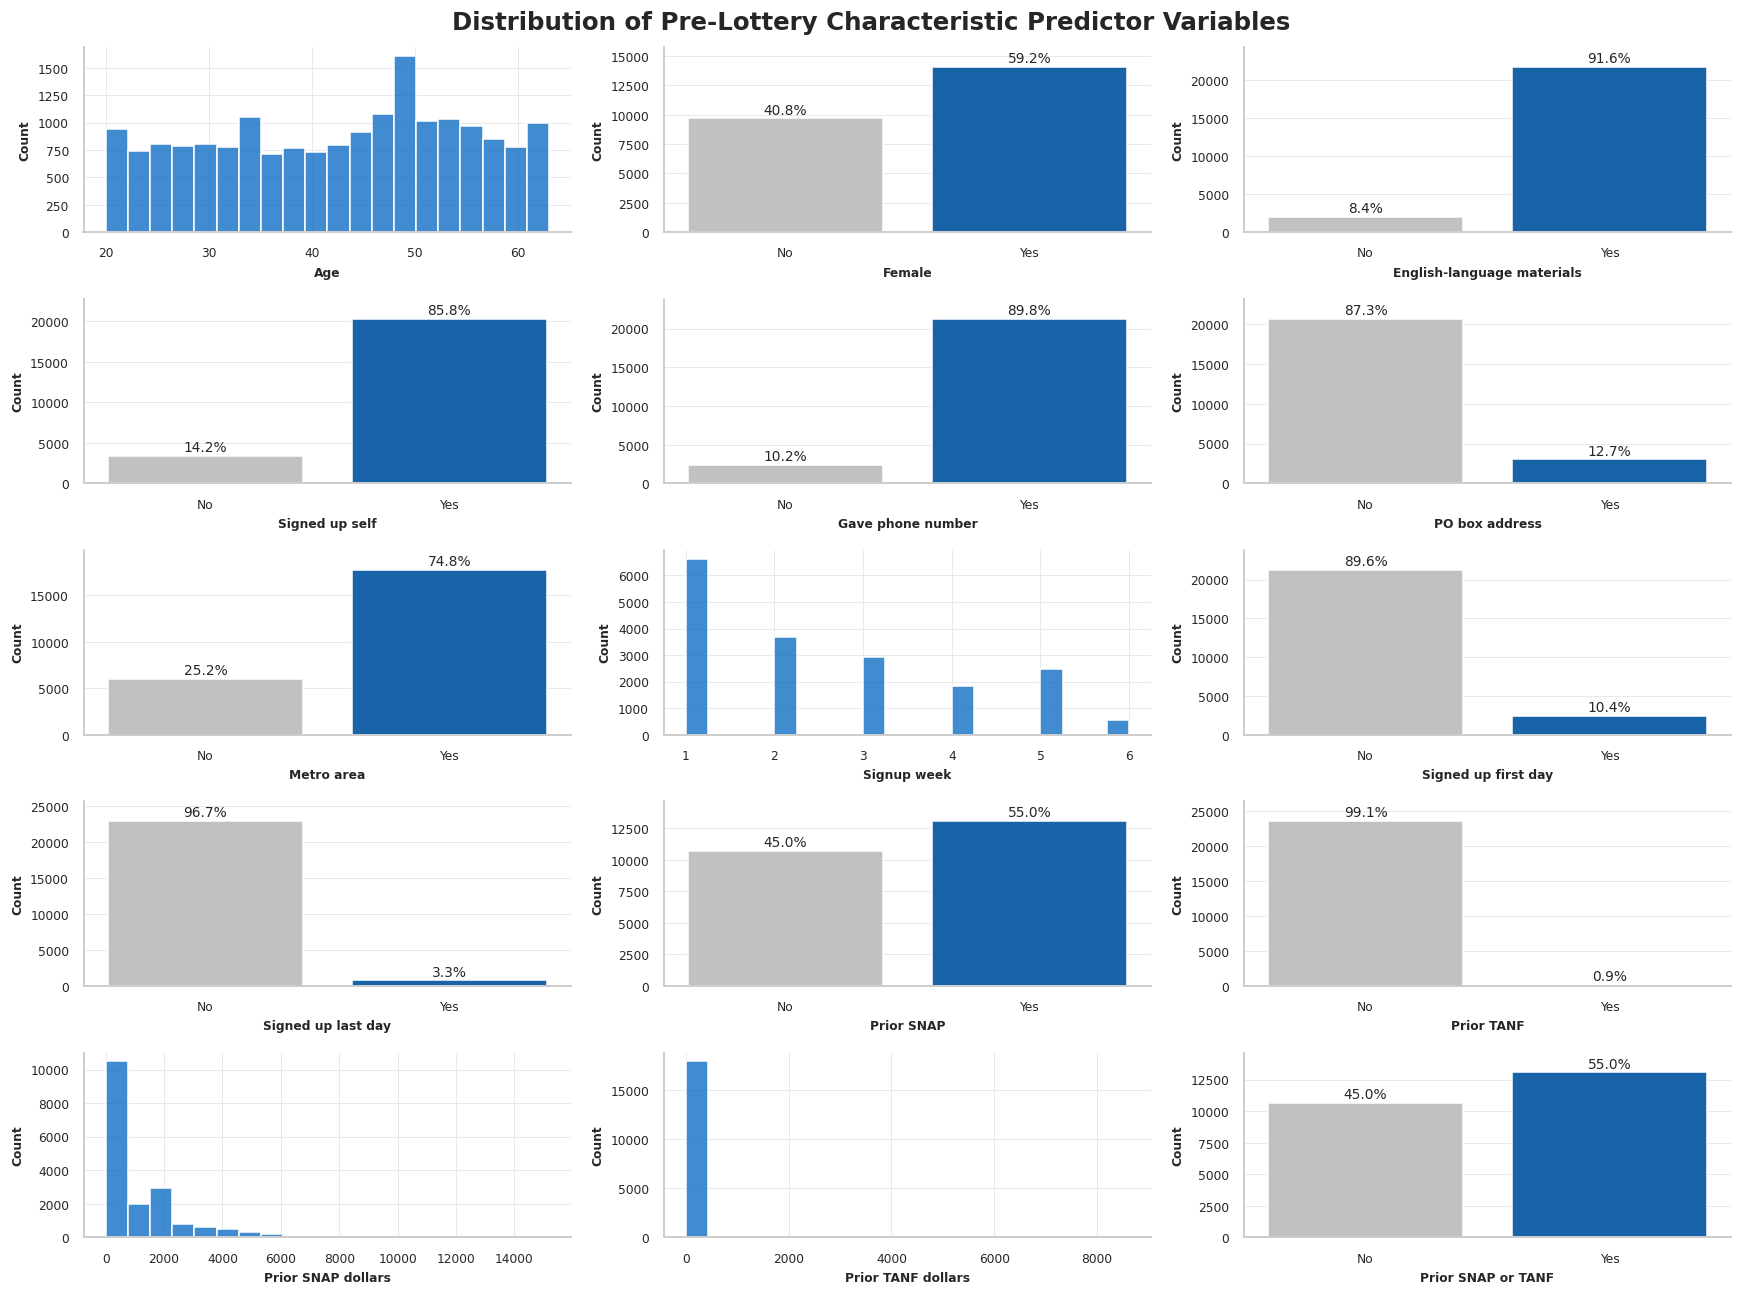

In [424]:
# Lets visualize the distribution of predictor variables in our dataset using histograms (continuous) and bar charts (binary/categorical)
# Instead of printing and displaying each histogram sequentially, lets create a clean grid layout to show it in one view
# Note: To learn if how to format the plots into a grid layout, instead of printing them all sequentially.
  # Claude Fable 5. Based on the response to prompt: "Instead of printing my plots sequentially, I want to display them in rows/columns to be more organized."
# 5 rows, 3 columns
fig, axes = plt.subplots(5, 3, figsize = (16, 12))
distribution_plots(df, predictors, "count", "Distribution of Pre-Lottery Characteristic Predictor Variables", fig, axes, "distribution_predictors")

Each panel shows the distribution of a specific predictor variable using a histogram or bar chart, depending on the data type. Immediately, we can see that the cohort is majorty female, with ages spread fairly evenly across age groups. Most respondents reported an english language preferance, individually signing up for the lottery, have a phone number, live in a metro area, were personally on SNAP between Janruary 2007 and March 2008, and signed up for the lottery in the first few weeks. Additionally, we can see that the total household benefits from SNAP or TANF appear to be highly skewed, with most respondents reporting no total household benefits, with a few reporting very high amounts.

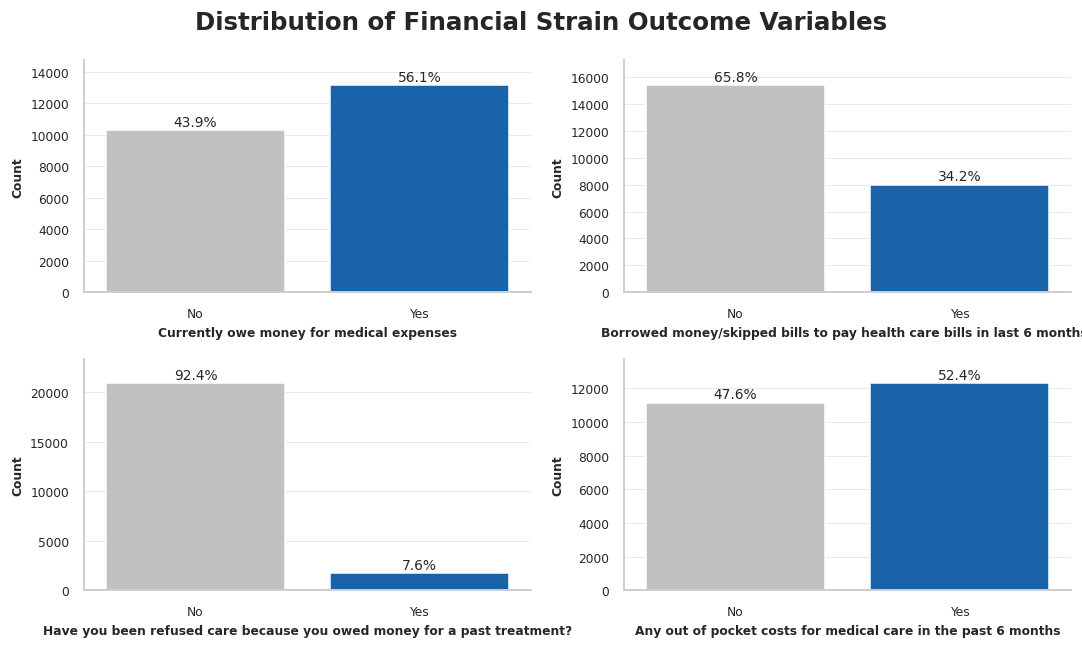

In [425]:
# Lets visualize the distribution of outcome variables in our dataset using bar charts (since they are all binary outcomes)
# Instead of printing and displaying each histogram sequentially, lets create a clean grid layout to show it in one view
# Note: To learn if how to format the plots into a grid layout, instead of printing them all sequentially.
  # Claude Fable 5. Based on the response to prompt: "Instead of printing my plots sequentially, I want to display them in rows/columns to be more organized."
# 2 rows, 2 columns
fig, axes = plt.subplots(2, 2, figsize = (10, 6))
distribution_plots(df, outcomes, "count", "Distribution of Financial Strain Outcome Variables", fig, axes, "distribution_outcomes")

Visualizing the distribution of financial strain outcomes, we can see that the majority of participants report owing money for medical expenses. Additionally, we can see that the majority of patients report out of pocket costs for medical care in the past 6 months, with some even needing to borrow money or skipping bills to pay for health care, or being refused care because they owed money for past treatment.

#### 5.5. Outcomes by Treatment Group

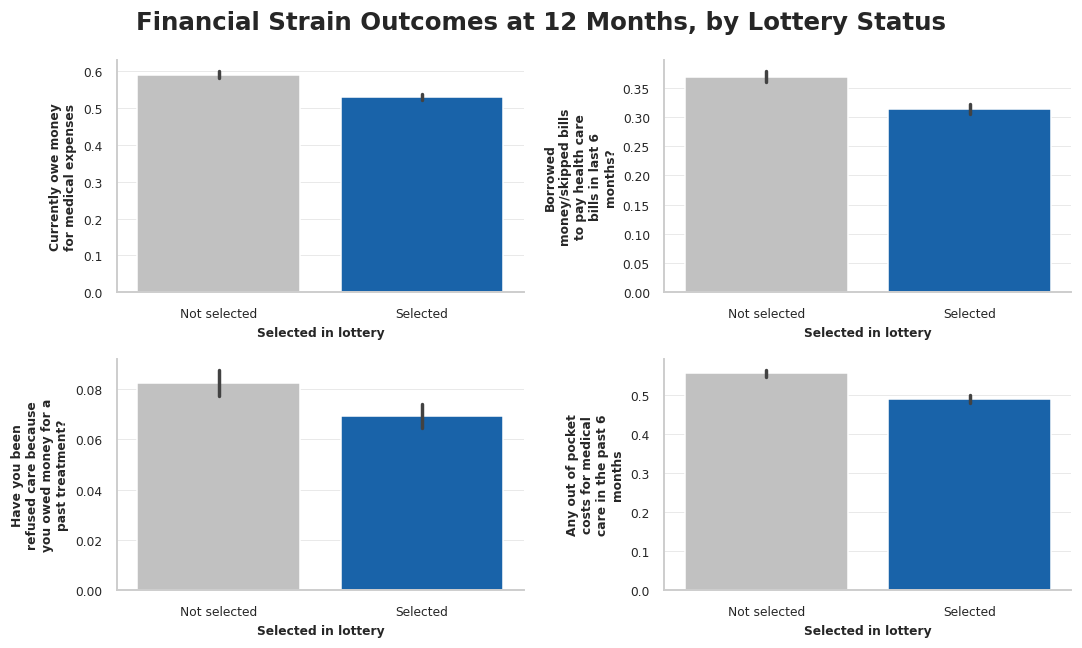

In [426]:
# Instead of printing and displaying each histogram sequentially, lets create a clean grid layout to show it in one view
# 2 rows, 2 columns
fig, axes = plt.subplots(2, 2, figsize = (10, 6))
distribution_plots(df, outcomes, "bar", "Financial Strain Outcomes at 12 Months, by Lottery Status", fig, axes, "distribution_outcome_by_treatment")


When visualizing financial strain outcomes by treatment group (i.e., selected in lottery or not selected in lottery), we can immediately see that those in the selected in the lottery have lower rates of financial strain across all four outcome variables (i.e., owe money for medical expenses, borrowed money or skipped bills to pay health care bills, refused care because of medidal debt, and had to pay out of pocket for medical care in the past 6 months).

#### 5.6. Subgroup Analysis

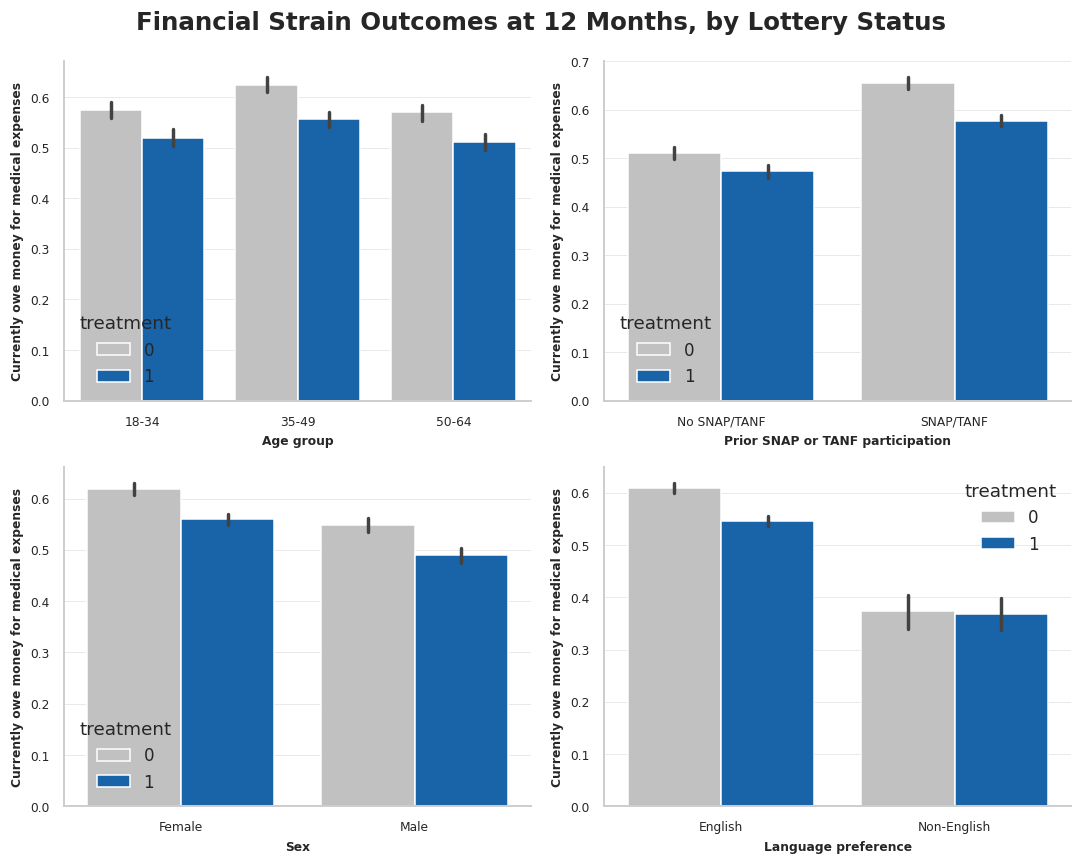

In [427]:
# Instead of printing and displaying each histogram sequentially, lets create a clean grid layout to show it in one view
# 2 rows, 2 columns
fig, axes = plt.subplots(2, 2, figsize = (10, 8))
distribution_plots(df, subgroups, "subgroups", "Financial Strain Outcomes at 12 Months, by Lottery Status", fig, axes, "distribution_outcome_by_treatment_and_subgroup")

Here, we visualized financial strain outcomes by treatment group (i.e., selected in lottery or not selected in lottery) and by subgroup (i.e., age group, prior SNAP/TANF participation, sex, and language preferance). We can see that the direction of difference between treatment groups is consistent across all subgroups (those selected in lottery have lower rates of financial strain), however, the magnitude of that difference does vary. For instance, we can see that there appears to be a larger difference between treatment groups for those with prior SNAP/TANF participation than those with not. Additionally, those with non-english language prefereance appear to have much more consistent rates across treatment groups. It will be important to investigate these differences further with a more robust subgroup analysis once during the full analysis.

#### 5.7. Predictor Correlation Matrix & Heatmap

In [428]:
# Lets create our correlation matrix using .corr(), and rename() to use the readable labels from the predictor dictionary
# Note: To learn how to create a correlation matrix in Python
  # Claude Fable 5. Based on the response to prompt: "How can I make a correlation matrix in Python, how to choose/change the method used, and how to use the values in a dictionary as the labels with the keys as the variables."
# Spearman was chosen over Pearson because snap_dollars_pre and tanf_dollars_pre appear to be right skewed
correlation_matrix = df[predictors].corr(method = "spearman").round(3)
correlation_matrix

,age,female,english,self_signup,has_phone,pobox,metro,signup_week,signup_first_day,signup_last_day,snap_pre,tanf_pre,snap_dollars_pre,tanf_dollars_pre,any_program_pre
age,1.000,-0.023,0.061,0.018,-0.005,0.083,-0.073,-0.050,0.030,-0.017,0.000,-0.058,-0.063,-0.032,-0.001
female,-0.023,1.000,0.007,0.144,0.025,-0.001,-0.002,-0.019,0.005,-0.007,0.017,0.046,0.037,0.058,0.018
english,0.061,0.007,1.000,0.129,-0.030,0.063,-0.078,-0.061,0.052,-0.010,0.196,0.004,0.076,-0.014,0.192
self_signup,0.018,0.144,0.129,1.000,-0.025,-0.001,0.027,0.027,-0.007,0.023,0.081,0.017,0.023,0.012,0.081
has_phone,-0.005,0.025,-0.030,-0.025,1.000,-0.010,0.010,0.041,-0.026,-0.030,0.035,-0.016,0.034,-0.003,0.036
pobox,0.083,-0.001,0.063,-0.001,-0.010,1.000,-0.263,0.034,-0.010,0.014,0.015,-0.013,0.002,-0.004,0.015
metro,-0.073,-0.002,-0.078,0.027,0.010,-0.263,1.000,-0.041,0.033,0.005,-0.034,0.017,-0.024,0.003,-0.034
signup_week,-0.050,-0.019,-0.061,0.027,0.041,0.034,-0.041,1.000,-0.388,0.265,-0.053,-0.001,-0.056,-0.010,-0.053
signup_first_day,0.030,0.005,0.052,-0.007,-0.026,-0.010,0.033,-0.388,1.000,-0.063,0.031,-0.007,0.028,-0.003,0.032
signup_last_day,-0.017,-0.007,-0.010,0.023,-0.030,0.014,0.005,0.265,-0.063,1.000,-0.039,0.000,-0.035,0.002,-0.039


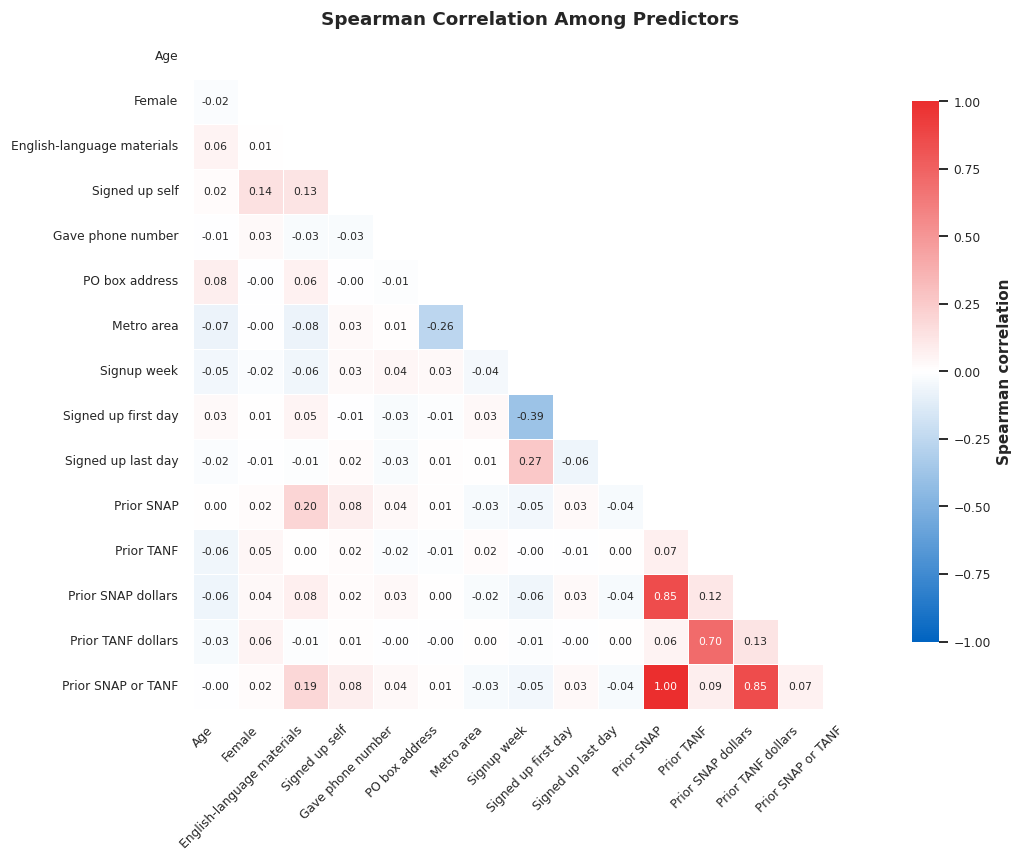

In [429]:
# Create a heatmap to visualize the correlation matrix
# Using annot = True to include the numeric labels
# https://python-graph-gallery.com/91-customize-seaborn-heatmap
# Lower triangle only, since the matrix is symmetric; readable labels; two decimals
mask = np.triu(np.ones_like(correlation_matrix, dtype = bool))
corr_labeled = correlation_matrix.rename(index = labels, columns = labels)

fig, ax = plt.subplots(figsize = (10, 8))
sns.heatmap(
    corr_labeled, mask = mask, cmap = COLORMAP, center = 0, vmin = -1, vmax = 1,
    annot = True, fmt = ".2f", annot_kws = {"size": 7},
    square = True, linewidths = 0.5, linecolor = "white",
    cbar_kws = {"label": "Spearman correlation", "shrink": 0.8},
    ax = ax
)
ax.set_title("Spearman Correlation Among Predictors")
ax.tick_params(axis = "x", rotation = 45, labelsize = 8)
ax.tick_params(axis = "y", rotation = 0, labelsize = 8)
ax.set_xticklabels(ax.get_xticklabels(), ha = "right")
ax.grid(False)
plt.tight_layout()
fig.savefig(f"{OUTPUT}/correlation_heatmap.png")
plt.show()

The matrix and heatmap report the Spearman rank correlations between each pair of predictors. Spearman was chosen for it's more robustness to skewed data and outliers, since household SNAP/TANF benefit amounts appear to be right skewed with clear outliers.

The strongest relationships were mostly by design. Any program participation (SNAP or TANF) was nearly identical to SNAP participation (0.999). Similarly, TANF participation and household TANF benefit amounts were strongly correlated (0.7), and SNAP participation and household SNAP benefit amounts were strongly correlated (0.85). Meanwhile, living in a metro area was moderately negatively correlated with reporting a PO box. With that said, the majority of relationships were only weakly correlated with each other.

## 6. Supervised Machine Learning Classification

---

Ask who is likely to have medical debt at 12 months. Logistic regression, random forest, and XGBoost are tuned and evaluated with household-grouped cross-validation so that members of the same household are never split across training and test sets. Out-of-fold predictions feed threshold selection, performance metrics, an overfit check, ROC and calibration curves, confusion matrices, and variable importance.

---

This section includes:

- 6.1. Design Matrix & Cross-Validation Folds
- 6.2. Logistic Regression
- 6.3. Random Forest
- 6.4. XGBoost
- 6.5. Out-of-Fold Predictions
- 6.6. Threshold Selection
- 6.7. Performance Metrics & Overfit Check
- 6.8. ROC & Calibration Curves
- 6.9. Confusion Matrices
- 6.10. Variable Importance


### 6.1. Design Matrix & Cross-Validation Folds

**Cross-validation** provides a more reliable estimate of model performance than a single train/test split by using multiple non-overlapping evaluation folds.

In **Stratified k-Fold Cross-Validation**, the dataset is divided into $k$ equally-sized folds, maintaining the class proportions in each fold. The model is trained on $k-1$ folds and evaluated on the remaining fold. This process is repeated $k$ times, each time using a different fold as the validation set.

The cross-validated performance estimate is:

$$
\text{CV Score} = \frac{1}{k} \sum_{i=1}^k \text{Score}_i
$$

where $\text{Score}_i$ is the performance metric on fold $i$.

| $k$ | Bias | Variance | Computational Cost |
|---|---|---|---|
| 3 | High | Low | Low |
| 5 | Moderate | Moderate | Moderate |
| 10 | Low | High | High |

$k = 5$ is the most common choice, balancing bias, variance, and computational cost.

Cross-validation uses the **training data only** — the test set remains completely held out. This means every observation in the training set is used for both training and validation, giving a more stable performance estimate than a single split.

<br>

**Design Matrix:** The 15 predictors are kept except for any_program_pre, which provides nearly identical information as snap_pre (Spearman 0.999) and is therefore redundant, based on the correlation matrix. hh_size and wave are stored as integers but represent categories (household size: 1-3, survey mailing waves: 1-7), so they are one-hot encoded, using one level of each as the reference.

**Cross-Validation Folds:** Lottery selection was at the household level, and members of the same household share an address, household income, and lottery outcome. If one member landed in a training fold and another in the test fold, the model would have a near-identical copy of the test case during training, introducing a form of data leakage. For that reason, folds are grouped by household, and the same five folds are reused for the machine learning classifiers (i.e., logistic regression, random forest, XGBoost) and causal inference methods (i.e., AIPW, g-computation, causal forest).

<br>

*References:*

*Dr. Jamie Fairclough. Dartmouth Programming_Additional Code (Adv Stats & Machine Learning).ipynb. Geisel School of Medicine at Dartmouth.*


In [430]:
# First, lets build the modeling inputs that every model in the rest of the notebook will use
# Use one-hot encoding for any multi-level categories (hh_size and wave)
categorical = ["hh_size", "wave"]

# Based on the correlation matrix, we saw that any_program_pre is nearly identical to snap_pre (Spearman 0.999), so lets drop one to avoid redundancy
features = [p for p in predictors if p != "any_program_pre"] + [treatment] + categorical

# Create our design matrix: outcome, household groups, survey weights
X = pd.get_dummies(df[features], columns = categorical, drop_first = True, dtype = int)
y = df[outcome]
# We also need to account for our design variables
# Group by household id, so that memebers of the same household can be placed within the same cross validation fold (to avoid data leakage)
groups = df["household_id"]

# Print to view the final feature set
print(X.shape)
print(X.columns)

(23740, 23)
Index(['age', 'female', 'english', 'self_signup', 'has_phone', 'pobox',
       'metro', 'signup_week', 'signup_first_day', 'signup_last_day',
       'snap_pre', 'tanf_pre', 'snap_dollars_pre', 'tanf_dollars_pre',
       'treatment', 'hh_size_2', 'hh_size_3', 'wave_2', 'wave_3', 'wave_4',
       'wave_5', 'wave_6', 'wave_7'],
      dtype='object')


### 6.2. Logistic Regression

Logistic Regression models the **probability** that an observation belongs to class 1 given its features:

$$
P(y_i = 1 \mid x_i) = \sigma(w^\top x_i + b) = \frac{1}{1 + e^{-(w^\top x_i + b)}}
$$

where:

- $w \in \mathbb{R}^p$ is the weight vector (learned coefficients).
- $b \in \mathbb{R}$ is the bias (intercept).
- $\sigma(\cdot)$ is the **sigmoid (logistic) function**, which maps any real value to $(0, 1)$.
- $w^\top x_i + b$ is the **linear predictor** (log-odds or logit).

The sigmoid function is defined as:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}, \qquad z \in \mathbb{R}
$$

<br>

*References:*

*Dr. Jamie Fairclough. Dartmouth Programming_Additional Code (Adv Stats & Machine Learning).ipynb. Geisel School of Medicine at Dartmouth.*

In [431]:
# For model fitting, we need observed outcomes only (no NAs)
fit_data = y.notna()
X_fit = X[fit_data]
y_fit = y[fit_data].astype(int)
groups_fit = groups[fit_data]

# Lets create folds based on household id so that members of the same household are not spread across training and test sets to avoid potential data leakage
# Note: To learn how to create folds based on household id
  # Claude Fable 5. Based on the response to prompt: "How can I create cross-validation folds, while ensuring that members of the same household are not split between training and test sets?"
n_folds = 5
folds = list(GroupKFold(n_splits = n_folds).split(X_fit, y_fit, groups = groups_fit))


In [432]:
# First, lets perform the baseline: logistic regression with scaling, since the predictors are on different scales
logistic_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter = 1000))

### 6.3. Random Forest

A **Random Forest** is a bagging ensemble of Decision Trees with one additional source of randomness: at each split in each tree, only a **random subset of features** is considered as candidates for the split.

This feature subsampling is controlled by the `max_features` parameter and is what distinguishes Random Forest from a plain Bagging Classifier applied to Decision Trees.

For $B$ trees trained on bootstrap samples $\mathcal{D}^{*(1)}, \ldots, \mathcal{D}^{*(B)}$:

$$
\hat{f}_{\text{RF}}(x) = \frac{1}{B} \sum_{b=1}^{B} \hat{T}_b(x)
$$

where $\hat{T}_b(x)$ is the prediction of the $b$-th tree, and at each node within tree $b$, only $m \leq p$ randomly selected features are considered for splitting.

**Typical values of $m$ for classifcation:** $m = \lfloor\sqrt{p}\rfloor$ (default in sklearn)

<br>

*References:*

*Dr. Jamie Fairclough. Dartmouth Programming_Additional Code (Adv Stats & Machine Learning).ipynb. Geisel School of Medicine at Dartmouth.*


In [433]:
# Next, lets create our random forest classifier
# First, we need to define the hyperparameter grid for tuning
# Note: To learn how to perform hyperparameter tuning for random forest and XGBoost
  # Claude Fable 5. Based on the response to prompt: "I am building random forest and xgboost models, how can I perform hyperparameter tuning and how do I decide on the default grid?"
rf_grid = {
    # n_estimators: how many trees to average
    "n_estimators": [100, 250, 500],
    # max_depth: how deep each tree can go
    "max_depth": [None, 4, 6, 8, 10],
    # min_sample_leaf: smallest group a tree is allowed to get split down to
    "min_samples_leaf": [5, 25, 50, 100],
    # max_features: how many predictors each split gets to choose from
    "max_features": ["sqrt", 0.5]
}

# Random search over 20 combinations, scored based on brier and using the household-grouped folds
# Random search helps reduce the computation time by randomly selecting combinations across the grid, rather than running all possible combination
rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state = SEED, n_jobs = -1),
    rf_grid, n_iter = 20, scoring = "neg_brier_score", cv = folds, random_state = SEED
)

# Fit, identify, and report the best combination and its cross-validated brier score
rf_search.fit(X_fit, y_fit)
print("Random forest:", rf_search.best_params_, round(-rf_search.best_score_, 4))

Random forest: {'n_estimators': 100, 'min_samples_leaf': 100, 'max_features': 0.5, 'max_depth': 10} 0.2369


The search selected 100 trees, a maximum depth of 10, a minimum of 100 observation per leaf, and half the features considered at each split, for a cross-validated Brier score of 0.2369.

### 6.4. XGBoost

**XGBoost** (Chen & Guestrin, 2016) is a highly optimized implementation of gradient boosting that adds several important refinements:

**1. Regularization built into the objective:**

$$
\mathcal{L}^{(b)} = \sum_{i=1}^{n} \ell(y_i, \hat{y}_i^{(b)}) + \Omega(h_b)
$$

where the regularization term $\Omega(h_b) = \gamma T + \frac{1}{2}\lambda\|w\|^2$ penalizes tree complexity ($T$ = number of leaves, $w$ = leaf weights).

**2. Second-order approximation of the loss** — uses both gradient and Hessian for more accurate leaf weight computation

**3. Column subsampling** (like Random Forest's feature subsampling) — reduces overfitting and speeds up training

**4. Sparsity awareness** — efficiently handles missing values internally

**5. Parallel and distributed computation** — much faster than sklearn's GradientBoostingClassifier

<br>

*References:*

*Dr. Jamie Fairclough. Dartmouth Programming_Additional Code (Adv Stats & Machine Learning).ipynb. Geisel School of Medicine at Dartmouth.*

In [434]:
# Now, lets create our xgboost classifier
# Simarily to random forest, lets define the hyperparameter grid for tuning
xgb_grid = {
    # n_estimators: how many trees to add (this time, sequentially)
    "n_estimators": [100, 250, 500],
    # max_depth: how deep each tree can go
    "max_depth": [4, 6, 8, 10],
    # learning_rate: how big a step each new tree takes
    "learning_rate": [0.02, 0.05, 0.1],
    # min_child_weight: smallest group a tree is allowed to split down to
    "min_child_weight": [1, 5, 20],
    # subsample: fraction of rows each tree seees
    "subsample": [0.7, 0.9]
}

# Random search over 25 combinations, scored on brier and using the household-grouped folds
xgb_search = RandomizedSearchCV(
    XGBClassifier(random_state = SEED, n_jobs = -1),
    xgb_grid, n_iter = 25, scoring = "neg_brier_score", cv = folds, random_state = SEED
)

# Fit, identify, and report the best combination and its cross-validated brier score
xgb_search.fit(X_fit, y_fit)
print("xgboost:", xgb_search.best_params_, round(-xgb_search.best_score_, 4))

xgboost: {'subsample': 0.9, 'n_estimators': 100, 'min_child_weight': 20, 'max_depth': 6, 'learning_rate': 0.02} 0.2372


The search selected 100 boosting rounds at a learning rate of 0.02, depth 6, minimum child weight of 20, and 90% row subsampling, for a cross-validated Brier score of 0.2372. The result is effectively tied with random forest (0.2369).

### 6.5. Out-of-Fold Predictions

In [435]:
# Lets create a classification models dictionary, so that we can loop through it to get the final classification metrics and compare
classification_models = {
    "logistic": logistic_model,
    "random_forest": rf_search.best_estimator_,
    "xgboost": xgb_search.best_estimator_
}

classification_models_labels = {
    "logistic": "Logistic Regression",
    "random_forest": "Random Forest",
    "xgboost": "XGBoost"
}

MODEL_COLORS = dict(zip(classification_models, PALETTE))

In [436]:
# We want out-of-fold predicted probabilities for each model, using the household
# Four folds used to fit the model, and one saved to score
# So every respondent is predicted by a model that has never seen their household
oof = pd.DataFrame(index = X_fit.index, columns = classification_models.keys(), dtype = float)
# Save fitted fold models for later use
fold_models = {name: [] for name in classification_models}

# Loop through and fit / score each model (logistic regression, random forest, and xgboost)
# Note: To learn how to fit each model using the folds
  # Claude Fable 5. Based on the response to prompt: "Now that I have the cross-validation folds, how can we use them for the train-test split?"
for name, model in classification_models.items():
    for train, test in folds:
        # Fit the model on the four folds
        model.fit(X_fit.iloc[train], y_fit.iloc[train])
        # Score the model on the held-out fold
        oof.iloc[test, oof.columns.get_loc(name)] = model.predict_proba(X_fit.iloc[test])[:, 1]
        fold_models[name].append(copy.deepcopy(model))

oof.describe().T


,count,mean,std,min,25%,50%,75%,max
logistic,23450.0,0.560720,0.093490,0.227135,0.507865,0.572632,0.627986,0.823202
random_forest,23450.0,0.560699,0.095811,0.250566,0.497250,0.562293,0.631422,0.774350
xgboost,23450.0,0.560684,0.088003,0.229611,0.508067,0.566865,0.625011,0.723455


The three sets of out-of-fold predictions are nearly identical in location and spread: mean 0.561 (matching with the base rate), standard deviation about 0.09, and a range of roughly 0.2 to 0.8. No model pushes predictions toward 0 or 1, which indiciates the weak separation between those with and without medical debt based on these features.

### 6.6. Threshold Selection

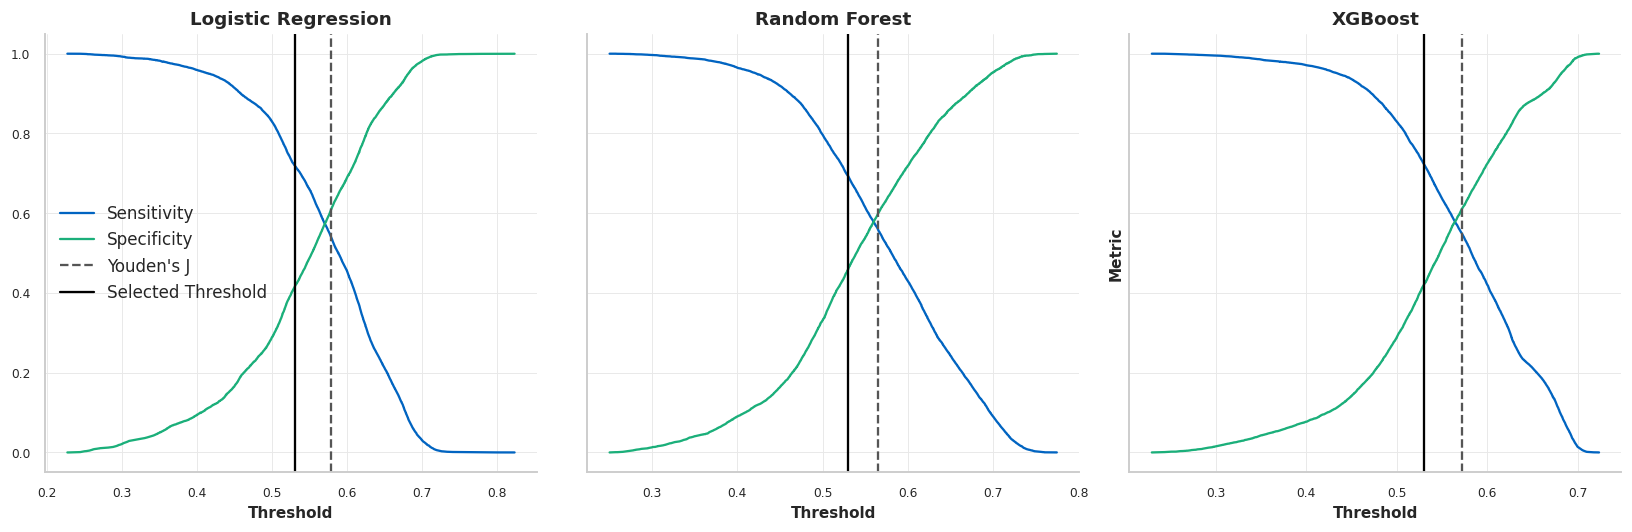

In [437]:
# Next, lets determine our threshold
# To do this, we will create a plot to visualize sensitivity and specificity for each model
# Since we want to prioritize sensitivity (avoiding false negatives), lets select a threshold that
# maintains high sensitivity, at a slight cost of specifcity (compared to Youden's J)
# Note: To learn how to create a plot visualizing the sensitivity/specificity tradeoff
  # Claude Fable 5. Based on the response to prompt: "Instead of using F1-maximization or Youden's J, I want to select the threshold based on a sensitvity-specificty tradeoff, based on the studies goals (prioritze sensitivity, without losing too much specificity)"
chosen_threshold = 0.53
fig, axes = plt.subplots(1, 3, figsize = (15, 5), sharey = True)
# For each model, lets create a sensitivity vs specificity plot
for ax, name in zip(axes, classification_models):
    # First, retrieve the out-of-fold predicted probabilities for this model
    p = oof[name]
    # False positive rate and false positive rate at every cutoff
    fpr, tpr, threshold = roc_curve(y_fit, p)
    ax.plot(threshold, tpr, label = "Sensitivity")
    ax.plot(threshold, 1 - fpr, label = "Specificity")
    # Plot Youden's J (maximizes sensitivity + specificty), for reference
    ax.axvline(threshold[np.argmax(tpr - fpr)], linestyle = "--", color = COLORS["reference"], label = "Youden's J")
    # After viewing the plots and deciding a threshold, lets add a line for our selected threshold, so it is easy to visualize the
    # tradeoff between sensitivity and specificity
    ax.axvline(chosen_threshold, color = "black", label = "Selected Threshold")
    # Add plot title, label and legend
    ax.set_title(classification_models_labels[name])
    ax.set_xlabel("Threshold")
    if name == "logistic":
      ax.legend()
ax.set_ylabel("Metric")
plt.tight_layout()
fig.savefig(f"{OUTPUT}/threshold_selection.png")
plt.show()

A classification threshold converts predicted probabilities those flagged as having medical debt / no medical debt. Two automatic approaches were tried and ultimately rejected. First, maximizing F1 chose a threshold of near 0.35 that labeled almost every respondent as having medical debt, so this was not useful or appropriate. Second, Youden's J (sensitivity + specificity - 1) chose a threshold near the base rate but weights the two error types equally, which does not properly reflect our priorities here.

The threshold was instead chosen based on the sensitivity and specificty plot above, with sensitivity (recall) as the primary metric. For our purposes, missing someone who will incur medical debt is higher cost than incorrectly flagging someone as having medical debt when they do not. A threshold of 0.53, just below the base rate, prioritizes sensitivity without labeling everyone as having medical debt. Moving the threshold from 0.55 to 0.53 raised sensitivity from about 0.65 to 0.72 at a cost of about 0.08 in specificity.

### 6.7. Performance Metrics & Overfit Check

In [438]:
# Each model refit on the full fit sample, used for the overfitting check, feature importance, and SHAP
full_models = {name: copy.deepcopy(m).fit(X_fit, y_fit) for name, m in classification_models.items()}

# Now, lets perform an overfitting check, to make sure the model generalizes well to new data
# Loop through each classification model (logistic regression, random forest, xgboost), and determine the train and set auc and brier score
# Note: To learn how to gather training set predictions, to test for overfitting
  # Claude Fable 5. Based on the response to prompt: "I have test set-based predictions, but now how can I retrieve training set-based predictions, so that I can compare the two for overfitting."
rows = []
for name in classification_models:
    # Retrieve the predictions for the training set
    p_train = full_models[name].predict_proba(X_fit)[:, 1]
    # Save them to a list, so that we can display and compare them in a single table
    rows.append({
        "Model": name,
        "Train AUC": roc_auc_score(y_fit, p_train),
        "Test AUC": roc_auc_score(y_fit, oof[name]),
        "Train Brier": brier_score_loss(y_fit, p_train),
        "Test Brier": brier_score_loss(y_fit, oof[name]),
    })


# Now, lets group the scores by model and compare the train vs test set auc and brier score to ensure they are relatively consistent and that there is no overfitting
overfit_check = pd.DataFrame(rows).set_index("Model")
overfit_check.round(3)

,Train AUC,Test AUC,Train Brier,Test Brier
Model,,,,
logistic,0.606,0.603,0.238,0.238
random_forest,0.638,0.611,0.232,0.237
xgboost,0.640,0.609,0.232,0.237


Logistic regression shows essentially no gap between full-sample and out-of-fold AUC (0.606 vs 0.603). The tree models show a small gap of 0.03 (0.638 vs 0.611 for the random forest, 0.640 vs 0.609 for XGBoost), which is expected from refitting on the same data. Brier scores are flat at 0.232 to 0.238 across all models and both evaluations. The training values are only used for this overfit check, moving forward, only out-of-fold values will be used and reported.

In [439]:
# Loop through each classification model (logistic regression, random forest, xgboost) to retrieve the classification metrics
rows = []
for name in classification_models:
    # Clip to avoid logit of exactly 0 or 1 in the calibration regression
    p = oof[name].clip(0.001, 0.999)
    # Determine each respondents prediction (debt or no debt), based on their probability and the selected threshold
    # If probability is at or above the threshold, then classify as debt (1)
    # If probability is below the threshold, then classify as no debt (0)
    pred = (p >= chosen_threshold).astype(int)
    # Determine the calibration slope
    cal = sm.Logit(y_fit, sm.add_constant(logit(p))).fit(disp = 0)
    # Retrieve the true negative (tn), false positive (fp), false negative (fn) and true positive (tp) for determining sensitivity and specificity
    tn, fp, fn, tp = confusion_matrix(y_fit, pred).ravel()
    # Add all metrics for each model to a single list, so that we can display and compare them in a single table
    rows.append({
        "Model": name,
        "Threshold": chosen_threshold,
        "AUC": roc_auc_score(y_fit, p),
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "Accuracy": accuracy_score(y_fit, pred),
        "Brier": brier_score_loss(y_fit, p),
        "Calibration Slope": cal.params.iloc[1],
        "Recall": recall_score(y_fit, pred),
        "Precision": precision_score(y_fit, pred),
        "F1": f1_score(y_fit, pred)
    })

# Print the classification metrics for all three models
classification_metrics = pd.DataFrame(rows).set_index("Model").round(3)
classification_metrics


,Threshold,AUC,Sensitivity,Specificity,Accuracy,Brier,Calibration Slope,Recall,Precision,F1
Model,,,,,,,,,,
logistic,0.53,0.603,0.720,0.415,0.586,0.238,0.959,0.720,0.611,0.661
random_forest,0.53,0.611,0.693,0.460,0.591,0.237,1.014,0.693,0.621,0.655
xgboost,0.53,0.609,0.723,0.420,0.590,0.237,1.095,0.723,0.614,0.664


At the selected threshold of 0.53, all three models sit at an AUC of 0.60 to 0.61, sensitivity of 0.69 to 0.72, specificity of 0.42 to 0.46, and accuracy of 0.59. Calibration slopes near 1 (0.96 to 1.10) indicate that predicted probabilities are on the right scale, so a prediction of 0.65 corresponds to roughly a 65% observed rate of medical debt. Recall, the primary metric, is 0.69 to 0.72 for all three models with a precision of 0.61 to 0.62, indicating that about three in five of those flagged as having medical debt actually do, compared to the base rate of 0.56.

There are two key takeaways from these performance metrics. First, an AUC of 0.60 indicates weak discrimination ability. The predictors are pre-lottery administrative variables (age, sex, language, prior benefit recipient, signup behavior), plus the lottery selection indicator. However, medical debt at 12 months likely depends largely on health status, health shocks, income, and existing debt that are not included here. All three models appear to be approximately equivalent for the predefined primary metric (Brier score: 0.237 to 0.238), so the selection falls to a tie-breaker. XGBoost will be used for the causal (g-computation, AIPW) and policy simulations because it handles interactions between treatment and covariates without having to specify them. With that said, logistic regression would have also been a reasonable choice, given its simplicity, transparency, and interpretability.

### 6.8. ROC & Calibration Curves

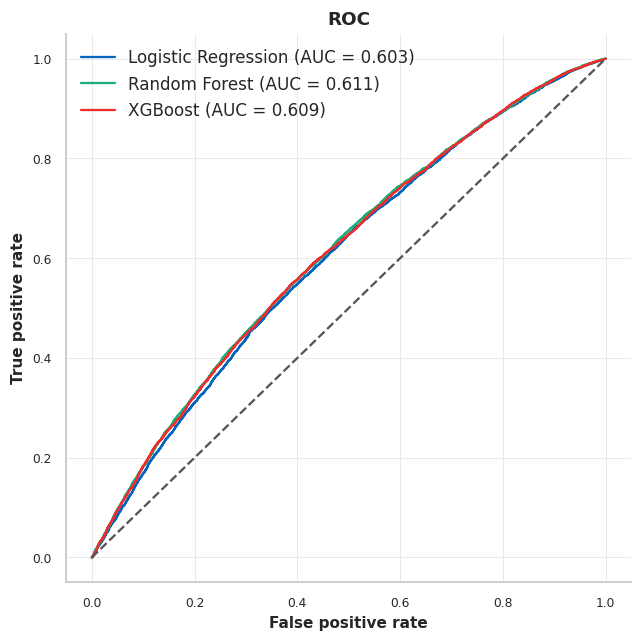

In [440]:
# Lets compare our three models using an ROC curve on the out-of-fold predictions
fig, ax = plt.subplots(figsize = (6, 6))
# First, loop through each classification model (logistic regression, random forest, and xgboost)
# and determine the false positive rate and true positive rate using the roc_curve() sklearn function
# Then, we can plot each one, along with its text label / legend
for name in classification_models:
    fpr, tpr, _ = roc_curve(y_fit, oof[name])
    ax.plot(fpr, tpr, label = f"{classification_models_labels[name]} (AUC = {classification_metrics.loc[name, "AUC"]:.3f})")
# For reference, also plot the 0.5 line
ax.plot([0, 1], [0, 1], linestyle = "--", color = COLORS["reference"])
# Add x and y axis labels, and a plot title
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC")
# Add the legend, using the label created earlier
ax.legend()
plt.tight_layout()
fig.savefig(f"{OUTPUT}/roc.png")
plt.show()

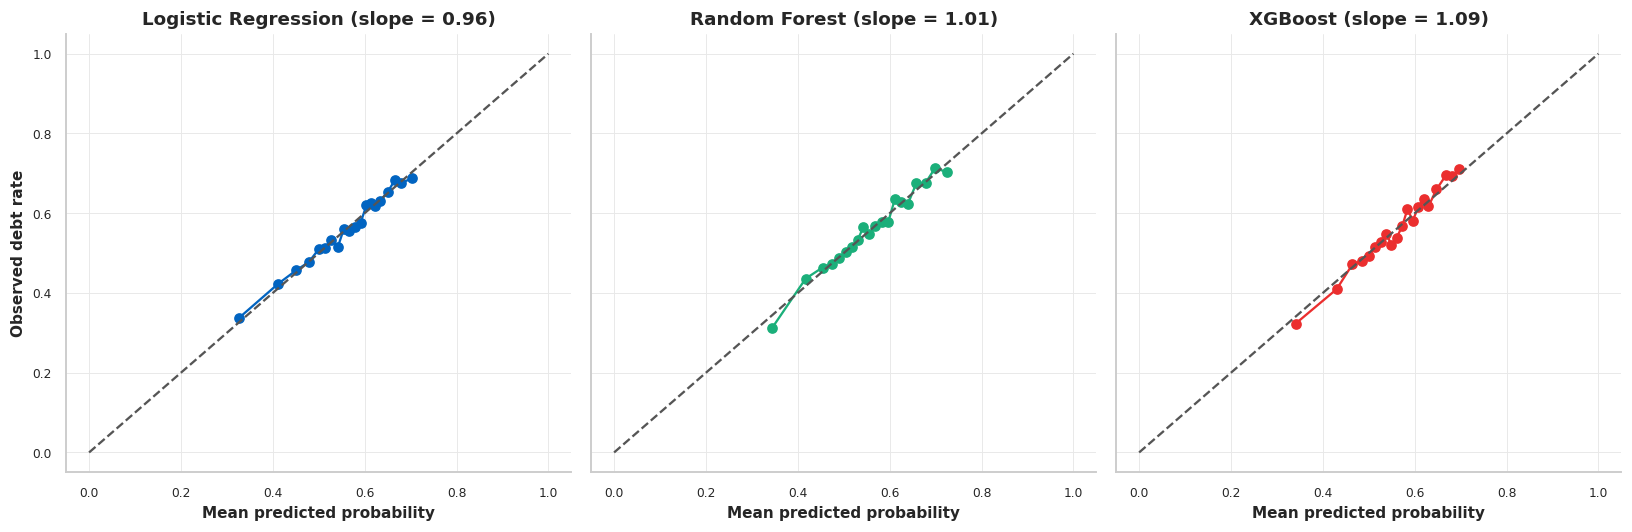

In [441]:
# Next, lets check and compare the calibration curves of each model
# Note: To learn how to create create a calibration curve and confusion matrix plots
  # Claude Fable 5. Based on the response to prompt: "How can I create a calibration curve and confusion matrix plots in Python for all three classification model?"
fig, axes = plt.subplots(1, 3, figsize = (15, 5), sharey = True)
for ax, name in zip(axes, classification_models):
    # Split respondents into 20 bins (by predicted probability), and determine the mean prediction for each bin
    frac_props, mean_pred = calibration_curve(y_fit, oof[name], n_bins = 20, strategy = "quantile")
    # Plot the bins mean prediction vs observed debt rate
    ax.plot(mean_pred, frac_props, marker = "o", color = MODEL_COLORS[name])
    # Add a reference line for perfect calibration
    ax.plot([0, 1], [0, 1], linestyle = "--", color = COLORS["reference"])
    # Add a title, including the calibration slope for each model
    ax.set_title(f"{classification_models_labels[name]} (slope = {classification_metrics.loc[name, 'Calibration Slope']:.2f})")
    ax.set_xlabel("Mean predicted probability")
# Add one y axis label, to apply across all three plots (since its consistent, and reduces clutter)
axes[0].set_ylabel("Observed debt rate")
plt.tight_layout()
fig.savefig(f"{OUTPUT}/calibration_curve.png")
plt.show()


Observed rates track predicted probabilities closely along the diagonal across the full range of predictions (about 0.3 to 0.75). The models are appear to be appropriately confident across all points, consistent with the calibration slopes of 0.96 (logistic regression), 1.01 (random forest), and 1.09 (XGBoost).

### 6.9. Confusion Matrices

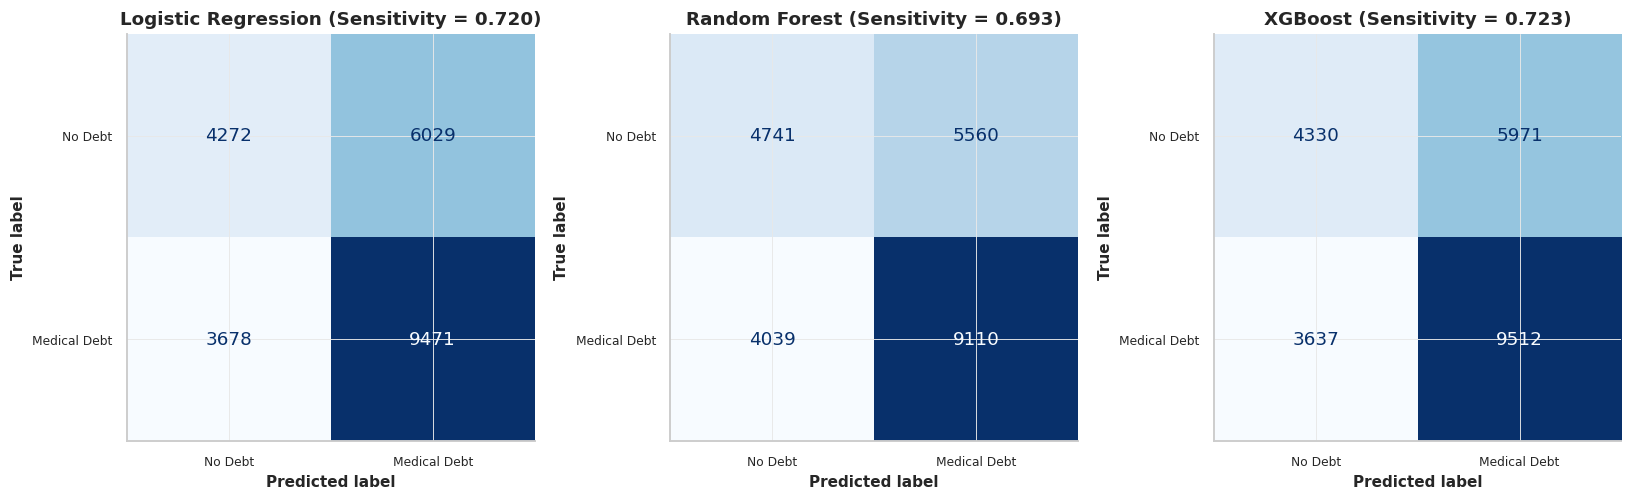

In [442]:
# Lets create a confusion matrix for each model
fig, axes = plt.subplots(1, 3, figsize = (15, 6))
for ax, name in zip(axes, classification_models):
    # Turn the out-of-fold probabilities into 0/1 labels at the selected threshold
    pred = (oof[name] >= classification_metrics.loc[name, "Threshold"]).astype(int)
    # Create the confusion matrix
    cm = confusion_matrix(y_fit, pred)
    # Display the confusion matrix
    ConfusionMatrixDisplay(cm, display_labels = [OUTCOME_LABELS[0], OUTCOME_LABELS[1]]).plot(cmap = "Blues", ax = ax, colorbar = False)
    # Add a title, including the value for sensitivity, since that is our priority metric
    ax.set_title(f"{classification_models_labels[name]} (Sensitivity = {classification_metrics.loc[name, "Sensitivity"]:.3f})")
plt.tight_layout()
fig.savefig(f"{OUTPUT}/confusion_matrix.png")
plt.show()



Each model correctly identifies about 9,100 to 9,500 of 13,149 respondents with medical debt and misses 3,650 to 4,050. For those without medical debt, only 4,250 to 4,750 of 10,301 are correctly classified, with 5,550 to 6,050 are incorrectly flagged as having medical debt. False positive outnumber false negatives roughly 1.6 to 1, which is the intended consequence of the threshold, where the cost of missing a participant with medical debt outweights the cost of flagging a participant with no medical debt.

### 6.10. Variable Importance

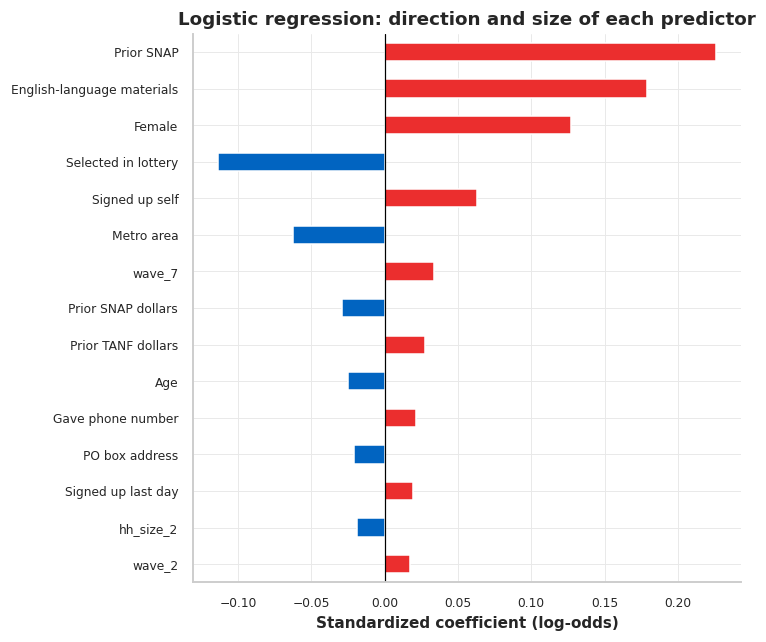

In [443]:
# Lets also plot the logistic regression coefficients, to show the direction and magnitude of each
# Note: To learn how to create logistic regression coefficient, permutation importance, and SHAP plots
  # Claude Fable 5. Based on the response to prompt: "How can I create plots for logistic regression coefficients, permutation importance (logistic regression, random forest, and xgboost), and SHAP (xgboost only)"
coef = pd.Series(full_models["logistic"].named_steps["logisticregression"].coef_[0], index = X_fit.columns)
# Now, rank by absolute size, while maintaining the direction
coef = coef.reindex(coef.abs().sort_values(ascending = False).index).head(15)
fig, ax = plt.subplots(figsize = (7, 6))
# Lets also color the bars based on direction, red = increases log odds of medical debt, blue = decreases log odds of medical debt
coef.rename(index = labels).plot.barh(ax = ax, color = np.where(coef > 0, COLORS["tertiary"], COLORS["primary"]))
ax.axvline(0, color = "black", linewidth = 0.8)
# Invert y axis so the largest absolute size is on the top
ax.invert_yaxis()
ax.set_xlabel("Standardized coefficient (log-odds)")
ax.set_title("Logistic regression: direction and size of each predictor")
plt.tight_layout()
fig.savefig(f"{OUTPUT}/logistic_coefficient.png")
plt.show()

Prior SNAP recipient (0.23), English as preferred language (0.18), and female sex (0.13) are the strongest positive predictors of medical debt. The selected in lottery indicator has the fourth magnitude and is negative (-0.11), consistent with the protective effect estimated from a Medicaid insurance coverage offer. Metro residence appeared to be mildly protective. Signup timing, giving a phone number at signup, and giving a PO box as an address contributed relatively little. Since coefficients are based on the standardized features, the magnitudes are comparable.

Additionally, the positive coefficient for English language preferance is worth noting. This may reflect differences in health care use and billing exposure rather than a direct effect of language, and is investigated further during the subgroup analysis in Section 8.


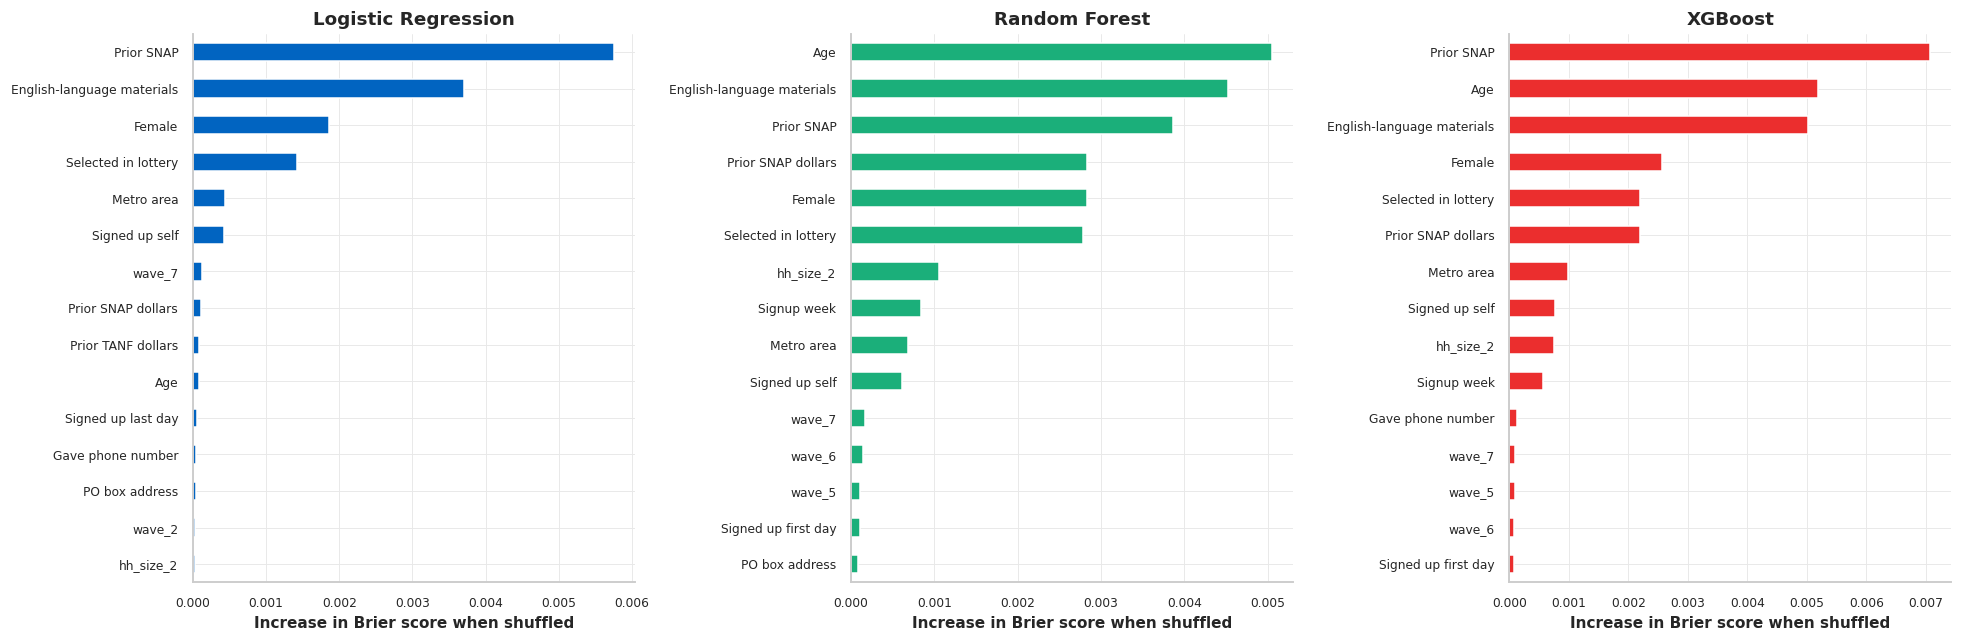

In [444]:
# Now, lets show how much each predictor matters for each model using permutation importance, which
# shows how much worse the brier score gets when that predictor is scrambled
fig, axes = plt.subplots(1, 3, figsize = (18, 6))
for ax, name in zip(axes, classification_models):
    # Shuffle each column 5 times and average the drop in performance
    perm = permutation_importance(full_models[name], X_fit, y_fit, scoring = "neg_brier_score", n_repeats = 5, random_state = SEED)
    imp = pd.Series(perm.importances_mean, index = X_fit.columns).sort_values(ascending = False).head(15)
    # Use the readable labels (instead of the variable names)
    imp.rename(index = labels).plot.barh(ax = ax, color = MODEL_COLORS[name])
    # Lets put the largest at the top
    ax.invert_yaxis()
    ax.set_title(classification_models_labels[name])
    ax.set_xlabel("Increase in Brier score when shuffled")
plt.tight_layout()
fig.savefig(f"{OUTPUT}/permutation_importance.png")
plt.show()

Permutation importance measures how much the Brier score worsens when a feature's values are shuffled. The ordering matches the logistic coefficients: prior SNAP recipient (0.0058), English as the preferred language (0.0037), female (0.0019), and the selected in lottery indicator (0.0014) are the main features whose removal meaningfully degrades prediction.

The ordering within the top group differs by model in a few key ways. For logistic regression, age ranks tenth with negligible importance, but both tree models (random forest and XGBoost) place age in their top three (second for XGBoost, first for random forest), and the random forest also promotes prior SNAP dollars to fourth. This may indicate that the tree models identify a nonlinear relationship between age and medical debt that the logistic regression misses.



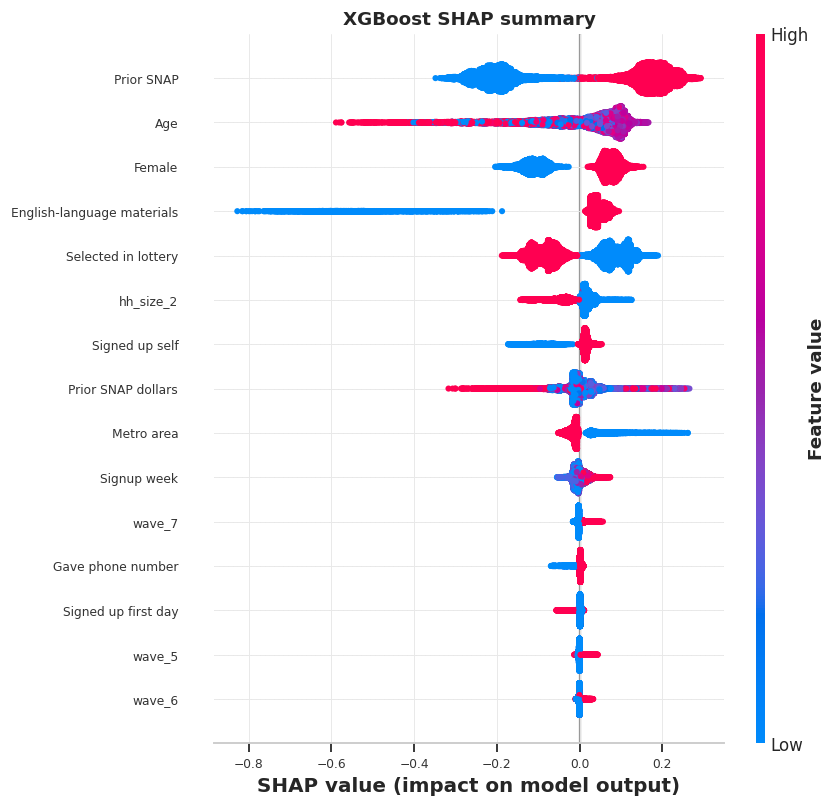

In [445]:
# Now, lets get SHAP values for the XGBoost model
# Each value is one predictors contribution to one respondents prediction, relative to the average
explainer = shap.TreeExplainer(full_models["xgboost"])
shap_values = explainer.shap_values(X_fit)
shap.summary_plot(shap_values, X_fit, max_display = 15, show = False, feature_names = [labels.get(x, x) for x in X_fit.columns])
plt.title("XGBoost SHAP summary")
# SHAP overrides the default axis labelsize we set at the beginning, so lets update it here
plt.tick_params(axis = "both", labelsize = plt.rcParams["xtick.labelsize"])
plt.tight_layout()
fig.savefig(f"{OUTPUT}/shap.png")
plt.show()

SHAP values decompose each XGBoost prediction into per-feature contributions on the log-odds scale, and mean absolute SHAP ranks features by the average size of that contribution. Prior SNAP recipient tops the list at 0.19, roughly twice any other feature. Age, female, English, and the selected in lottery indicator form a second tier at 0.085 to 0.09, with a sharp drop to the third tier of household size of 2, self signup, prior SNAP dollars, and metro residence at 0.025 to 0.027.

## 7. Causal Inference

---

Estimates the effect of the lottery offer (ITT) and of enrolling (LATE) on medical debt. The propensity score is known form the design (offer rate within household size and survey wave), and covariate balance is checked before estimation. Four estimators are compared: weighted OLS, 2SLS, g-computation, and AIPW.

---

This section includes:

- 7.1. Propensity Scores
- 7.2. Covariate Balance Check
- 7.3. Intention-to-Treat (ITT): OLS
- 7.4. Local Average Treatment Effect (LATE): 2SLS
- 7.5. G-Computation
- 7.6. AIPW
- 7.7. Summary of Causal Estimates

### 7.1. Propensity Scores

Rosenbaum and Rubin (1983) define the propensity score as the probability of treatment given a person's observed characteristics:

$$e(X_i) = P(Z_i = 1 \mid X_i)$$

where $Z_i$ is the treatment indicator for person $i$ (1 if treated, 0 if not) and $X_i$ is their vector of observed covariates.

Its key property is that it is a balancing score: among people with the same propensity score, the observed covariates are distributed the same way in the treated and untreated groups, so comparing outcomes at a fixed score removes confounding by those covariates. In an observation study the score must be estimated from a model of treatment on covariates. In a randomized experiment it is known, because the design set the assignment probabilities.

In this study, OHIE is a randomized experiment, so the propensity score comes from the design. The lottery drew at random, but households with more members had more entries, and the survey went out in waves tied to the seven drawings, so the chance of winning depended on household size and survey wave. Using $S_i$ for the person's household-size by wave cell:

$$e_i = \Pr(Z_i = 1 \mid X_i) = \Pr(Z_i = 1 \mid S_i)$$

Within a cell, that probability is the share of the cell that won. Using survey weights $w_j$ instead of raw counts, so the share reflects the full lottery list rather than only survey respondents, the estimate is the weighted average of the win indicator $Z_j$ over everyone in the cell:

$$e(S_i) = \frac{\sum_{j: S_j = S_i} w_j Z_j}{\sum_{j: S_j = S_i} w_j}$$

where $Z_i$ is 1 if person $i$ won the lottery and 0 otherwise, $S_i$ is the household-size by survey-wave cell that person $i$ belongs to, $j$ indexes every respondent in that same cell, and $w_j$ is respondent $j$'s survey weight.

The positivity assumption requires $0 < e(S_i) < 1$ for every stratum, so that each household-size by wave cell contains both winners and non-winners.

Since the score is known from the design rather than estimated from a model, so AIPW below does not depend on a correctly specified propensity model.

<br>

*References:*

*Rosenbaum, Paul R., and Donald B. Rubin. The Central Role of the Propensity Score in Observational Studies for Causal Effects. n.d.*

*Austin, Peter C. “An Introduction to Propensity Score Methods for Reducing the Effects of Confounding in Observational Studies.” Multivariate behavioral research vol. 46,3 (2011): 399-424. doi:10.1080/00273171.2011.568786. https://pmc.ncbi.nlm.nih.gov/articles/PMC3144483/*

*Hernán MA, Robins JM (2020). Causal Inference: What If. Boca Raton: Chapman & Hall/CRC. https://miguelhernan.org/whatifbook*

*Claude Fable 5 (Anthropic). Used to understand and explain the propensity score and how the general definition reduces to the within-stratum offer rate used in this study.*

In [446]:
# Lets check if the distribution of treatments is consistent across waves
# If not, we will need to account for that in our propensity score
# Note: To learn how to check the distribution of treatments design variables and pre-lottery variables
  # Claude Fable 5. Based on the response to prompt: "Before conducting the causal analysis, I want to compare the distributions between design variables (household size and survey wave) and all covariates
  # to ensure that the randomization "lottery" worked"
df.groupby(["hh_size", "wave"]).apply(lambda g: np.average(g["treatment"], weights = g["weight"])).unstack()

/tmp/ipykernel_1465/555457878.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby(["hh_size", "wave"]).apply(lambda g: np.average(g["treatment"], weights = g["weight"])).unstack()


wave,1,2,3,4,5,6,7
hh_size,,,,,,,
1,0.608113,0.602930,0.645898,0.436919,0.442935,0.427705,0.346493
2,0.696955,0.738527,0.714314,0.550076,0.517096,0.372759,0.365343
3,0.797623,0.919893,0.914790,NaN,NaN,NaN,NaN


The treated share is not constant across household sizes and waves. Within a wave, the proportion of those treated rises with household size (e.g., 0.61, 0.70, 0.80 for wave 1), and within household size it falls across waves (e.g., drops from 0.61 in wave 1 to 0.35 in wave 7 for single-person households). These are features of the study design, where larger households have more draws and earlier waves were tied to earlier drawings. Moving forward, the propensity score will be defined per household size by wave cell, to account for these design patterns in the causal models.

In [447]:
# We also need to incorporate for the survey weights, to ensure the estimates are representative of the full lottery list rather than only those who responded
w = df["weight"]
w_fit = w[fit_data]
# Create a treatment indicator for the fit sample
t_fit = df.loc[fit_data, treatment]
# Drop the treatment variable from the covariates, since that is handled seperately in the causal methods
X_causal = X_fit.drop(columns = [treatment])

# Now, lets calculate our propensity scores, or the respondents probability of receiving treatment (lottery offer)
# Based on the study design, we know that the probability of treatment is based on household size
# And based on the distriubtion above, we can also see that it is associated with the survey wave
e_offer = (df.groupby(["hh_size", "wave"])[["treatment", "weight"]]).apply(lambda g: np.average(g["treatment"], weights = g["weight"]))
# Assign each respondent the offer rate for their group (household size x wave)
df["e_offer"] = df.set_index(["hh_size", "wave"]).index.map(e_offer)
# Finally, lets confirm that all values are within 0 and 1 (no values should be exactly or approximately 0 or 1), to confirm that every group has both
# winners and non-winners, so that all respondents had some chance of recieving treatment
df["e_offer"].describe()

,e_offer
count,23740.000000
mean,0.500365
std,0.126233
min,0.346493
25%,0.427705
50%,0.442935
75%,0.608113
max,0.919893


Every respondent has a propensity score, ranging from 0.35 to 0.92. No cell is near 0 or 1, so every stratum contains both winners and non-winners and the positivity assumption holds.

In [448]:
# Check for NA propensity score, since every respondent should have a propensity score
check("PROPENSITY SCORE MISSINGNESS CHECK", df["e_offer"].notna().all())
check("PROPENSITY SCORE BOUNDARY CHECK", df["e_offer"].between(0.05, 0.95).all(), f"min {df['e_offer'].min():.3f}, max {df['e_offer'].max():.3f}")

[PASS] PROPENSITY SCORE MISSINGNESS CHECK
[PASS] PROPENSITY SCORE BOUNDARY CHECK: min 0.346, max 0.920


### 7.2. Covariate Balance Check

In [449]:
# Create a new sample for regression-based estimates
cf = df.loc[fit_data].copy()
# Define the fixed effects for the design strata (household size interacted with survey wave)
design_fe = "C(hh_size) * C(wave)"
# Also, lets create a variable for the pre-lottery covariates that we want to check the balance for
balance_variables = [p for p in predictors if p not in ["any_program_pre"]]

rows = []
for variable in balance_variables:
    m = smf.wls(f"{variable} ~ {treatment} + {design_fe}", data = cf, weights = cf["weight"]).fit(cov_type = "cluster", cov_kwds = {"groups": cf["household_id"]})
    rows.append({
        "Variable": variable,
        "Control Mean": cf.loc[cf[treatment] == 0, variable].mean(),
        "Treatment Mean": cf.loc[cf[treatment] == 1, variable].mean(),
        "SE": m.bse[treatment],
        "p": m.pvalues[treatment]
    })
balance = pd.DataFrame(rows).set_index("Variable").round(4)
balance

/tmp/ipykernel_1465/2031341905.py:10: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = smf.wls(f"{variable} ~ {treatment} + {design_fe}", data = cf, weights = cf["weight"]).fit(cov_type = "cluster", cov_kwds = {"groups": cf["household_id"]})
/tmp/ipykernel_1465/2031341905.py:10: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = smf.wls(f"{variable} ~ {treatment} + {design_fe}", data = cf, weights = cf["weight"]).fit(cov_type = "cluster", cov_kwds = {"groups": cf["household_id"]})
/tmp/ipykernel_1465/2031341905.py:10: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = smf.wls(f"{variable} ~ {treatment} + {design_fe}", data = cf, weights = cf["weight"]).fit(cov_type = "cluster", cov_kwds = {"groups": cf["household_id"]})
/tmp/ipykernel_1465/2031341905.py:10: SingularMatrixWarning: The design m

,Control Mean,Treatment Mean,SE,p
Variable,,,,
age,42.2966,42.1859,0.1921,0.6618
female,0.5999,0.5852,0.0069,0.6577
english,0.9210,0.9115,0.0049,0.8933
self_signup,0.8800,0.8355,0.0027,0.5547
has_phone,0.8939,0.9014,0.0038,0.1086
pobox,0.1269,0.1269,0.0054,0.6871
metro,0.7499,0.7453,0.0071,0.8997
signup_week,2.5610,2.5316,0.0253,0.2370
signup_first_day,0.1013,0.1063,0.0049,0.1767


In [450]:
# Lets also run a joint test, where we regress treatment on all covariates, to test if the covariates can predict it
# If randomization truly worked, F statistic should be near 1 and p-value should be well above 0.05
m_joint = smf.wls(f"{treatment} ~ {" + ".join(balance_variables)} + {design_fe}", data = cf, weights = cf["weight"]).fit(cov_type = "cluster", cov_kwds = {"groups": cf["household_id"]})
f_test = m_joint.f_test(" = ".join(balance_variables) + " = 0")

# Check the f-test p value for the balance of covariates between treatment groups
check("COVARIATE BALANCE P-VALUE CHECK", f_test.pvalue > 0.05, f"p = {float(f_test.pvalue):.3f}")

[PASS] COVARIATE BALANCE P-VALUE CHECK: p = 0.493


/tmp/ipykernel_1465/3309332054.py:3: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m_joint = smf.wls(f"{treatment} ~ {" + ".join(balance_variables)} + {design_fe}", data = cf, weights = cf["weight"]).fit(cov_type = "cluster", cov_kwds = {"groups": cf["household_id"]})


Within the design strata, no pre-lottery covariate differs meaningfully between lottery winners and non-winners. Differences are small relative to their standard errors and all p-values exceed 0.05, with the exception of Prior TANF dollars (p = 0.051), which is a borderline result that is to be expected from testing fourteen different covariates. This results confirm that randomization was successful.

### 7.3. Intention-to-Treat (ITT): OLS

In a trial where people are randomly assigned to treatment, not everyone assigned actually takes it. The intention-to-treat (ITT) effect is the effect of being assigned to treatment, regardless of whether it was received or adhered to. The effect of the treatment itself requires further assumptions and is estimated separately in *Section 7.4*. The ITT is the primary estimand in most trials because it relies only on randomization: assignment is independent of everything that affects the outcome, so a simple comparison of assigned and unassigned groups is unbiased. Where $Y_i(1)$ is the outcome a person would have if assigned and $Y_i(0)$ if not:

$$\text{ITT} = E[Y_i(1) - Y_i(0)]$$

In this study, assignment is the lottery offer and the outcome is medical debt at 12 months. The lottery was random, but the chance of winning differed by household size and survey wave, so winners and non-winners can only be compared fairly within the same household-size by wave cell (a pooled difference in means would mix the effect of winning with the fact that larger households were both more likely to win and different in other ways). Finkelstein et al. (2012) estimate the effect of winning the lottery with the regression:

$$y_{ihj} = \beta_0 + \beta_1 \text{LOTTERY}_h + X_{ih}\beta_2 + V_{ih}\beta_3 + \varepsilon_{ihj}$$

where $y_{ihj}$ is outcome $j$ for person $i$ in household $h$, $\text{LOTTERY}_h$ is whether the household was selected in the lottery, $X_{ih}$ are the covariates that affect the chance of selection and must be controlled for (indicators for household size and survey wave, and their interactions), $V_{ih}$ are optional covariates that can improve precision but are not needed for an unbiased estimate (none are used for the survey outcomes), and $\varepsilon_{ihj}$ is the error term. $\beta_1$ is the intention-to-treat effect: the average difference in outcome between winners and non-winners who had the same chance of winning.

The assumption behind this is that, within a cell, winning was unrelated to anything that affects medical debt.

<br>

*References:*

*Finkelstein, Amy et al. “THE OREGON HEALTH INSURANCE EXPERIMENT: EVIDENCE FROM THE FIRST YEAR.” The quarterly journal of economics vol. 127,3 (2012): 1057-1106. doi:10.1093/qje/qjs020*

*Hernán MA, Robins JM (2020). Causal Inference: What If. Boca Raton: Chapman & Hall/CRC. https://miguelhernan.org/whatifbook*

*Claude Fable 5 (Anthropic). Used to understand and explain the intention-to-treat effect and how the OHIE regression equation relates to this study.*

In [451]:
# Now, lets perform our intention-to-treat analysis, which measures the effect of a lottery offer for each outcome
# Note: To learn how to perform weighted OLS as the intention-to-treat effect baseline
  # Claude Fable 5. Based on the response to prompt: "How can I perform a basic intention-to-treat causal analysis, including weights and design fixed effects"
# Loop through each of our four outcomes, performing weighted OLS for each and saving the results in a list
rows = []
for loop_outcome in outcomes:
    # Drop outcome-specific missing observations
    d = cf.dropna(subset = [loop_outcome])
    # Perform weighted OLS, using the current loop's outcome, treatment (lottery offer), design fixed effects, and survey weights
    m = smf.wls(f"{loop_outcome} ~ {treatment} + {design_fe}", data = d, weights = d["weight"]).fit(cov_type = "cluster", cov_kwds = {"groups": d["household_id"]})
    # Add this outcomes results to a list, including the mean values for each group (control vs treatment)
    rows.append({
        "Outcome": loop_outcome,
        "n": len(d),
        "ITT": m.params[treatment],
        "Control Mean": np.average(d.loc[d[treatment] == 0, loop_outcome], weights = d.loc[d[treatment] == 0, "weight"]),
        "Treatment Mean": np.average(d.loc[d[treatment] == 1, loop_outcome], weights = d.loc[d[treatment] == 1, "weight"]),
        "Raw Difference": np.average(d.loc[d[treatment] == 1, loop_outcome], weights = d.loc[d[treatment] == 1, "weight"]) - np.average(d.loc[d[treatment] == 0, loop_outcome], weights = d.loc[d[treatment] == 0, "weight"]),
        "SE": m.bse[treatment],
        "CI Low": m.conf_int().loc[treatment, 0],
        "CI High": m.conf_int().loc[treatment, 1],
        "p": m.pvalues[treatment]
    })

# Combine into a single table, one row per outcome
itt = pd.DataFrame(rows).set_index("Outcome").round(4)
itt


/tmp/ipykernel_1465/441776735.py:10: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = smf.wls(f"{loop_outcome} ~ {treatment} + {design_fe}", data = d, weights = d["weight"]).fit(cov_type = "cluster", cov_kwds = {"groups": d["household_id"]})
/tmp/ipykernel_1465/441776735.py:10: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = smf.wls(f"{loop_outcome} ~ {treatment} + {design_fe}", data = d, weights = d["weight"]).fit(cov_type = "cluster", cov_kwds = {"groups": d["household_id"]})
/tmp/ipykernel_1465/441776735.py:10: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = smf.wls(f"{loop_outcome} ~ {treatment} + {design_fe}", data = d, weights = d["weight"]).fit(cov_type = "cluster", cov_kwds = {"groups": d["household_id"]})
/tmp/ipykernel_1465/441776735.py:10: SingularMatrixWarning: The design ma

,n,ITT,Control Mean,Treatment Mean,Raw Difference,SE,CI Low,CI High,p
Outcome,,,,,,,,,
medical_debt,23450,-0.0523,0.5966,0.5375,-0.0592,0.0076,-0.0673,-0.0374,0.000
borrowed_or_skipped,23266,-0.0449,0.3651,0.3169,-0.0482,0.0074,-0.0593,-0.0304,0.000
refused_care,22432,-0.0103,0.0814,0.0689,-0.0124,0.0041,-0.0183,-0.0023,0.012
any_oop,23206,-0.0586,0.5550,0.4943,-0.0607,0.0077,-0.0737,-0.0436,0.000


The table reports three related quantities. The control and treatment means are the survey-weighted outcome rates in each arm, pooled over the whole sample. The ITT is the difference between the winners and non-winners estimated within each household-size by wave stratum and then averaged. The two differ slightly because the share of winners varies across strata, so the pooled treatment group has a different mix of household sizes and survey waves than the pooled control group. The ITT is the more robust and reliable estimate, and will be used moving forward.

Winning the lottery reduced the probability of owing money for medical expenses by 5.2 percentage points (SE 0.6). The control mean was 59.7% and the treatment mean was 53.8%, a raw gap of 5.9 points. The other three outcomes follow the same pattern: winning reduced borrowing or skipping bills by 4.5 percentage points, being refused care for past medical debt by 1.0 percentage point, and any out-of-pocket spending by 5.9 percentage points. All four ITTs are statistically distinguishable from zero (p < 0.02 for refused_care, p < 0.001 for medical debt, borrowed_or_skipped, and any_oop).

### 7.4. Local Average Treatment Effect (LATE): 2SLS

The ITT in *Section 7.3* is the effect of being offered coverage. Only about a quarter of winners actually enrolled, so the effect of enrollment itself is larger than the effect of the offer. The lottery can be used as an instrument for enrollment, since it shifts who enrolls, and because it was random, it is unrelated to anything else that affects the outcome. The resulting estimate is the local average treatment effect (LATE), the effect of enrollment among compliers, people who enrolled because they won and would not have enrolled otherwise.

Finkelstein et al. (2012) estimate the LATE by two-stage least squares, with the same household-size and wave controls as the ITT regression:

$$\text{First stage:} \quad \text{INSURANCE}_{ih} = \delta_0 + \delta_1 \text{LOTTERY}_h + X_{ih}\delta_2 + V_{ih}\delta_3 + \mu_{ih}$$

$$\text{Second stage:} \quad y_{ihj} = \pi_0 + \pi_1 \text{INSURANCE}_{ih} + X_{ih}\pi_2 + V_{ih}\pi_3 + \nu_{ihj}$$

where $\text{INSURANCE}_{ih}$ is whether person $i$ in household $h$ was ever enrolled in Medicaid during the study period, all other variables are as defined in *Section 7.3*, and $\mu_{ih}$ and $\nu_{ihj}$ are the error terms. $\delta_1$ is the first-stage effect of winning on enrollment, and $\pi_1$ is the LATE, the effect of enrollment among compliers.

The first stage predicts enrollment from the lottery. The second stage uses that prediction in place of actual enrollment, so $\pi_1$ picks up only the part of enrollment that was caused by winning the lottery.

Beyond randomization, identification requires the exclusion restriction (winning affects medical debt only through enrollment) and monotonicity (no one enrolled because they lost). Both are plausible here since the lottery offered nothing other than the chance to apply.

<br>

*References:*

*Finkelstein, Amy et al. “THE OREGON HEALTH INSURANCE EXPERIMENT: EVIDENCE FROM THE FIRST YEAR.” The quarterly journal of economics vol. 127,3 (2012): 1057-1106. doi:10.1093/qje/qjs020*

*Claude Fable 5 (Anthropic). Used to understand and explain the LATE and how the OHIE two-stage least squares specification applies to this study.*

In [452]:
# Note: To learn how to perform 2SLS for LATE
  # Claude Fable 5. Based on the response to prompt: "How can I estimate LATE for the effect of medicaid enrollment on the four outcomes of interest."
# Loop through each of our four outcomes, performing 2SLS for each and saving the results in a list
rows = []
for loop_outcome in outcomes:
    # Drop outcome-specific missing observations
    d = cf.dropna(subset = [loop_outcome]).copy()
    # IV2SLS requires a float outcome
    d[loop_outcome] = d[loop_outcome].astype(float)
    # Create fixed effects, where each household size x wave combination gets its own dummy variable, with one as the reference
    fe = pd.get_dummies(d["hh_size"].astype(str) + "_" + d["wave"].astype(str), drop_first = True, dtype = float)
    exog = sm.add_constant(fe)
    # Perform IV2SLS using the lottery offer as the instrument, accounting for survey weights
    m = IV2SLS(dependent = d[loop_outcome], exog = exog, endog = d[mediator], instruments = d[treatment], weights = d["weight"]).fit(cov_type = "clustered", clusters = d["household_id"])
    # Add this outcomes results to a list
    rows.append({
        "Outcome": loop_outcome,
        "n": len(d),
        "LATE": m.params[mediator],
        "SE": m.std_errors[mediator],
        "CI Low": m.conf_int().loc[mediator, "lower"],
        "CI High": m.conf_int().loc[mediator, "upper"],
        "p": m.pvalues[mediator]
    })

# Combine into a single table, one row per outcome
late = pd.DataFrame(rows).set_index("Outcome").round(4)
late

,n,LATE,SE,CI Low,CI High,p
Outcome,,,,,,
medical_debt,23450,-0.1798,0.0264,-0.2316,-0.1280,0.000
borrowed_or_skipped,23266,-0.1547,0.0252,-0.2041,-0.1052,0.000
refused_care,22432,-0.0356,0.0142,-0.0633,-0.0078,0.012
any_oop,23206,-0.2013,0.0263,-0.2528,-0.1499,0.000


Among compliers, people who enrolled in Medicaid because they won the lottery and would not have otherwise, enrollment reduced medical debt by 18.0 percentage points (SE 2.6), borrowing or skipping bills by 15.5 percentage points, being refused care by 3.6 percentage points, and any out-of-pocket spending by 20.1 percentage points.

### 7.5. G-Computation

G-computation estimates the average treatment effect (ATE) by standardization: fit a model for the outcome given treatment and covariates, use it to predict each person's outcome under treatment and under no treatment, and average the predictions:

$$\hat{\mu}_1 = \frac{1}{n}\sum_{i=1}^n \hat{Y}_i^{A=1}, \qquad \hat{\mu}_0 = \frac{1}{n}\sum_{i=1}^n \hat{Y}_i^{A=0}$$

$$\text{ATE} = \hat{\mu}_1 - \hat{\mu}_0$$

where $\hat{Y}_i^{A=1}$ and $\hat{Y}_i^{A=0}$ are the model's predicted outcomes for person $i$ with treatment $A$ set to 1 and to 0, $\hat{\mu}_1$ and $\hat{\mu}_0$ are their averages over all $n$ people, and the ATE is the difference between the two.

Here the treatment is the lottery offer, so the ATE of the offer is the ITT.

The outcome models are cross-fitted on the household folds from *Section 6*.

The estimator depends entirely on the outcome models. If they are misspecified the estimate is biased, and the method has no built-in correction.

<br>

*References:*

*Mustafa, Akif. “A Short Introduction to G-Computation in Causal Inference.” Medium, September 2, 2025. https://medium.com/@akif.iips/a-short-introduction-to-g-computation-in-causal-inference-9a67bd9e2233.*

*Claude Fable 5 (Anthropic). Used to understand and explain g-computation and how the standard estimator extends to survey weights and per-arm models in this study.*

In [453]:
# Now, lets estimate the ITT by g-computation
# Note: To learn how to perform g-computation
  # Claude Fable 5. Based on the response to prompt: "I want to perform g-computation to estimate the causal effect of a lottery offer, using an existing xgboost model."
# Here, we model the outcome separately for each arm (control vs treatment), predicting both potential outcomes for everyone and averaging the difference
# Lets reuse the same tuned xgboost from the earlier
xgb_params = xgb_search.best_params_ | {"colsample_bytree": 0.8, "random_state": SEED, "n_jobs": -1}
t_c = t_fit.to_numpy()
w_c = w_fit.to_numpy()

# Store the predictions per outcome
mu = {}
gcomp_rows = []
for loop_outcome in outcomes:
    # Retrieve the rows where the outcome is specific observed
    obs = df.loc[fit_data, loop_outcome].notna().to_numpy()
    y_c = df.loc[fit_data, loop_outcome].to_numpy(dtype = float)
    # Predicted outcome under treatment (mu1) and udner control (mu0) for every respondent
    mu1 = np.full(len(y_c), np.nan)
    mu0 = np.full(len(y_c), np.nan)

    # Cross-fit on the household-group folds, so no respondent is predicted by a model trained on their own household
    for train, test in folds:
        # Keep only rows where the outcome is observed
        train = train[obs[train]]
        test = test[obs[test]]
        # Split the training fold by arm (control vs treatment)
        tr0 = train[t_c[train] == 0]
        tr1 = train[t_c[train] == 1]
        # Fit each arms model and predict the held-out fold, giving potential outcomes for everyone in it
        mu0[test] = XGBClassifier(**xgb_params).fit(X_causal.iloc[tr0], y_c[tr0]).predict_proba(X_causal.iloc[test])[:, 1]
        mu1[test] = XGBClassifier(**xgb_params).fit(X_causal.iloc[tr1], y_c[tr1]).predict_proba(X_causal.iloc[test])[:, 1]

    mu[loop_outcome] = (mu0, mu1, obs)
    # Add the results to the list
    gcomp_rows.append({
        "Outcome": loop_outcome,
        "n": obs.sum(),
        "G-Computation": np.average((mu1 - mu0)[obs], weights = w_c[obs])
    })

# G computation effect is the survey-weighted average difference between the two model prediction
gcomp = pd.DataFrame(gcomp_rows).set_index("Outcome")
gcomp

,n,G-Computation
Outcome,,
medical_debt,23450,-0.056221
borrowed_or_skipped,23266,-0.052878
refused_care,22432,-0.011634
any_oop,23206,-0.063857


G-computation gives -5.6 percentage points for medical debt, -5.3 percentage points for borrowing or skipping bills, -1.2 for being refused care, and -6.4 for any out-of-pocket spending. These are slightly higher than the corresponding OLS ITT, but within one standard error of each. The difference likely reflects the difference in approach: OLS estimates one treatment coefficient within design strata, while g-computation relies on two XGBoost outcome models, one per arm. Still, the close agreement between the two approaches acts as an robustness check and gives additional confidence in the results.  

### 7.6. AIPW

AIPW combines the outcome models with the propensity score. It starts from each arm's g-computation prediction and adds a correction: for people actually in that arm, the residual $Y_i - \hat{\mu}(X_i)$ (observed outcome minus predicted), weighted by one over their propensity score.

$$\hat{\mu}_1^{\text{AIPW}} = \frac{1}{n}\sum_{i=1}^n \left[\hat{\mu}_1(X_i) + \frac{A_i\,(Y_i - \hat{\mu}_1(X_i))}{e_i}\right], \qquad \hat{\mu}_0^{\text{AIPW}} = \frac{1}{n}\sum_{i=1}^n \left[\hat{\mu}_0(X_i) + \frac{(1 - A_i)\,(Y_i - \hat{\mu}_0(X_i))}{1 - e_i}\right]$$

$$\text{ATE} = \hat{\mu}_1^{\text{AIPW}} - \hat{\mu}_0^{\text{AIPW}}$$

where $A_i$ is person $i$'s treatment indicator, $Y_i$ is their observed outcome, $\hat{\mu}_1(X_i)$ and $\hat{\mu}_0(X_i)$ are the g-computation predictions from *Section 7.5*, and $e_i$ is the propensity score from *Section 7.1*.

The estimator is doubly robust, so it is consistent if either the outcome model or the propensity score is correct.

Because the propensity score is known from the lottery design, the estimate is consistent regardless of how well the outcome models fit.

Positivity, which the correction terms require, was confirmed in *Section 7.1*.

<br>

*References:*

*Luharuka, Shubham. “Understanding Augmented Inverse Propensity Weighting (AIPW) in Causal Inference.” Medium, January 21, 2026. https://luharuka.medium.com/understanding-augmented-inverse-propensity-weighting-aipw-in-causal-inference-c724b1e14973.*

*Matteo Courthoud. “Understanding AIPW.” July 10, 2023. https://matteocourthoud.github.io/post/aipw/.*

*Claude Fable 5 (Anthropic). Used to understand and explain AIPW and how it extends to survey weights and the known design propensity score in this study.*


In [454]:
# Now, lets estimate the ITT by AIPW
# Note: To learn how to perform AIPW
  # Claude Fable 5. Based on the response to prompt: "Now, I want to perform AIPW to estimate the causal effect of a lottery offer."
# First, lets create a reusable helper function for survey-weighted mean and household-clustered standard error
def clustered_se(scores, weights, clusters):
    s = pd.DataFrame({"sw": scores * weights, "w": weights, "g": clusters}).groupby("g").sum()
    n_g = len(s)
    # Weighted mean of the scores
    est = s["sw"].sum() / s["w"].sum()
    # Household-level residuals from the weighted mean, with a small-sample correction
    resid = s["sw"] - est * s["w"]
    return est, np.sqrt(n_g / (n_g - 1) * (resid ** 2).sum()) / s["w"].sum()

# AIPW for the effect of a lottery offer on medical debt
e_fit = df.loc[fit_data, "e_offer"]
e_c = e_fit.to_numpy()

# Loop through each outcome of interest, performing AIPW for each
aipw_rows = []
for loop_outcome in outcomes:
    # Reuse the cross-fitted potential outcome prediction from g-computation
    mu0, mu1, obs = mu[loop_outcome]
    y_c = df.loc[fit_data, loop_outcome].to_numpy(dtype = float)

    # Calculate our doubly robust scores, using the model prediction and the propensity-weighted residual for the arm actually observed
    # If the outcome model is wrong, the residual term corrects it, if the propensity score is wrong, the model term still holds
    gamma0 = mu0 + (1 - t_c) * (y_c - mu0) / (1 - e_c)
    gamma1 = mu1 + t_c * (y_c - mu1) / e_c
    psi = gamma1 - gamma0
    est, se = clustered_se(psi[obs], w_c[obs], groups_fit.to_numpy()[obs])
    aipw_rows.append({
        "Outcome": loop_outcome,
        "n": obs.sum(),
        "AIPW": est,
        "SE": se,
        "CI Low": est - 1.96 * se,
        "CI High": est + 1.96 * se
    })

    # Lets also save the primary outcome scores for the policy simulation later on
    if loop_outcome == outcome:
        gamma0_primary, gamma1_primary, psi_primary = gamma0, gamma1, psi

# Combine into a single table, one row per outcome
aipw = pd.DataFrame(aipw_rows).set_index("Outcome")
aipw

,n,AIPW,SE,CI Low,CI High
Outcome,,,,,
medical_debt,23450,-0.052236,0.007547,-0.067028,-0.037444
borrowed_or_skipped,23266,-0.045382,0.007375,-0.059838,-0.030926
refused_care,22432,-0.009920,0.004080,-0.017916,-0.001924
any_oop,23206,-0.058388,0.007607,-0.073299,-0.043478


AIPW gives -5.2 percentage points for medical debt (95% CI -6.7 to -3.7), -4.5 for borrowing or skipping bills (95% CI -6.0 to -3.1), -1.0 for being refused care (95% CI -1.8 to -0.2), and -5.8 for any out-of-pocket spending (95% CI -7.3 to -4.3). These match the OLS ITT estimates within 0.1 percentage point for every outcome. The augmentation term, which adds the propensity-weighted residual to each outcome model prediction, has pulled the g-computation estimates back toward the design-based values. With a known propensity score, AIPW is consistent regardless of how well the outcome model fit, and the agreement with OLS confirms the implementation and the cross-fitted outcome models are behaving as intended.

### 7.7. Summary of Causal Estimates

In [455]:
# Lets create a single table for comparing and reporting the results across all estimands and estimators
rows = []
for loop_outcome in outcomes:
    # Three estimators for ITT (OLS, g-computation, AIPW), and one for LATE (2SLS)
    # G-computation has no SE, so it is set to NaN
    rows += [
        {"Outcome": loop_outcome, "Estimand": "ITT", "Estimator": "OLS", "Estimate": itt.loc[loop_outcome, "ITT"], "SE": itt.loc[loop_outcome, "SE"]},
        {"Outcome": loop_outcome, "Estimand": "ITT", "Estimator": "G-Computation", "Estimate": gcomp.loc[loop_outcome, "G-Computation"], "SE": np.nan},
        {"Outcome": loop_outcome, "Estimand": "ITT", "Estimator": "AIPW", "Estimate": aipw.loc[loop_outcome, "AIPW"], "SE": aipw.loc[loop_outcome, "SE"]},
        {"Outcome": loop_outcome, "Estimand": "LATE", "Estimator": "2SLS", "Estimate": late.loc[loop_outcome, "LATE"], "SE": late.loc[loop_outcome, "SE"]},
    ]

causal_summary = pd.DataFrame(rows)
# Calculate the 95% CI, based on the estimate and SE
causal_summary["CI Low"] = causal_summary["Estimate"] - 1.96 * causal_summary["SE"]
causal_summary["CI High"] = causal_summary["Estimate"] + 1.96 * causal_summary["SE"]

# Display one table per outcome, using the label as the header for readability
for loop_outcome in outcomes:
    print(f"{labels[loop_outcome]}:")
    display(causal_summary[causal_summary["Outcome"] == loop_outcome].round(4))

Currently owe money for medical expenses:


,Outcome,Estimand,Estimator,Estimate,SE,CI Low,CI High
0,medical_debt,ITT,OLS,-0.0523,0.0076,-0.0672,-0.0374
1,medical_debt,ITT,G-Computation,-0.0562,NaN,NaN,NaN
2,medical_debt,ITT,AIPW,-0.0522,0.0075,-0.0670,-0.0374
3,medical_debt,LATE,2SLS,-0.1798,0.0264,-0.2315,-0.1281


Borrowed money/skipped bills to pay health care bills in last 6 months?:


,Outcome,Estimand,Estimator,Estimate,SE,CI Low,CI High
4,borrowed_or_skipped,ITT,OLS,-0.0449,0.0074,-0.0594,-0.0304
5,borrowed_or_skipped,ITT,G-Computation,-0.0529,NaN,NaN,NaN
6,borrowed_or_skipped,ITT,AIPW,-0.0454,0.0074,-0.0598,-0.0309
7,borrowed_or_skipped,LATE,2SLS,-0.1547,0.0252,-0.2041,-0.1053


Have you been refused care because you owed money for a past treatment?:


,Outcome,Estimand,Estimator,Estimate,SE,CI Low,CI High
8,refused_care,ITT,OLS,-0.0103,0.0041,-0.0183,-0.0023
9,refused_care,ITT,G-Computation,-0.0116,NaN,NaN,NaN
10,refused_care,ITT,AIPW,-0.0099,0.0041,-0.0179,-0.0019
11,refused_care,LATE,2SLS,-0.0356,0.0142,-0.0634,-0.0078


Any out of pocket costs for medical care in the past 6 months:


,Outcome,Estimand,Estimator,Estimate,SE,CI Low,CI High
12,any_oop,ITT,OLS,-0.0586,0.0077,-0.0737,-0.0435
13,any_oop,ITT,G-Computation,-0.0639,NaN,NaN,NaN
14,any_oop,ITT,AIPW,-0.0584,0.0076,-0.0733,-0.0435
15,any_oop,LATE,2SLS,-0.2013,0.0263,-0.2528,-0.1498


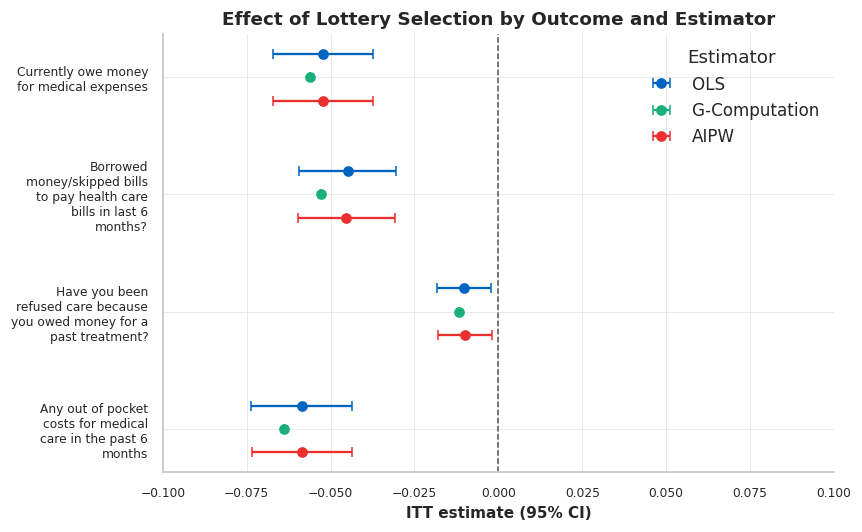

In [456]:
# Lets plot the ITT estimates for all three estimators, across all four outcomes
# Note: To learn how to create a forest-style plot of estimates with confidence intervals for ITT
  # Claude Fable 5. Based on the response to prompt: "How can I create a plot that shows the ITT estimate and CI for each estimator, across all four outcomes."
itt_rows = causal_summary[causal_summary["Estimand"] == "ITT"]
estimators = ["OLS", "G-Computation", "AIPW"]
# Add small vertical offsets so the three estimators being displayed dont overlap
offsets = {"OLS": -0.2, "G-Computation": 0, "AIPW": 0.2}

fig, ax = plt.subplots(figsize = (8, 5))
# For each estimator, plot the estimate and its 95% CI (note: g-computation does not have a 95% CI, so only plot the point)
for est in estimators:
    sub = itt_rows[itt_rows["Estimator"] == est]
    ypos = np.arange(len(outcomes)) + offsets[est]
    ax.errorbar(sub["Estimate"], ypos, xerr = 1.96 * sub["SE"].fillna(0), fmt = "o", capsize = 3, label = est)
# Add a reference line at 0 (value if no effect)
ax.axvline(0, linestyle = "--", color = COLORS["reference"], linewidth = 1.0)
ax.set_yticks(range(len(outcomes)))
# Use the readable labels (instead of the variable names) and use textwrap so they fit
ax.set_yticklabels([textwrap.fill(labels[y], width = 20) for y in outcomes], fontsize = 8)
# Invert y axis so the primary outcome is on top
ax.invert_yaxis()
# Center the plot around 0, so the direction of the effect is more clear
ax.set_xlim(-0.1, 0.1)
ax.set_xlabel("ITT estimate (95% CI)")
ax.set_title("Effect of Lottery Selection by Outcome and Estimator")
ax.legend(title = "Estimator")
plt.tight_layout()
fig.savefig(f"{OUTPUT}/itt.png")
plt.show()

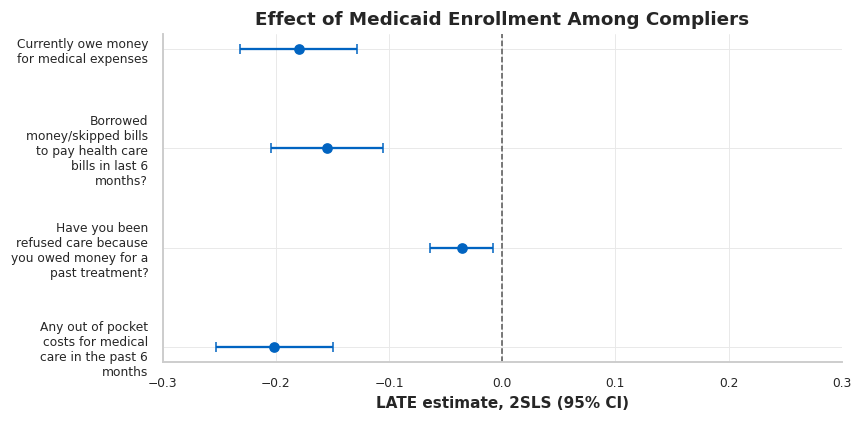

In [457]:
# Now, lets plot the LATE estimates across all four outcomes
# Note: To learn how to create a forest-style plot of estimates with confidence intervals for LATE
  # Claude Fable 5. Based on the response to prompt: "How can I create a plot that shows the LATE estimate and CI for all four outcomes."
late_rows = causal_summary[causal_summary["Estimand"] == "LATE"]

fig, ax = plt.subplots(figsize = (8, 4))
# One estimator, so one point per outcome
ax.errorbar(late_rows["Estimate"], range(len(outcomes)), xerr = 1.96 * late_rows["SE"], fmt = "o", capsize = 3)
# Add a reference line at 0 (value if no effect)
ax.axvline(0, linestyle = "--", color = COLORS["reference"], linewidth = 1.0)
ax.set_yticks(range(len(outcomes)))
# Use the outcome labels and wrap them, for readability
ax.set_yticklabels([textwrap.fill(labels[y], width = 20) for y in outcomes], fontsize = 8)
# Invert y axis so the primary outcome is on top
ax.invert_yaxis()
# Center the plot around 0, so the direction of the effect is more clear
ax.set_xlim(-0.3, 0.3)
ax.set_xlabel("LATE estimate, 2SLS (95% CI)")
ax.set_title("Effect of Medicaid Enrollment Among Compliers")
plt.tight_layout()
fig.savefig(f"{OUTPUT}/late.png")
plt.show()


Across all four outcomes, the three ITT estimators agree: OLS and AIPW are identical to three decimals and g-computation sits within one standard error. The ITT plot shows this directly, with the three points for each outcome overlapping and every confidence interval excluding zero. The LATE plot shows the same ordering of outcomes at roughly 3-4 times the scale.

This shows that the choice between OLS, g-computation, and AIPW does not affect the answer, and the value of the doubly robust estimator is as a check, not a correction. Moving forward, the per-person AIPW scores will be used as inputs for the policy simulation.

## 8. Heterogeneity

---

Asks whether the effect differs across people. A cross-fitted causal forest estimates person-level effects (Conditional Average Treatment Effects, or CATEs). A calibration test with sorted group effects (GATES) is used to test the validity of forest estimates, and prespecified subgroups (age group, sex, language preference, and prior SNAP/TANF participation) are investigated.

---

This section includes:

- 8.1. Causal Forest
- 8.2. CATE Distribution
- 8.3. Calibration Test & GATES
- 8.4. Subgroups Analysis: Age Group, Sex, Language, Prior SNAP/TANF
- 8.5. Forest Feature Importance

### 8.1. Causal Forest

A causal forest estimates the conditional average treatment effect (CATE), the effect for people with characteristics X $= x$:

$$\tau(x) = E[Y(1) - Y(0) \mid X = x]$$

It is a random forest whose splits are chosen to separate people with different treatment effects, rather than to predict the outcome. Within each leaf the effect is estimated from residuals, after removing what the covariates already predict about treatment (the propensity score) and about the outcome:

$$\hat{\tau}(x) = \frac{\sum_{i \in \text{leaf}} \left(W_i - \hat{p}(X_i)\right)\left(Y_i - \hat{m}(X_i)\right)}{\sum_{i \in \text{leaf}} \left(W_i - \hat{p}(X_i)\right)^2}$$

where $W_i$ is person $i$'s treatment indicator, $Y_i$ is their observed outcome, $\hat{p}(X_i)$ is their propensity score, $\hat{m}(X_i)$ is their predicted outcome from the covariates alone (ignoring treatment), and the sums run over everyone in the leaf that $x$ falls into.

Each tree is honest: one part of its sample grows the tree and a separate part estimates the effects, so the same data never both finds a pattern and measures it.

The forest is cross-fitted on the household folds from *Section 6*, with honest trees of at least 50 respondents per leaf and 1,000 trees averaged. Its predictions are tested in *Section 8.3* before being interpreted, since a flexible model can report heterogeneity that is not actually there.

<br>

*References:*

*Van Vogt, Eleanor, Anthony C. Gordon, Karla Diaz-Ordaz, and Suzie Cro. “Application of Causal Forests to Randomised Controlled Trial Data to Identify Heterogeneous Treatment Effects: A Case Study.” BMC Medical Research Methodology 25 (February 2025): 50. https://doi.org/10.1186/s12874-025-02489-2.*

*Claude Fable 5 (Anthropic). Used to understand and explain the causal forest and how the residualized, cross-fitted version in this study is set up.*

In [458]:
# Fit a causal forest to estimate the individual-level treatment effects (CATEs) for the primary outcome
# Note: To learn how to fit a cross-fitted causal forest
    # Claude Fable 5. Based on the response to the prompt: "How can I estimate heterogenous treatment effects with a causal forest?"
# Design variables (hh_size, wave) are handled by the residualization below, not by the forest, so lets drop them
X_het = X_causal.drop(columns = [c for c in X_causal.columns if c.startswith("hh_size_") or c.startswith("wave_")])

# Treatment residual (the actual offer minus the design propensity score)
t_res = t_c - e_c
# Outcome redisual (the actual outcome minus the propensity-weighted mix of cross-fitted g-computation predictions)
mu0_p, mu1_p, _ = mu[outcome]
y_c = y_fit.to_numpy(dtype = float)
y_res = y_c - (e_c * mu1_p + (1 - e_c) * mu0_p)

# Cross-fit using the same household folds, so each respondent's CATE comes from a forest that never saw their household
cate = np.full(len(y_c), np.nan)
cate_se = np.full(len(y_c), np.nan)
forest_models = []
for train, test in folds:
    # Use an honest forest (half of each tree's sample picks the splits, the other estimates the leaf effects, so predictions are not overfit)
    # Large leaves (50 respondents) and 1000 trees to keep each CATE stable
    # Inference = True returns a confidence interval for each
    cf_fold = CausalForest(
        n_estimators = 1000,
        min_samples_leaf = 50,
        max_depth = None,
        max_samples = 0.5,
        honest = True,
        inference = True,
        random_state = SEED,
        n_jobs = -1
    )
    cf_fold.fit(X_het.iloc[train], t_res[train], y_res[train], sample_weight = w_c[train])

    # Predict the held-out fold with 95% intervals
    pred, lb, ub = cf_fold.predict(X_het.iloc[test], interval = True, alpha = 0.05)
    cate[test] = pred.ravel()
    cate_se[test] = (ub.ravel() - lb.ravel()) / (2 * 1.96)
    # Keep each fold's forest for a feature importance plot
    forest_models.append(cf_fold)

# Print the results
print(f"Mean CATE: {np.average(cate, weights = w_c):.4f}")
print(f"CATE SD: {cate.std():.4f}, range {cate.min():.4f} to {cate.max():.4f}")

Mean CATE: -0.0529
CATE SD: 0.0316, range -0.2083 to 0.0691


### 8.2. CATE Distribution

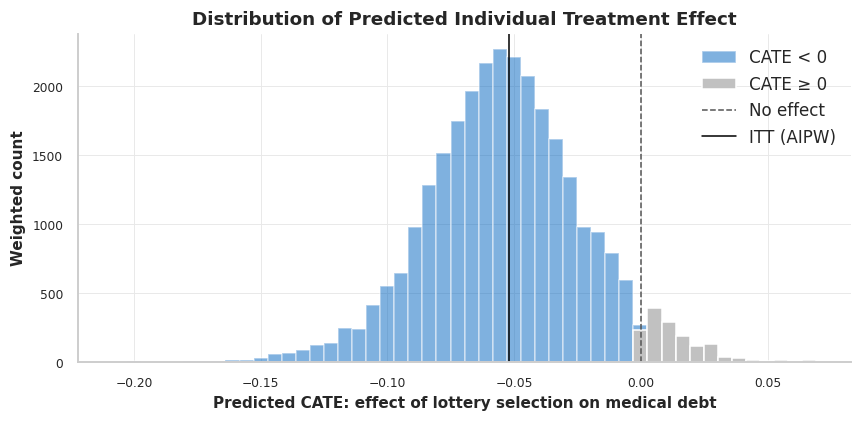

Share with CATE < 0: 0.948


In [459]:
# Now, lets plot the survey-weighted distribution of predicted CATEs
fix, ax = plt.subplots(figsize = (8, 4))
# Color the bins by CATE direction (less than 0 vs equal to or greater than 0)
# Shared bin edges so the two colors line up
edges = np.linspace(cate.min(), cate.max(), 51)
ax.hist(cate[cate < 0], bins = edges, weights = w_c[cate < 0], color = COLORS["treatment"], label = "CATE < 0", alpha = 0.5)
ax.hist(cate[cate >= 0], bins = edges, weights = w_c[cate >= 0], color = COLORS["control"], label = "CATE ≥ 0")
# Add a reference line at zero (no effect)
ax.axvline(0, linestyle = "--", color = COLORS["reference"], linewidth = 1.0, label = "No effect")
# Add a reference line for the AIPW estimate
ax.axvline(aipw.loc[outcome, "AIPW"], color = "black", linewidth = 1.0, label = "ITT (AIPW)")
ax.set_xlabel("Predicted CATE: effect of lottery selection on medical debt")
ax.set_ylabel("Weighted count")
ax.set_title("Distribution of Predicted Individual Treatment Effect")
ax.legend()
plt.tight_layout()
fig.savefig(f"{OUTPUT}/cate_distribution.png")
plt.show()

# Share of respondents the forest predicts to benefit from an offer
print(f"Share with CATE < 0: {np.average(cate < 0, weights = w_c):.3f}")

The cross-fitted CATEs are approximately centered around the ITT, with 95% of respondents predicted to benefit from an offer.

### 8.3. Calibration Test & GATE

In [460]:
# Now, test whether the forest's predicted heterogeneity is real, using AIPW scores as a baseline
# Note: To learn how to run a calibration test and sorted group treatment effects (GATES) for a causal forest
    # Claude Fable 5. Based on the response to the prompt: "How can I check whether the causal forest's CATE predictions are picking up real heterogeneity or are just noise?"
# First, run a calibration test by regressing the AIPW scores on the mean CATE
cate_mean = np.average(cate, weights = w_c)
cal_X = pd.DataFrame({"mean_cate": cate_mean, "cate_dev": cate - cate_mean})
cal_fit = sm.WLS(psi_primary, cal_X, weights = w_c).fit(cov_type = "cluster", cov_kwds = {"groups": groups_fit.to_numpy()})
print(cal_fit.summary().tables[1])

# Now, for the GATES, split respondents into quintiles of predicted CATE, then estimate the actual effects in each quintile from AIPW scores
quintile = pd.Series(pd.qcut(cate, 5, labels = ["Q1 (most benefit)", "Q2", "Q3", "Q4", "Q5 (least benefit)"]))
rows = []
for q in quintile.cat.categories:
    m = (quintile == q).to_numpy()
    # Survey-weighted mean of the AIPW scores within each quintile, using the household-clustered SE
    est, se = clustered_se(psi_primary[m], w_c[m], groups_fit.to_numpy()[m])
    rows.append({
        "Quintile": q,
        "n": m.sum(),
        "Mean Predicted CATE": np.average(cate[m], weights = w_c[m]),
        "ITT (AIPW)": est,
        "SE": se,
        "CI Low": est - 1.96 * se,
        "CI High": est + 1.96 * se
    })

# Now, compare the forest's predicted effect to the actual effect in each quintile
gates = pd.DataFrame(rows).set_index("Quintile")
gates.round(4)

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
mean_cate      0.9868      0.143      6.921      0.000       0.707       1.266
cate_dev      -0.0830      0.239     -0.347      0.728      -0.552       0.386


,n,Mean Predicted CATE,ITT (AIPW),SE,CI Low,CI High
Quintile,,,,,,
Q1 (most benefit),4690,-0.0960,-0.0602,0.0164,-0.0924,-0.0279
Q2,4690,-0.0683,-0.0461,0.0165,-0.0783,-0.0138
Q3,4690,-0.0533,-0.0496,0.0164,-0.0818,-0.0174
Q4,4690,-0.0376,-0.0472,0.0166,-0.0798,-0.0146
Q5 (least benefit),4690,-0.0080,-0.0581,0.0168,-0.0909,-0.0253


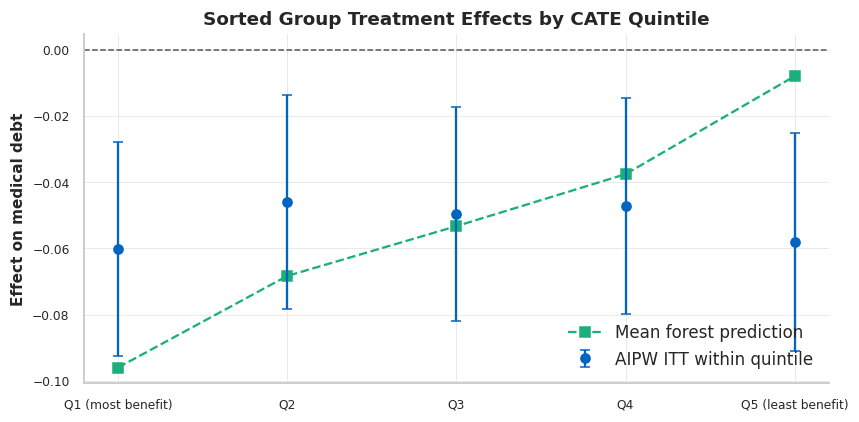

In [461]:
# Now, lets compare the forest's predicted effect to the actual (AIPW) effect within each quintile
fig, ax = plt.subplots(figsize = (8, 4))
x = np.arange(len(gates))
# Plot the predicted CATE for each quintile
ax.plot(x, gates["Mean Predicted CATE"], marker = "s", linestyle = "--", color = COLORS["secondary"], label = "Mean forest prediction")
# Now, plot the actual (AIPW) for each quintile, to see if it aligns with the predicted CATE
ax.errorbar(x, gates["ITT (AIPW)"], yerr = 1.96 * gates["SE"], fmt = "o", capsize = 3, color = COLORS["primary"], label = "AIPW ITT within quintile")
# Add a reference line at zero (no effect)
ax.axhline(0, linestyle = "--", color = COLORS["reference"], linewidth = 1.0)
ax.set_xticks(x)
ax.set_xticklabels(gates.index, fontsize = 8)
ax.set_ylabel("Effect on medical debt")
ax.set_title("Sorted Group Treatment Effects by CATE Quintile")
ax.legend()
plt.tight_layout()
fig.savefig(f"{OUTPUT}/cate_calibration.png")
plt.show()

The calibration test found no evidence that the forest's predicted heterogeneity is real. If the forest's ranking were accurate, the people it predicts to benefit more would actually benefit more, but since the test coefficient is -0.08 (p = 0.73), they do not appear to. The sorted-group effects confirm this. Splitting respondents into five groups by predicted effect, the forest expected -9.6 percentage points for the top group and -0.8 percentage points for the bottom. The AIPW estimates for the same groups are -6.0 and -5.8, with groups falling between -4.6 and -6.0 with no clear ordering.

### 8.4. Subgroup Analysis: Age Group, Sex, Language, Prior SNAP/TANF

In [462]:
# Estimate the ITT within each prespecified subgroup by averaging the AIPW scores over its members
# Note: To learn how to run a subgroup analysis from AIPW scores
    # Claude Fable 5. Based on the response to the prompt: "How can I estimate and test subgroup-specific treatment effects using the AIPW scores from earlier?"
sub_df = df.loc[fit_data]
rows = []
for s in subgroups:
    for level in sorted(sub_df[s].unique()):
        m = (sub_df[s] == level).to_numpy()
        # Survey-weighted mean of the AIPW scores within the subgroup, with household-clustered SE
        est, se = clustered_se(psi_primary[m], w_c[m], groups_fit.to_numpy()[m])
        rows.append({
            "Subgroup": labels[s],
            "Level": level,
            "n": m.sum(),
            "ITT (AIPW)": est,
            "SE": se,
            "CI Low": est - 1.96 * se,
            "CI High": est + 1.96 * se
        })

# One group per subgroup level
subgroup_effects = pd.DataFrame(rows).set_index(["Subgroup", "Level"])
subgroup_effects.round(4)

n  ITT (AIPW)      SE  \
Subgroup                         Level                                     
Age group                        18-34          7205     -0.0522  0.0136   
                                 35-49          8496     -0.0563  0.0124   
                                 50-64          7749     -0.0476  0.0130   
Prior SNAP or TANF participation No SNAP/TANF  10542     -0.0336  0.0115   
                                 SNAP/TANF     12908     -0.0675  0.0100   
Sex                              Female        13896     -0.0586  0.0094   
                                 Male           9554     -0.0433  0.0118   
Language preference              English       21487     -0.0572  0.0079   
                                 Non-English    1963     -0.0002  0.0268   

                                               CI Low  CI High  
Subgroup                         Level                          
Age group                        18-34        -0.0788  -0.0257  
                                 35-49        -0.0806  -0.0320  
                                 50-64        -0.0731  -0.0220  
Prior SNAP or TANF participation No SNAP/TANF -0.0561  -0.0111  
                                 SNAP/TANF    -0.0870  -0.0480  
Sex                              Female       -0.0769  -0.0402  
                                 Male         -0.0665  -0.0201  
Language preference              English      -0.0727  -0.0418  
                                 Non-English  -0.0526   0.0523

In [463]:
# Now, test whether the effect differs across levels of each subgroup variables
rows = []
for s in subgroups:
    # Build a small frame with each respondents AIPW score (psi), survey weight, household id, and subgroup level
    d = pd.DataFrame({"psi": psi_primary, "w": w_c, "g": groups_fit.to_numpy(), s: sub_df[s].to_numpy()})
    # Perform weighted regression of the AIPW scores on the subgroup levels, using household-clustered SE
    m = smf.wls(f"psi ~ C({s})", data = d, weights = d["w"]).fit(cov_type = "cluster", cov_kwds = {"groups": d["g"]})
    terms = [t for t in m.params.index if t.startswith(f"C({s})")]
    # Perform wald test to check whether the effect is the same across all levels
    wald = m.wald_test(" = ".join(terms) + " = 0", scalar = True) if len(terms) > 1 else m.wald_test(f"{terms[0]} = 0", scalar = True)
    rows.append({
        "Subgroup": labels[s],
        "Levels": d[s].nunique(),
        "Wald Stat": float(wald.statistic),
        "p": float(wald.pvalue)
    })

subgroup_tests = pd.DataFrame(rows).set_index("Subgroup")
subgroup_tests.round(4)

,Levels,Wald Stat,p
Subgroup,,,
Age group,3,0.2392,0.8873
Prior SNAP or TANF participation,2,4.9900,0.0255
Sex,2,1.0741,0.3000
Language preference,2,4.1937,0.0406


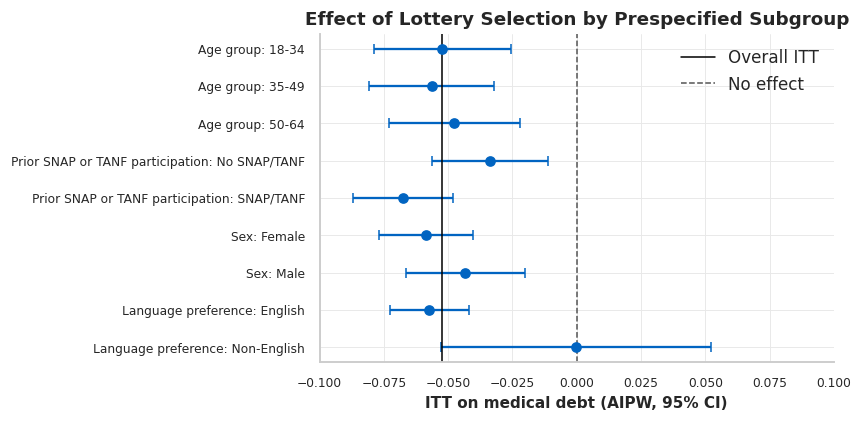

In [464]:
# Forest plot of the subgroup ITTs
fig, ax = plt.subplots(figsize = (8, 4))
ypos = np.arange(len(subgroup_effects))
ax.errorbar(subgroup_effects["ITT (AIPW)"], ypos, xerr = 1.96 * subgroup_effects["SE"], fmt = "o", capsize = 3, color = COLORS["primary"])
# Add a reference line for the overall ITT, to see how each specific subgroups compare to the overall
ax.axvline(itt.loc[outcome, "ITT"], color = "black", linewidth = 1.0, label = "Overall ITT")
# Add a reference line at zero (no effect)
ax.axvline(0, linestyle = "--", color = COLORS["reference"], linewidth = 1.0, label = "No effect")
ax.set_yticks(ypos)
# Lets label each row as "Subgroup: level"
ax.set_yticklabels([textwrap.fill(f"{s}: {l}", width = 60) for s, l in subgroup_effects.index], fontsize = 8)
ax.invert_yaxis()
# Lets center the plot around zero, so the direction of the effect is obvious
ax.set_xlim(-0.1, 0.1)
ax.set_xlabel("ITT on medical debt (AIPW, 95% CI)")
ax.set_title("Effect of Lottery Selection by Prespecified Subgroup")
ax.legend()
plt.tight_layout()
fig.savefig(f"{OUTPUT}/itt_subgroup_analysis.png")
plt.show()

Effects are relatively similar across age groups (-4.7 to -5.6 percentage points, p = 0.8873) and between women and men (-5.8 and -4.3 percentage points respectively, p = 0.3000). Respondents with prior SNAP or TANF participation show -6.7 percentage points against -3.4 for those without (difference of 3.3 percentage points, p = 0.0255), indicating that the offer has a larger effect among those with previous experiences in safety net programs. This could also be a result of these respondents being systematically more likely to enroll in the program if offered. Respondents with an English language preference showed -5.7 percentage points against about zero for non-English preference (p = 0.0406), but the non-English group is small and its confidence interval covers the overall effect. With that said, neither difference survives a Bonferroni correction across four tests, so both are suggestive rather than confirmatory. The prior SNAP/TANF difference is the main one with a policy reading, and motivates the need-based rule in *Section 9*.

### 8.5. Forest Feature Importance

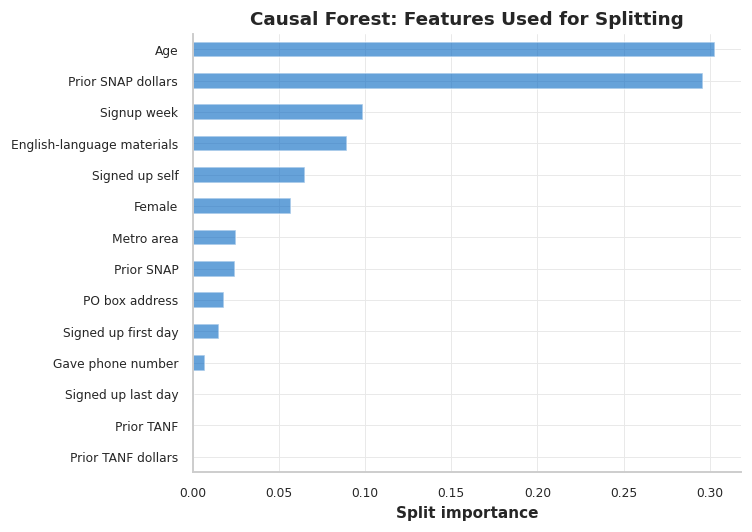

In [465]:
# Now, lets check which features the forest split on most
forest_importance = pd.Series(np.mean([f.feature_importances_ for f in forest_models], axis = 0), index = X_het.columns).sort_values(ascending = False)
fig, ax = plt.subplots(figsize = (7, 5))
forest_importance.rename(index = labels).plot.barh(ax = ax, alpha = 0.6)
# Lets place the largest forest feature importance at the top
ax.invert_yaxis()
ax.set_xlabel("Split importance")
ax.set_title("Causal Forest: Features Used for Splitting")
plt.tight_layout()
fig.savefig(f"{OUTPUT}/causal_forest_features.png")
plt.show()

The forest split most often on age (0.30) and the total household dollar benefits from SNAP (0.30), followed at a distance by signup week (0.10), English language preference (0.09), self signup (0.07), and sex (0.06). The two leading features are both continuous, which offer more potential split points than the binary variables.

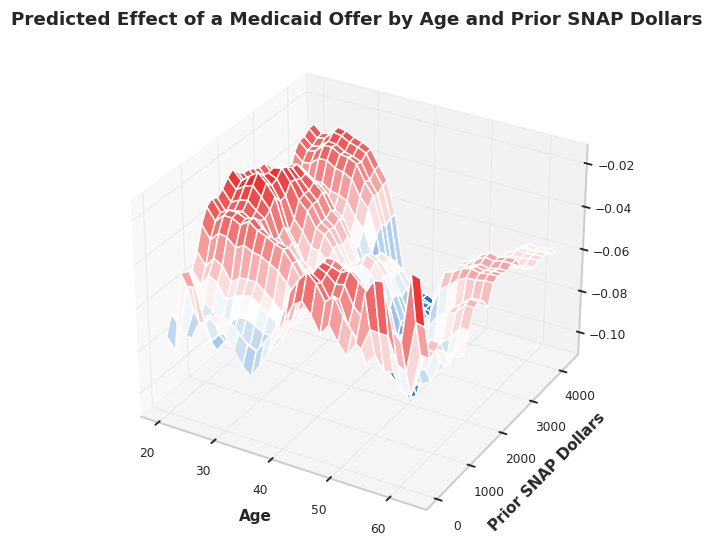

In [466]:
# Note: To learn how to plot a causal forest's predicted effects as a surface plot
  # Claude Fable 5. Based on the response to the prompt: "How can I show the causal forest's predicted CATE as a surface plot over its two most important features?"
# Next, lets build a grid over the two most important forest features, age and prior SNAP dollars
age_grid = np.linspace(X_het["age"].min(), X_het["age"].max(), 30)
snap_grid = np.linspace(0, X_het["snap_dollars_pre"].quantile(0.95), 30)
# Now, pair every age value with every SNAP value
age_mesh, snap_mesh = np.meshgrid(age_grid, snap_grid)
grid = pd.DataFrame([X_het.median()] * age_mesh.size)
grid["age"] = age_mesh.ravel()
grid["snap_dollars_pre"] = snap_mesh.ravel()

# Predict the CATE at each point with each of the five fold forests, then average them
cate_surface = np.mean([f.predict(grid).ravel() for f in forest_models], axis = 0).reshape(age_mesh.shape)

# Now, plot the surface
fig = plt.figure(figsize = (8, 6))
ax = fig.add_subplot(projection = "3d")
ax.plot_surface(age_mesh, snap_mesh, cate_surface, cmap = COLORMAP)
ax.set_xlabel("Age")
ax.set_ylabel("Prior SNAP Dollars")
ax.set_title("Predicted Effect of a Medicaid Offer by Age and Prior SNAP Dollars")
fig.savefig(f"{OUTPUT}/cate_surface.png")
plt.show()

The predicted effect is negative everywhere on the grid, so the forest expected an offer to reduce medical debt for every combination of age and prior SNAP dollars. The effect appears to shrink with age and increase with prior SNAP dollars.

## 9. Policy Simulation

---

Asks who should receive an offer if the program can only cover part of the population. The budget is fixed at the same share the actually lottery offered, and five rules (lottery, need-based, risk-based, benefit-based, universal) are scored with the same AIPW scores from *Section 7*, cross-checked with g-computation, and given confidence intervals by a household bootstrap. The rules are then compared across budget levels of 10% to 90%, and then breaks down who receives offers under each allocation rule.

---

This section includes:

- 9.1. Determine Fixed Budget
- 9.2. Allocation Rules: Lottery, Need-Based, Risk-Based, Universal
- 9.3. Doubly Robust Evaluation of Each Rule using AIPW
- 9.4. G-Computation Cross-Check
- 9.5. Household Bootstrap for Uncertainty Estimation
- 9.6. Budget Sweep & Summary
- 9.7. Subgroup Analysis of Allocation Rules

### 9.1. Determine Fixed Budget

In [467]:
# First, we need to fix a budget at the share of the list that the actual lottery offered, so that every rule hands out the same amoutn of offers
# and are therefore directly comparable
# Note: To learn how to setup and evaluate allocation rules using double robust scores
    # Claude Fable 5. Based on the response to the prompt: "How can I simulate alternative Medicaid allocation rules at a fixed budgetand evaluate them using the AIPW scores?"
budget = np.average(t_c, weights = w_c)
n_offers = int(round(budget * len(t_c)))
print(f"Budget: {budget:.3f} of the list, {n_offers} offers out of {len(t_c)} respondents")

# Expected debt rate if no one were offered coverage
baseline_debt = np.average(gamma0_primary, weights = w_c)
print(f"Expected medical debt rate with no offers: {baseline_debt:.4f}")

# Expected debt rate uses gamma1 for those offered and gamm0 for those not
# Debt averted is the weighted mean of d * psi, which counts each offered person's effect and zeroes out everyone not offered, so that
# offers to the same number of people are directly comparable
def evaluate_rule(d):
    debt_rate = np.average(d * gamma1_primary + (1 - d) * gamma0_primary, weights = w_c)
    averted, averted_se = clustered_se(d * psi_primary, w_c, groups_fit.to_numpy())
    return debt_rate, averted, averted_se

# Rank and offer to the n_offers respondents with the highest score, breaking ties at random
def allocate(score, n_offers, seed = SEED):
    rng = np.random.default_rng(seed)
    order = np.lexsort((rng.random(len(score)), -score))
    d = np.zeros(len(score))
    d[order[:n_offers]] = 1
    return d

Budget: 0.501 of the list, 11747 offers out of 23450 respondents
Expected medical debt rate with no offers: 0.5912


### 9.2. Allocation Rules: Lottery, Need-Based, Risk-Based, Universal

In [468]:
# Now, decide who gets an offer under each rule
scores = {}

# Random lottery, reproducing the original OHIE design
scores["Lottery"] = np.random.default_rng(SEED).random(len(t_c))

# Need-based, using prior SNAP / TANF dollars (a proxy for financial need)
scores["Need-based"] = (df.loc[fit_data, "snap_dollars_pre"] + df.loc[fit_data, "tanf_dollars_pre"]).to_numpy()

# Risk-based, predicting probability of medical debt without coverage, from the out-of-fold XGBoost models fitted in section 6 earlier
risk = np.full(len(t_c), np.nan)
X_risk = X_fit.copy()
# Set treatmetn to 0 so that the prediction reflects the baseline risk, not the effect of an offer
X_risk[treatment] = 0
# Use the out-of-fold XGBoost predictions from the household folds
for (train, test), model in zip(folds, fold_models["xgboost"]):
    risk[test] = model.predict_proba(X_risk.iloc[test])[:, 1]
scores["Risk-based"] = risk

# Benefit-based, using the causla forests predicted individual effect
scores["Benefit-based"] = -cate

# Allocate n_offers under each rule, then add the unverisal rule (everyone recieves an offer)
allocations = {name: allocate(s, n_offers) for name, s in scores.items()}
allocations["Universal"] = np.ones(len(t_c))

# Confirm every budget rule hands out the same number of offers
pd.DataFrame({name: d.sum() for name, d in allocations.items()}, index = ["Offers"]).T

,Offers
Lottery,11747.0
Need-based,11747.0
Risk-based,11747.0
Benefit-based,11747.0
Universal,23450.0


### 9.3. Doubly Robust Evaluation of Each Rule using AIPW

In [469]:
# Evaluate each allocation with the doubly robust scores
rows = []
for name, d in allocations.items():
    # For every rule, evaluate_rule() returns the expected debt rate under that allocation, the debt averted, and SE
    debt_rate, averted, averted_se = evaluate_rule(d)
    rows.append({
        "Rule": name,
        "Offers": int(d.sum()),
        "Expected Debt Rate": debt_rate,
        "Debt Averted": -averted,
        "SE": averted_se,
        "CI Low": -averted - 1.96 * averted_se,
        "CI High": -averted + 1.96 * averted_se
    })

# One row per rule
policy_results = pd.DataFrame(rows).set_index("Rule")
# Gain over the lottery (the original OHIE design) at the same budget
policy_results["Gain vs Lottery"] = policy_results["Debt Averted"] - policy_results.loc["Lottery", "Debt Averted"]
policy_results.round(4)

,Offers,Expected Debt Rate,Debt Averted,SE,CI Low,CI High,Gain vs Lottery
Rule,,,,,,,
Lottery,11747,0.5654,0.0258,0.0053,0.0155,0.0362,0.0000
Need-based,11747,0.5587,0.0325,0.0053,0.0222,0.0428,0.0066
Risk-based,11747,0.5572,0.0341,0.0051,0.0241,0.0440,0.0082
Benefit-based,11747,0.5648,0.0264,0.0053,0.0160,0.0368,0.0005
Universal,23450,0.5390,0.0522,0.0075,0.0374,0.0670,0.0264


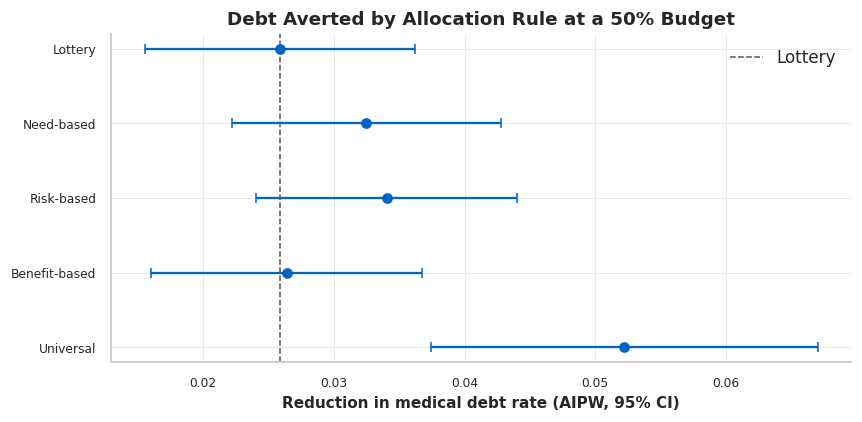

In [470]:
# Forest plot of debt averted by rule
fig, ax = plt.subplots(figsize = (8, 4))
ypos = np.arange(len(policy_results))
ax.errorbar(policy_results["Debt Averted"], ypos, xerr = 1.96 * policy_results["SE"], fmt = "o", capsize = 3)
# Add the original lottery estimate as the reference line
ax.axvline(policy_results.loc["Lottery", "Debt Averted"], linestyle = "--", color = COLORS["reference"], linewidth = 1.0, label = "Lottery")
ax.set_yticks(ypos)
ax.set_yticklabels(policy_results.index)
ax.invert_yaxis()
ax.set_xlabel("Reduction in medical debt rate (AIPW, 95% CI)")
ax.set_title(f"Debt Averted by Allocation Rule at a {budget:.0%} Budget")
ax.legend()
plt.tight_layout()
fig.savefig(f"{OUTPUT}/allocation_rule_at_50.png")
plt.show()

With half of the list being offered coverage, the lottery averts 2.6 percentage points of medical debt, half the full ITT, as expected from random allocation. Risk-based allocation averts 3.4 points, need-based 3.3, and benefit-based 2.6, against a ceiling of 5.2 if everyone were offered coverage. In relative terms, the risk-based rule averts about 30% more debt than the lottery for the same number of offers, while the need-based averts about 25% more.

Prior SNAP/TANF benefit recipient, which drives the need-based rule, is the strongest predictor of medical debt and marks the subgroup with the largest treatment effect identified in *Section 8*. The risk-based rule adds language, sex, and the remaining predictors to that signal and steers offers away from those unlikely to incur medical debt without coverage, which gives it a slight edge. Meanwhile, the benefit-based, which ranks respondents by the causal forest's predicted individual effect, averts debt by 2.6 points, which is no better than the lottery.



### 9.4. G-Computation Cross-Check

In [471]:
# Re-evaluate each rule using only the g-computation outcome models, as a cross-check on the AIPW evaluation
# Calculate each respondents predicted effect from the two XGBoost arm models
# Note: g-computation does not have corrections from observed outcomes, like AIPW has
tau_gcomp = mu1_p - mu0_p
policy_results["Debt Averted (g-comp)"] = [-np.average(d * tau_gcomp, weights = w_c) for d in allocations.values()]
policy_results[["Debt Averted", "Debt Averted (g-comp)"]].round(4)

,Debt Averted,Debt Averted (g-comp)
Rule,,
Lottery,0.0258,0.0288
Need-based,0.0325,0.0351
Risk-based,0.0341,0.0388
Benefit-based,0.0264,0.0403
Universal,0.0522,0.0562


The g-computation evaluation agrees with AIPW for the lottery, need-based, risk-based, and universal rules, within 0.5 percentage points in each case. However, it disagrees for the benefit-based rule, where it computed 4.0 percentage points compared to AIPW's 2.6. The CATE and g-computation approaches are built from the same outcome models, so it is expected that the two would align. With that said, AIPW corrects for the outcome models using observed outcomes, and is therefore a more robust and trustworthy estimate.

### 9.5. Household Bootstrap for Uncertainty Estimation

In [472]:
# Now, perform household bootstrapping for the uncertainty of each rules gain over the lottery
# Note: To learn how to bootstrap the difference between allocation rules
    # Claude Fable 5. Based on the response to the prompt: "How can I get a confidence interval for each rule's gain over the lottery?"
# Each respondents weighted contribution to debt averted under each rule
hh = groups_fit.to_numpy()
contribution = pd.DataFrame({name: -d * psi_primary * w_c for name, d in allocations.items()})
# Replace the single random lottery draw with its expected value (aka the lottery)
contribution["Lottery"] = -budget * psi_primary * w_c
contribution["w"] = w_c
contribution["hh"] = hh
# Sum the contributions within the household, so the bootstrap can resample whole households
hh_sums = contribution.groupby("hh").sum()

# Resample households with replacement 1000 times, recomputing each rules gain over the lottery for each draw
rng = np.random.default_rng(SEED)
n_boot = 1000
rule_names = list(allocations.keys())
boot = np.zeros((n_boot, len(rule_names)))
for b in range(n_boot):
    idx = rng.integers(0, len(hh_sums), size = len(hh_sums))
    s = hh_sums.iloc[idx].sum()
    # Weighted mean debt averted per rule on this draw
    averted = s[rule_names] / s["w"]
    boot[b] = averted - averted["Lottery"]

# Point estimate from earlier, with bootstrap SE and 95% CI
gain = pd.DataFrame({
    "Gain vs Lottery": policy_results.loc[rule_names, "Gain vs Lottery"],
    "Boot SE": boot.std(axis = 0),
    "CI Low": np.percentile(boot, 2.5, axis = 0),
    "CI High": np.percentile(boot, 97.5, axis = 0)
}, index = rule_names)

gain.round(4)

,Gain vs Lottery,Boot SE,CI Low,CI High
Lottery,0.0000,0.0000,0.0000,0.0000
Need-based,0.0066,0.0037,-0.0005,0.0137
Risk-based,0.0082,0.0037,0.0007,0.0152
Benefit-based,0.0005,0.0037,-0.0071,0.0074
Universal,0.0264,0.0038,0.0187,0.0338


The household bootstrap gives the uncertainty in each rule's gain over the lottery. The risk-based rule's gain of 0.8 percentage points is statistically significant (95% CI: 0.1 to 1.5). The need-based rule's gain of 0.7 percentage points is borderline (95% CI: -0.01 to 1.4). The benefit-based rule's gain is approximately zero (95% CI: -0.7 to 0.7), and the universal rule's gain is 2.6 percentage points (95% CI: 1.9 to 3.4).

### 9.6. Budget Sweep & Summary

In [473]:
# Now, repeat the evaluation across budgets from 10% to 100%
# Note: To learn how to sweep the allocation budget
    # Claude Fable 5. Based on the response to the prompt: "How can I compare the allocation rules across a range of budgets rather than only at a static 50%?"
# Set the range from 10% to 100%, in increments of 10%
budgets = np.arange(0.1, 1.01, 0.1)
rows = []
for b in budgets:
    # Number of offers at this budget
    k = int(round(b * len(t_c)))
    # Reallocate and reevaluate each scoreed rule at k offers
    for name, s in scores.items():
        if name in ["Lottery", "Universal"]:
            continue
        d = allocate(s, k)
        _, averted, _ = evaluate_rule(d)
        rows.append({
            "Budget": b,
            "Rule": name,
            "Debt Averted": -averted
        })
    # Lottery baseline as the expected value
    rows.append({
        "Budget": b,
        "Rule": "Lottery (expected)",
        "Debt Averted": -b * np.average(psi_primary, weights = w_c)
    })

# One row per budget by rule
sweep = pd.DataFrame(rows)

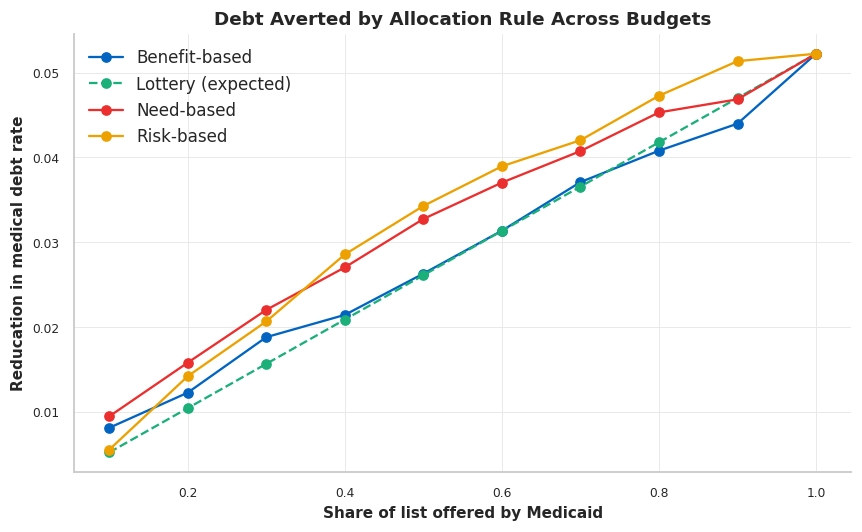

In [474]:
# Plot the debt averted against budget for each rule
fig, ax = plt.subplots(figsize = (8, 5))
for name, g in sweep.groupby("Rule"):
    # Use a dashed line for the expected lottery, as the reference
    style = "--" if name.startswith("Lottery") else "-"
    ax.plot(g["Budget"], g["Debt Averted"], marker = "o", linestyle = style, label = name)
ax.set_xlabel("Share of list offered by Medicaid")
ax.set_ylabel("Reducation in medical debt rate")
ax.set_title("Debt Averted by Allocation Rule Across Budgets")
ax.legend()
plt.tight_layout()
fig.savefig(f"{OUTPUT}/allocation_rule_across_budgets.png")
plt.show()

Across budgets, the ranking of rules depends on how scarce offers are. At the smallest budgets (10% to 30%), the need-based rule averts the most debt at about 0.9 percentage points at 10% budget compared to 0.5 for the lottery. This is likely because prior SNAP/TANF benefit recipient identifies the highest-need respondents most cleanly and the first offers go to them. From 40% onward, the risk-based rule takes over and stays slightly ahead until the curves converge at 100% where every rule offers to everyone and averts the full 5.2 points. Notably, the need-based rule sits above the lottery line at every budget from 10% to 80%, which provides stronger evidence for it than the borderline single-budget test conducted in *Section 9.5*. The benefit-based rule tracks the lottery line throughout.

With that said, there are a few cautions and limitations to consider. The curves at the small budgets rest on few offers and differences of a few tenths of a point there could be noise. And every rule here allocates offers, not coverage: only 29% of those offered enrolled, so a rule's value depends as much on whether the targets take up the offer as on whether they would benefit from it.

### 9.7. Subgroup Analysis of Allocation Rules

In [475]:
# Next, lets check how the offers are distribution under each rule, based on subgroups
# Note: To learn how to summarize the subgroup and distributional consequences of each allocation rule
    # Claude Fable 5. Based on the response to the prompt: "How can I show which subgroups are most impacted by each allocation rule?"
rows = []
for subgroup in subgroups:
    for level in sorted(sub_df[subgroup].unique()):
        m = (sub_df[subgroup] == level).to_numpy()
        # Survey-weighted share of the list in this group
        row = {
            "Subgroup": labels[subgroup],
            "Level": level,
            "Share of List": np.average(m, weights = w_c)
        }
        for name, d in allocations.items():
            # Weighted share of this rules offers that go to this group
            row[name] = np.average(m, weights = w_c * d)
        rows.append(row)

# One row per subgroup level, one column per rule
offer_composition = pd.DataFrame(rows).set_index(["Subgroup", "Level"])
offer_composition.round(3)

Share of List  Lottery  \
Subgroup                         Level                                  
Age group                        18-34                 0.322    0.323   
                                 35-49                 0.363    0.364   
                                 50-64                 0.315    0.313   
Prior SNAP or TANF participation No SNAP/TANF          0.451    0.450   
                                 SNAP/TANF             0.549    0.550   
Sex                              Female                0.586    0.592   
                                 Male                  0.414    0.408   
Language preference              English               0.912    0.915   
                                 Non-English           0.088    0.085   

                                               Need-based  Risk-based  \
Subgroup                         Level                                  
Age group                        18-34              0.324       0.295   
                                 35-49              0.397       0.459   
                                 50-64              0.280       0.246   
Prior SNAP or TANF participation No SNAP/TANF       0.043       0.124   
                                 SNAP/TANF          0.957       0.876   
Sex                              Female             0.603       0.701   
                                 Male               0.397       0.299   
Language preference              English            0.938       0.998   
                                 Non-English        0.062       0.002   

                                               Benefit-based  Universal  
Subgroup                         Level                                   
Age group                        18-34                 0.347      0.322  
                                 35-49                 0.376      0.363  
                                 50-64                 0.277      0.315  
Prior SNAP or TANF participation No SNAP/TANF          0.305      0.451  
                                 SNAP/TANF             0.695      0.549  
Sex                              Female                0.634      0.586  
                                 Male                  0.366      0.414  
Language preference              English               0.957      0.912  
                                 Non-English           0.043      0.088

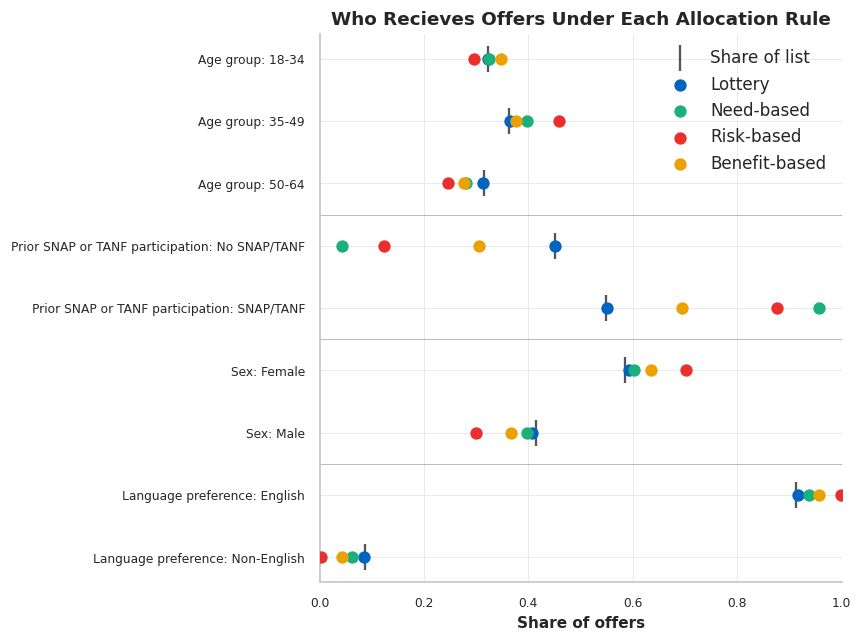

In [476]:
# Lets create a dot plot to visualize how each rules share of offers compares for each subgroup level
# Lets omit the unverisal rule, since it includes every individual across every subgroup
plot_rules = [r for r in allocations if r != "Universal"]
comp = offer_composition.reset_index()
comp["Label"] = comp["Subgroup"] + ": " + comp["Level"].astype(str)
ypos = np.arange(len(comp))

fig, ax = plt.subplots(figsize = (8, 6))
# Make population share as the reference tick per row
ax.scatter(comp["Share of List"], ypos, marker = "|", s = 300, color = COLORS["reference"], zorder = 2, label = "Share of list")
# One marker per rule
for rule, color in zip(plot_rules, PALETTE):
    ax.scatter(comp[rule], ypos, color = color, s = 50, zorder = 3, label = rule)
ax.set_yticks(ypos, comp["Label"])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Share of offers")
ax.set_title("Who Recieves Offers Under Each Allocation Rule")
# Add light separators between subgroup blocks
for i in range(1, len(comp)):
    if comp["Subgroup"].iloc[i] != comp["Subgroup"].iloc[i - 1]:
        ax.axhline(i - 0.5, color = COLORS["reference"], linewidth = 0.5, alpha = 0.5)
ax.legend(loc = "upper right")
plt.tight_layout()
fig.savefig(f"{OUTPUT}/offer_subgroup_composition.png")
plt.show()

The lottery matches the composition of the list on every dimension, as expected from random allocation. Need-based is effectively a single-variable rule. It sends 96% of offers to prior SNAP/TANF participants, who make up 55% of the list, and otherwise tracks the population on age, sex and language preference. Its gain over the lottery comes almost entirely from concentrating offers on prior benefit recipients. Risk-based shifts the pool across almost every dimension. Prior SNAP/TANF participants receive 88% of offers (compared to 55% of the list), women 70% (compared to 59% of the list), and the 35 to 49 age group 46% (compared to 36% of the list), while 50 to 64 share falls from 32% to 25%. The largest shift is language preference, where non-English speakers are 8.8% of the list and recieve 0.2% of the risk-based offers. The rule that averts the most debt per offer (risk-based) does so partly by excluding one group almost entirely. Benefit-based sits between the two, with milder shifts in the same directions (70% SNAP/TANF participants, 63% women, 4.3% non-English speakers).

## 10. Summary & Limitations

---

Summarizes the key findings and results, lists the assumptions each estimate relies on, states the limitations of this analysis, and ends with a concise conclusion for the analysis.

---

This selection includes:

  - 10.1. Results
  - 10.2. Assumptions
  - 10.3. Limitations
  - 10.4. Conclusions

### 10.1. Results

Winning the Medicaid lottery reduced the probability of owing money for medical expenses at 12 months by 5.2 percentage points (SE 0.8), from 59.7% among non-winners to 53.8% among winners. The three secondary outcomes moved the same way: borrowing or skipping bills fell by 4.5 percentage points, being refused care for past debt by 1.0 percentage point, and any out-of-pocket spending by 5.9 percentage points. Weighted OLS, g-computation, and AIPW gave the same answer within 0.1 percentage point, and the estimates match the published OHIE result. Among compliers, enrollment itself reduced medical debt by 18.0 percentage points, about three and a half times the offer effect, since only 29% of winners enrolled.

Pre-lottery characteristics predict medical debt weakly. All three classifiers reached an AUC of about 0.60 with well-calibrated probabilities. Prior SNAP participation, English-language preference, and female sex were the strongest predictors.

The causal forest found no reliable heterogeneity. Its predicted effects ranged from -21 to +7 percentage points, but the calibration test could not distinguish that spread from noise (coefficient -0.08, p = 0.73), and the actual effect within each predicted-effect quintile was flat at -4 to -6 percentage points. Prespecified subgroups told a similar story: effects were similar across age groups and between women and men, somewhat larger for prior SNAP/TANF participants (-6.7 vs -3.4 percentage points, p = 0.03), and near zero for the non-English speaking group, with neither difference surviving significance after a Bonferroni correction.

In the policy simulation, holding offers fixed at the lottery's 50% budget, risk-based allocation averted 3.4 percentage points of medical debt, need-based 3.3, the lottery 2.6, and benefit-based 2.6, against a ceiling of 5.2 if everyone were offered. The risk-based gain over the lottery of 0.8 points was statistically significant (95% CI 0.1 to 1.5). The need-based gain of 0.7 was borderline (95% CI -0.1 to 1.4), but held at every budget from 10% to 80%. Need-based led budgets up to 30% and risk-based above 40%. The gains came with clear distributional shifts: need-based sent 96% of offers to prior SNAP/TANF participants, and risk-based sent 0.2% of offers to non-English speakers, who make up 8.8% of the list.

### 10.2. Assumptions

The causal estimates rest on the lottery design. Within each household-size by wave cell, winning is assumed to be independent of potential outcomes (exchangeability), which the design guarentees and the balance check in *Section 7.2* supports, and every cell is assumed to contain both winners and non-winners (positivity), which *Section 7.1* confirms. The LATE additionally assumes that winning the lottery affected medical debt only through enrollemnt (exclusion) and that no one enrolled because they lost (monotonicity). G-computation assumes the outcome models are correctly specified. AIPW relaxes this assumption to either the outcome models or the propensity score beign correct, and the propensity score here is known due to the randomized lottery design. The policy simulation assumes that each person's effect of an offer would be the same under a different allocation rule as under the lottery, and that take-up would not change when the rule changes.

### 10.3. Limitations

First, the simulation allocates offers, not coverage. Only 29% of those offered enrolled, so a rule's realized value depends as much on whether its targets take up the offer as on whether they would benefit. A future direction would be to model the take-up and compliance differences between subgroups and allocation rules. Second, the predictors are limited to what was recorded at signup. Health status, income, and existing debt, which likely drive medical debt, are absent, which caps the classifiers at an AUC of 0.60 and limits what any targeting rule built on them can achieve. Third, the forest found nothing the calibration test could confirm, and the two subgroup differences are suggestive at best, so the benefit-based rule had no real signal to work with. Fourth, the data come from one state (Oregon) in 2008, before the ACA Medicaid expansion, and the lottery population was specific to low-income uninsured adults who chose to sign up. The findings describe that setting and should not be directed as estimates for other states, time periods, or populations.

### 10.4. Conclusions

A Medicaid offer reduced medical debt by about 5 percentage points, and enrollment by about 18, consistent with the original OHIE findings. A simple need-based rule using prior SNAP/TANF benefit dollar amount and a risk-based rule using predicted debt both beat random allocation (by 0.7 and 0.8 percentage points, respectively) at the 50% budget, while a rule built on the causal forest's individual predictions did not. The budget itself mattered more than the rule, where offering coverage to everyone averted 5.2 percentage points, against 3.4 for the best targeted rule at the 50% budget.

Targeting on observable need is transparent and nearly as effective as a predictive model, and it concentrates offers on prior benefit recipients, a group a program may already intend to prioritize. The predictive rule's larger gain comes partly from excluding non-English speakers and older adults, a trade-off and ethical consideration that a program would need to justify or constrain. Because a declined offer costs nothing, so take-up matters as much as who recieves an offer. With only 29% of winners enrolling, efforts to raise enrollment among those already offered may avert as much additional debt as changing the allocation rule, which is worth examining as a future direction.

## References
---

- *Finkelstein, Amy. Oregon Health Insurance Experiment Public Use Data, 2013. Available at https://www.nber.org/research/data/oregon-health-insurance-experiment-data.*
- *Finkelstein, Amy et al. “THE OREGON HEALTH INSURANCE EXPERIMENT: EVIDENCE FROM THE FIRST YEAR.” The quarterly journal of economics vol. 127,3 (2012): 1057-1106. doi:10.1093/qje/qjs020*
- *Dr. Jamie Fairclough. Dartmouth Programming_Additional Code (Adv Stats & Machine Learning).ipynb. Geisel School of Medicine at Dartmouth.*
- *Rosenbaum, Paul R., and Donald B. Rubin. The Central Role of the Propensity Score in Observational Studies for Causal Effects. n.d.*
- *Austin, Peter C. “An Introduction to Propensity Score Methods for Reducing the Effects of Confounding in Observational Studies.” Multivariate behavioral research vol. 46,3 (2011): 399-424. doi:10.1080/00273171.2011.568786. https://pmc.ncbi.nlm.nih.gov/articles/PMC3144483/*
- *Hernán MA, Robins JM (2020). Causal Inference: What If. Boca Raton: Chapman & Hall/CRC. https://miguelhernan.org/whatifbook*
- *Mustafa, Akif. “A Short Introduction to G-Computation in Causal Inference.” Medium, September 2, 2025. https://medium.com/@akif.iips/a-short-introduction-to-g-computation-in-causal-inference-9a67bd9e2233.*
- *Luharuka, Shubham. “Understanding Augmented Inverse Propensity Weighting (AIPW) in Causal Inference.” Medium, January 21, 2026. https://luharuka.medium.com/understanding-augmented-inverse-propensity-weighting-aipw-in-causal-inference-c724b1e14973.*
- *Matteo Courthoud. “Understanding AIPW.” July 10, 2023. https://matteocourthoud.github.io/post/aipw/.*
- *Van Vogt, Eleanor, Anthony C. Gordon, Karla Diaz-Ordaz, and Suzie Cro. “Application of Causal Forests to Randomised Controlled Trial Data to Identify Heterogeneous Treatment Effects: A Case Study.” BMC Medical Research Methodology 25 (February 2025): 50. https://doi.org/10.1186/s12874-025-02489-2.*
- *Claude Fable 5 (Anthropic). Used to understand and explain the propensity score and how the general definition reduces to the within-stratum offer rate used in this study.*
- *Claude Fable 5 (Anthropic). Used to understand and explain the intention-to-treat effect and how the OHIE regression equation relates to this study.*
- *Claude Fable 5 (Anthropic). Used to understand and explain the LATE and how the OHIE two-stage least squares specification applies to this study.*
- *Claude Fable 5 (Anthropic). Used to understand and explain g-computation and how the standard estimator extends to survey weights and per-arm models in this study.*
- *Claude Fable 5 (Anthropic). Used to understand and explain AIPW and how it extends to survey weights and the known design propensity score in this study.*
- *Claude Fable 5 (Anthropic). Used to understand and explain the causal forest and how the residualized, cross-fitted version in this study is set up.*


## AI Use Statement
---

Generative AI (Claude) was used as a coding, learning, and editing assistant for the following:

- Python syntax and package questions, such as reading Stata with pyreadstat, household-grouped cross-validation with GroupKFold, fitting 2SLS with linearmodels, and fitting causal forest with EconML.
- Brainstorming, implementing, and understanding supervised machine learning models (logistic regression, random forest, XGBoost), including hyperparameter tuning, threshold selection, calibration, variable importance (permutation importance, SHAP), and interpreting results.
- Brainstorming, implementing, and understanding causal inference methods (ITT via OLS, LATE via 2SLS, g-computation, AIPW), including design-based propensity score, survey weighting, household-clusters, and interpreting results.
- Brainstorming, implementing, and understanding heterogeneity analysis, including the cross-fitted causal forest, the calibration test and sorted-group effecta, and subgroup analysis from AIPW scores.
- Explaining the methods and mathematical notation for the propensity score, intention-to-treat regression, two-stage least squares, g-computation, AIPW, and causal forest.
- Brainstorming and editing notebook and README structure / contents, and learning reproducibility and automation best practices.


I verified and reviewed all work. I take full responsibility for the accuracy and legitimacy of all work submitted.